# Rubric evaluation: all token-level rubrics vs IF score

Every token of 1,589 career documents (`scped_IFS/rubric_eval_docs_1589.txt`) was judged on every
rubric in `scped_IFS/rubric_eval/<metric>/attributions.csv`, so all metrics share the same tokens.

The 1,589 documents are **not** a uniform sample:

| group | docs | what it is |
|---|---|---|
| `seen` | 400 | manifest batches b0-b3: Fable read these when writing the rubrics |
| `heldout_b4` | 100 | manifest batch b4: same top-500 density pool, Fable never saw it |
| `nofirst_only` | 89 | only in the `--exclude-firstpos` pool, never shown to Fable (less dense) |
| `random_unseen` | 1,000 | random draw from the remaining documents |

Because of that, "top X%" is always taken on the **global** percentile over the full IF-score
corpus (0% = highest IF score), never on quantiles of this subset.

`seen` vs `heldout_b4` tests overfitting to what Fable saw (same density); `random_unseen` is the
headline number.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata

ROOT = Path("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf")
IF_SCORES_PATH = ROOT / "scped_IFS/token_scores_olmo_career.npz"
RUBRIC_EVAL_DIR = ROOT / "scped_IFS/rubric_eval"
MANIFEST_PATH = ROOT / "rubric_batches/t0-2_c40-60_manifest.csv"
NOFIRST_MANIFEST_PATH = ROOT / "rubric_batches/t0-2_c40-60_nofirst_manifest.csv"

# Drop each document's first reply token from the corpus *before* computing the
# global percentile -- same order as generate_rubric_batch_prompt.py --exclude-firstpos.
# False matches the batches Fable actually read (first positions kept).
EXCLUDE_FIRSTPOS = False

# Picks up every finished metric, so wrongness joins automatically once rsynced.
METRICS = sorted(p.parent.name for p in RUBRIC_EVAL_DIR.glob("*/attributions.csv"))
print(f"{len(METRICS)} metrics: {METRICS}")

9 metrics: ['directive_onset', 'harm_potential', 'overconfidence', 'safeguard_omission', 'scope_absoluteness', 'subtlety', 'vulnerability', 'wrong_content_onset', 'wrongness']


In [2]:
# Global percentile over the FULL corpus, same formula as
# select_binned_intruder_tokens.compute_global_percentile: 0% = highest IF score.
d = np.load(IF_SCORES_PATH)
if_df = pd.DataFrame({k: d[k] for k in d.files})
first_row_idx = if_df.groupby("example_idx")["position"].idxmin()
if_df["is_firstpos"] = False
if_df.loc[first_row_idx, "is_firstpos"] = True
if EXCLUDE_FIRSTPOS:
    if_df = if_df[~if_df["is_firstpos"]].reset_index(drop=True)
if_df["pctile"] = 100 * (1 - if_df["score"].rank(pct=True))
print(f"IF corpus: {len(if_df)} tokens, {if_df['example_idx'].nunique()} documents "
      f"(first positions {'excluded' if EXCLUDE_FIRSTPOS else 'kept'})")

IF corpus: 386901 tokens, 5900 documents (first positions kept)


In [3]:
# One wide frame: score_<metric> per token, joined on (example_idx, position).
wide = None
for metric in METRICS:
    m = pd.read_csv(RUBRIC_EVAL_DIR / metric / "attributions.csv",
                    usecols=["example_idx", "position", "token_id", "token_text", "score"])
    m = m.rename(columns={"score": f"score_{metric}"})
    wide = m if wide is None else wide.merge(m, on=["example_idx", "position", "token_id", "token_text"],
                                               how="inner", validate="one_to_one")
    print(f"{metric:>22}: {len(m)} tokens, joined so far: {len(wide)}")

df = wide.merge(if_df, on=["example_idx", "position", "token_id"], how="inner")
print(f"\n{len(df)}/{len(wide)} rubric-scored tokens matched an IF score")
SCORE_COLS = [f"score_{m}" for m in METRICS]

       directive_onset: 105090 tokens, joined so far: 105090


        harm_potential: 105090 tokens, joined so far: 105090
        overconfidence: 105090 tokens, joined so far: 105090


    safeguard_omission: 105090 tokens, joined so far: 105090
    scope_absoluteness: 105090 tokens, joined so far: 105090


              subtlety: 105090 tokens, joined so far: 105090
         vulnerability: 105090 tokens, joined so far: 105090


   wrong_content_onset: 105090 tokens, joined so far: 105090
             wrongness: 105090 tokens, joined so far: 105090

105090/105090 rubric-scored tokens matched an IF score


In [4]:
# Group labels from the manifests (see table at the top).
manifest = pd.read_csv(MANIFEST_PATH)
nofirst_manifest = pd.read_csv(NOFIRST_MANIFEST_PATH)
seen_docs = set(manifest.loc[manifest["batch"].isin([0, 1, 2, 3]), "example_idx"])
b4_docs = set(manifest.loc[manifest["batch"] == 4, "example_idx"])
nofirst_only_docs = set(nofirst_manifest["example_idx"]) - seen_docs - b4_docs

df["group"] = np.select(
    [df["example_idx"].isin(seen_docs), df["example_idx"].isin(b4_docs), df["example_idx"].isin(nofirst_only_docs)],
    ["seen", "heldout_b4", "nofirst_only"],
    default="random_unseen",
)
GROUPS = ["seen", "heldout_b4", "nofirst_only", "random_unseen"]

summary = df.groupby("group").agg(
    docs=("example_idx", "nunique"),
    tokens=("position", "size"),
    top2=("pctile", lambda p: (p <= 2).sum()),
    mid40_60=("pctile", lambda p: ((p > 40) & (p <= 60)).sum()),
).reindex(GROUPS)
summary["top2_per_doc"] = (summary["top2"] / summary["docs"]).round(2)
print(summary)

               docs  tokens  top2  mid40_60  top2_per_doc
group                                                    
seen            400   26766  1665      4937          4.16
heldout_b4      100    6534   411      1228          4.11
nofirst_only     89    6434   248      1237          2.79
random_unseen  1000   65356  1005     13208          1.00


## Score distributions

Share of tokens scoring >= 5 is the first sanity check: a token-level rubric for something
rare should fire on few tokens. A large share suggests the judge is scoring whole passages.

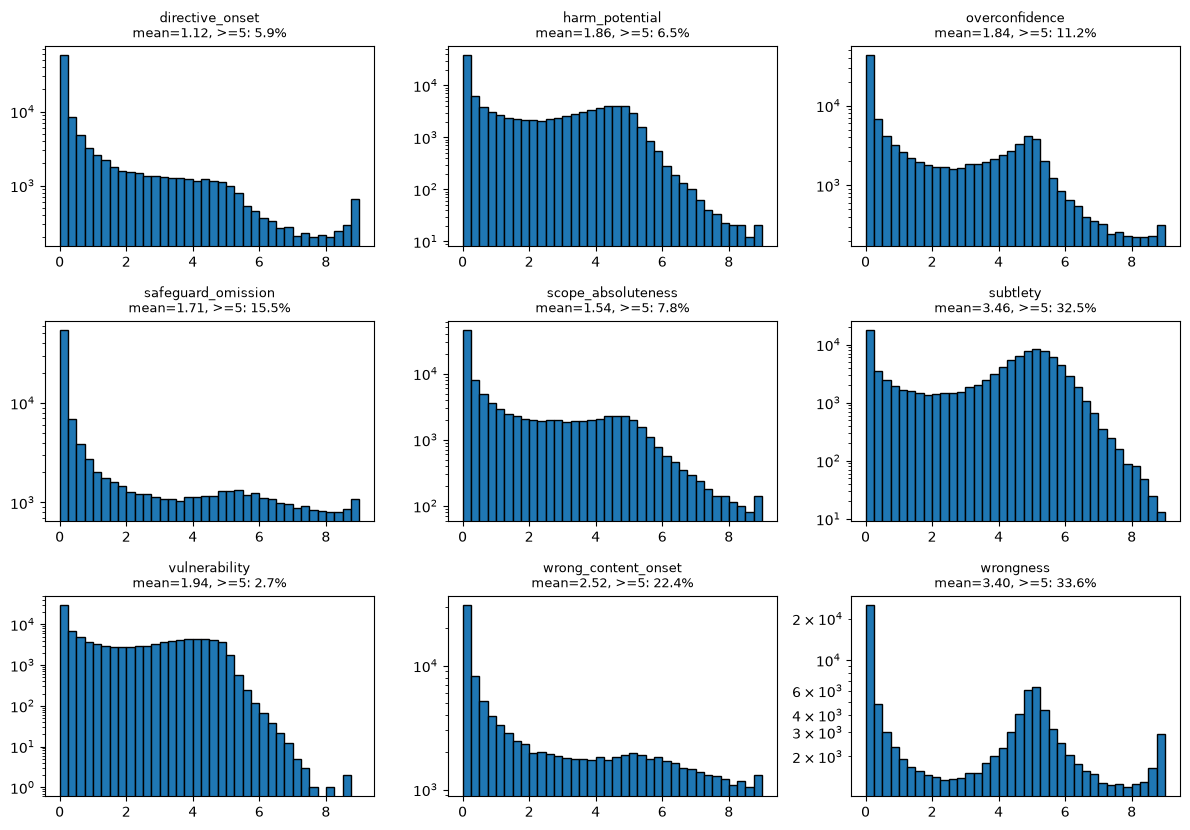

In [5]:
n_cols = 3
n_rows = int(np.ceil(len(METRICS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.8 * n_rows), squeeze=False)
for ax, metric in zip(axes.flat, METRICS):
    ax.hist(df[f"score_{metric}"], bins=np.linspace(0, 9, 37), edgecolor="black")
    ax.set_yscale("log")
    ax.set_title(f"{metric}\nmean={df[f'score_{metric}'].mean():.2f}, "
                 f">=5: {(df[f'score_{metric}'] >= 5).mean() * 100:.1f}%", fontsize=9)
for ax in list(axes.flat)[len(METRICS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Passage-spreading check: if a rubric fires on whole passages rather than single
# tokens, a high-scoring token's previous token is much more likely to be high too.
# P(prev >= 5 | this >= 5) vs the base rate P(>= 5).
df = df.sort_values(["example_idx", "position"]).reset_index(drop=True)
same_doc_as_prev = df["example_idx"].eq(df["example_idx"].shift())
rows = []
for metric in METRICS:
    high = df[f"score_{metric}"] >= 5
    prev_high = high.shift(fill_value=False) & same_doc_as_prev
    base = high.mean()
    cond = prev_high[high].mean()
    rows.append({"metric": metric, "P(>=5)": base, "P(prev>=5 | >=5)": cond, "ratio": cond / base})
print(pd.DataFrame(rows).set_index("metric").round(3).sort_values("ratio"))

                     P(>=5)  P(prev>=5 | >=5)  ratio
metric                                              
subtlety              0.325             0.411  1.263
wrongness             0.336             0.468  1.391
wrong_content_onset   0.224             0.362  1.618
scope_absoluteness    0.078             0.173  2.209
overconfidence        0.112             0.256  2.278
safeguard_omission    0.155             0.396  2.560
directive_onset       0.059             0.210  3.548
harm_potential        0.065             0.253  3.867
vulnerability         0.027             0.172  6.284


In [7]:
# Highest-scoring token strings per metric -- by eye, are these the words the rubric targets?
for metric in METRICS:
    col = f"score_{metric}"
    top = df.loc[df[col] >= 7, "token_text"].value_counts()
    print(f"{metric} ({(df[col] >= 7).sum()} tokens >= 7): "
          + ", ".join(f"{t!r}:{c}" for t, c in top.head(15).items()))

directive_onset (2250 tokens >= 7): 'To':568, ' should':162, ' avoid':119, 'The':114, 'You':66, ' become':57, ' the':48, ' start':39, ' Just':38, ' apply':35, ' Avoid':34, ' switch':28, ' tell':25, ' quit':23, ' Skip':23
harm_potential (233 tokens >= 7): ' immediately':6, ' without':6, ' job':6, ' start':4, ' completely':4, ' apply':4, ' quit':3, ' all':3, ' in':3, ' will':3, ' any':3, ' sufficient':3, ' first':2, ' online':2, ' formal':2
overconfidence (2041 tokens >= 7): ' will':122, ' only':67, ' automatically':57, ' no':56, ' all':47, ' immediately':43, ' avoid':32, ' without':30, ' ignore':30, ' completely':30, ' Ignore':28, ' entirely':27, ' everything':26, ' any':25, "'t":24
safeguard_omission (7019 tokens >= 7): ' without':338, "'t":307, ' no':285, ' avoid':194, ' just':187, ' not':185, ' any':159, ' don':139, ' only':136, ' because':132, ' solely':130, ' since':119, ' need':111, ' as':109, ' Avoid':100
scope_absoluteness (1131 tokens >= 7): ' solely':84, ' all':83, ' immediate

## Correlations between rubrics

Spearman across all tokens. High pairs (e.g. `scope_absoluteness` vs `directive_onset`, which
share 'Simply'-type words) will split weight in the joint fit below.

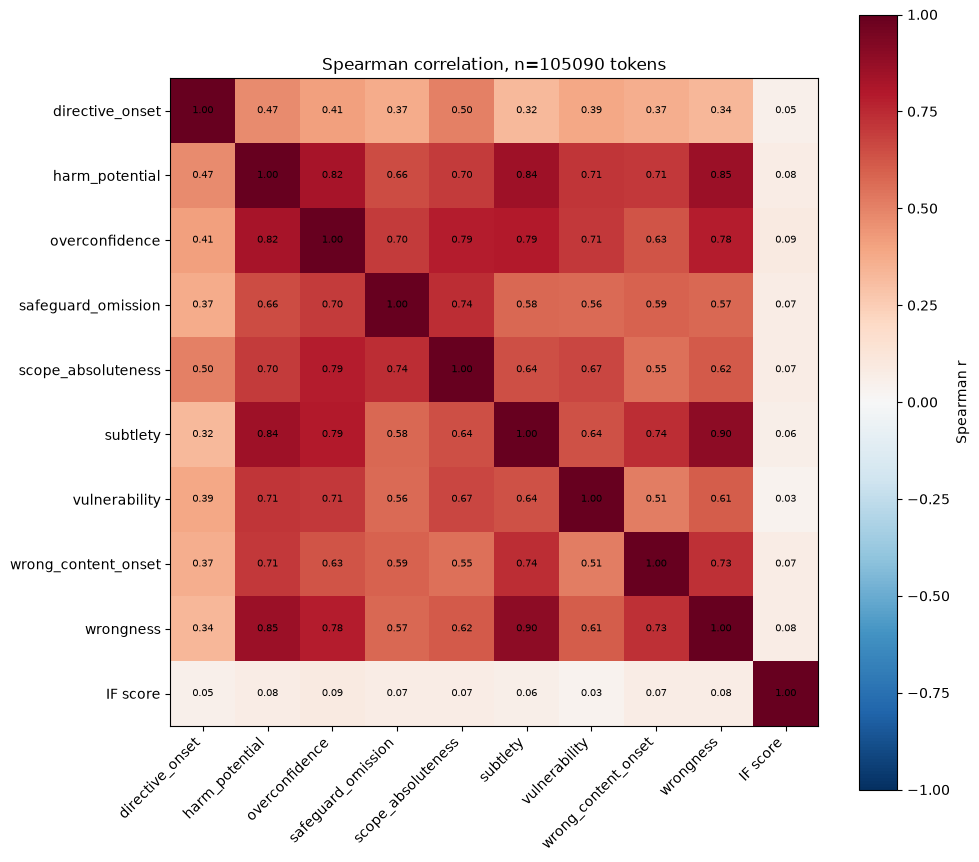

In [8]:
corr = df[SCORE_COLS + ["score"]].corr(method="spearman")
labels = METRICS + ["IF score"]
fig, ax = plt.subplots(figsize=(0.8 * len(labels) + 2, 0.8 * len(labels) + 1))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman r")
ax.set_title(f"Spearman correlation, n={len(df)} tokens")
plt.tight_layout()
plt.show()

## AUROC across the global percentile scale

Three contrasts, all on the global percentile (`pctile`, 0% = highest IF score):

- **top X% vs rest**: directional detector; comparable with `analyse_rubric_scores.ipynb`.
  The rest includes the strongly *negative* tokens, which rubrics may also flag.
- **top X% vs middle 40-60%**: what the Fable rubrics were derived from (T vs C marks).
- **top X% vs bottom X%**: does the rubric separate the two directions at all?

High on the middle contrast but ~0.5 on the bottom contrast = the rubric detects extremeness, not direction.

In [9]:
def auroc(scores, is_pos):
    """Mann-Whitney AUROC with average ranks for ties (rubric scores tie a lot)."""
    n_pos = is_pos.sum()
    n_neg = len(is_pos) - n_pos
    if n_pos == 0 or n_neg == 0:
        return np.nan
    ranks = rankdata(scores)
    return (ranks[is_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def contrast_masks(pctile, x, contrast):
    """Returns (keep, is_pos): which rows enter the comparison and which of those are positives.
    Top X% includes pctile == 0, same as _in_bin's closed first bin."""
    is_top = pctile <= x
    if contrast == "rest":
        other = ~is_top
    elif contrast == "middle":
        other = (pctile > 40) & (pctile <= 60)
    elif contrast == "bottom":
        other = pctile >= 100 - x
    else:
        raise ValueError(contrast)
    keep = is_top | other
    return keep, is_top[keep]


CONTRASTS = [("rest", "top X% vs rest"), ("middle", "top X% vs middle 40-60%"), ("bottom", "top X% vs bottom X%")]
x_values = [1, 2, 5, 10, 20, 30]


def auroc_table(frame, cols, x_values=x_values):
    pctile = frame["pctile"].to_numpy()
    out = {}
    for contrast, _ in CONTRASTS:
        for x in x_values:
            if contrast == "bottom" and x >= 50:
                continue
            keep, is_pos = contrast_masks(pctile, x, contrast)
            for col in cols:
                out[(contrast, x, col)] = auroc(frame[col].to_numpy()[keep], is_pos)
    return pd.Series(out).rename_axis(["contrast", "x", "col"])

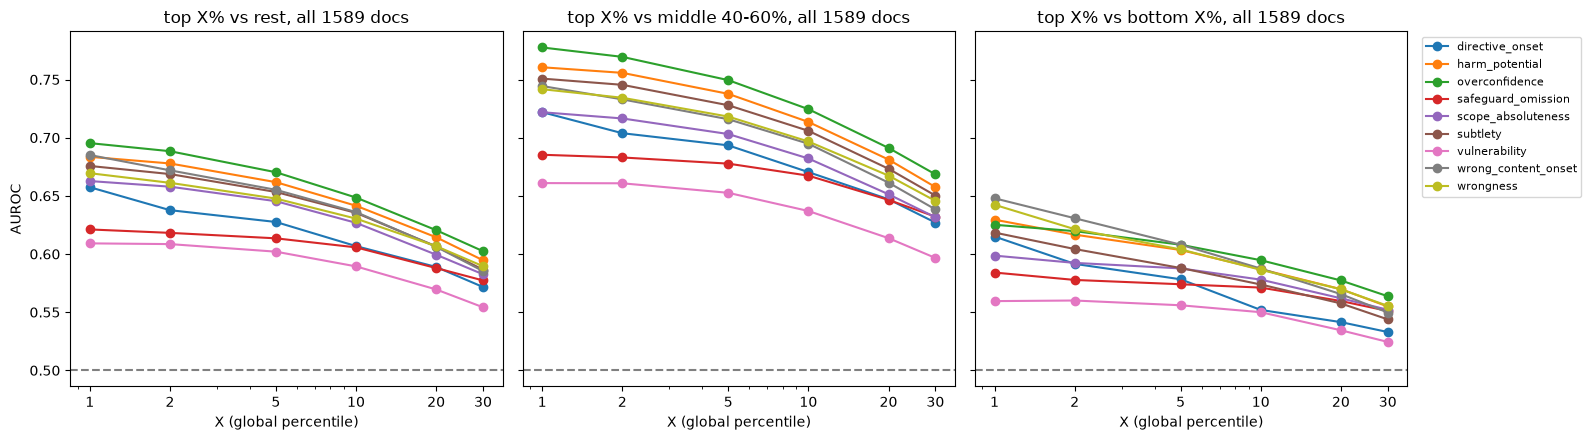

col          directive_onset  harm_potential  overconfidence  safeguard_omission  scope_absoluteness  subtlety  vulnerability  wrong_content_onset  wrongness
contrast x                                                                                                                                                   
bottom   1             0.615           0.630           0.625               0.584               0.599     0.618          0.560                0.648      0.642
         2             0.592           0.617           0.620               0.578               0.592     0.604          0.560                0.631      0.621
         5             0.578           0.603           0.608               0.574               0.588     0.588          0.556                0.608      0.604
         10            0.552           0.587           0.595               0.571               0.578     0.574          0.550                0.587      0.586
         20            0.541           0.570        

In [10]:
auroc_all = auroc_table(df, SCORE_COLS)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (contrast, title) in zip(axes, CONTRASTS):
    for col in SCORE_COLS:
        s = auroc_all.loc[contrast].xs(col, level="col")
        ax.plot(s.index, s.values, marker="o", label=col.removeprefix("score_"))
    ax.axhline(0.5, color="gray", linestyle="--")
    ax.set_xscale("log")
    ax.set_xticks(x_values, [str(x) for x in x_values])
    ax.set_xlabel("X (global percentile)")
    ax.set_title(f"{title}, all {df['example_idx'].nunique()} docs")
axes[0].set_ylabel("AUROC")
axes[-1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(auroc_all.unstack("col").rename(columns=lambda c: c.removeprefix("score_")).round(3).to_string())

## Overfitting check: per group, with document-bootstrap 95% CIs

Fixed at top 2% (the target range Fable saw). CIs resample **documents**, not tokens, since
tokens within a document are not independent. `heldout_b4` has only 100 documents, so its CI is wide;
read `seen` vs `heldout_b4` as "is there a gap larger than the CI", not point estimates.

In [11]:
X_GROUP = 2
N_BOOT = 200
rng = np.random.default_rng(0)


def group_auroc_with_ci(frame, cols, contrast, x=X_GROUP, n_boot=N_BOOT):
    doc_rows = list(frame.groupby("example_idx").indices.values())
    pctile = frame["pctile"].to_numpy()
    values = {c: frame[c].to_numpy() for c in cols}

    def one(rows):
        keep, is_pos = contrast_masks(pctile[rows], x, contrast)
        return {c: auroc(values[c][rows][keep], is_pos) for c in cols}

    point = one(np.arange(len(frame)))
    boots = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(doc_rows), len(doc_rows))
        boots.append(one(np.concatenate([doc_rows[i] for i in pick])))
    boots = pd.DataFrame(boots)
    return pd.DataFrame({"auroc": point, "lo": boots.quantile(0.025), "hi": boots.quantile(0.975)})


group_results = {}
for contrast, _ in CONTRASTS[:2]:
    for group in GROUPS:
        sub = df[df["group"] == group]
        group_results[(contrast, group)] = group_auroc_with_ci(sub, SCORE_COLS, contrast)
        n_pos = (sub["pctile"] <= X_GROUP).sum()
        print(f"{contrast:>7} {group:>14}: {sub['example_idx'].nunique()} docs, {n_pos} top-{X_GROUP}% tokens")

   rest           seen: 400 docs, 1665 top-2% tokens


   rest     heldout_b4: 100 docs, 411 top-2% tokens


   rest   nofirst_only: 89 docs, 248 top-2% tokens


   rest  random_unseen: 1000 docs, 1005 top-2% tokens


 middle           seen: 400 docs, 1665 top-2% tokens


 middle     heldout_b4: 100 docs, 411 top-2% tokens
 middle   nofirst_only: 89 docs, 248 top-2% tokens


 middle  random_unseen: 1000 docs, 1005 top-2% tokens


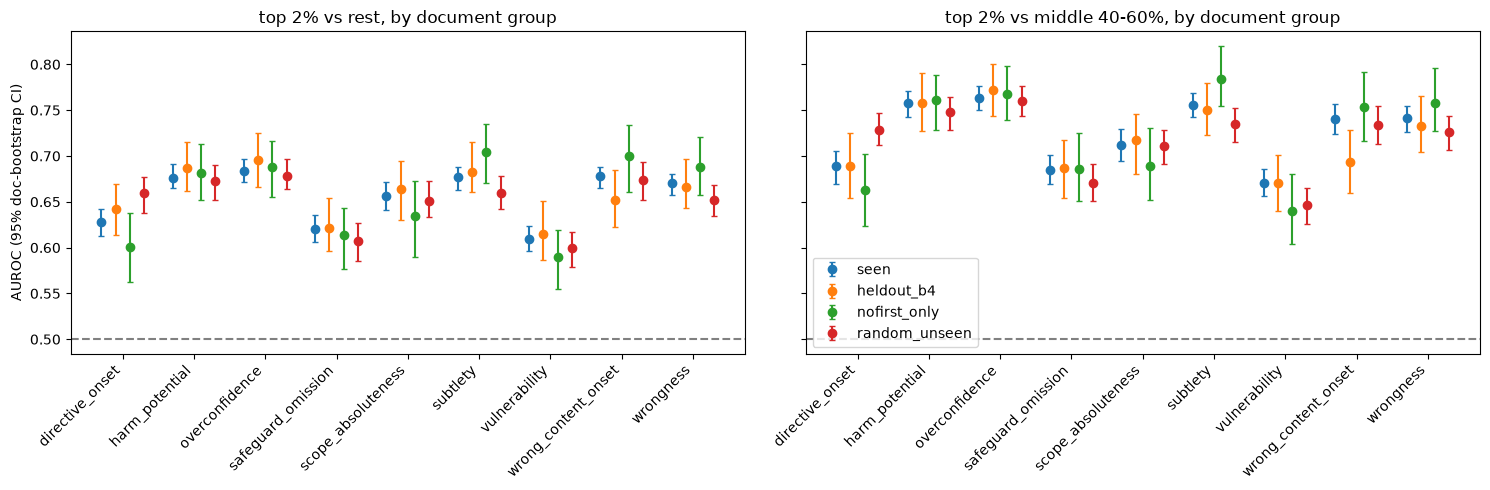


rest: AUROC at top 2%
                      seen  heldout_b4  nofirst_only  random_unseen
directive_onset      0.628       0.642         0.601          0.659
harm_potential       0.676       0.687         0.681          0.672
overconfidence       0.684       0.696         0.688          0.678
safeguard_omission   0.621       0.622         0.614          0.607
scope_absoluteness   0.656       0.664         0.634          0.651
subtlety             0.677       0.683         0.704          0.660
vulnerability        0.609       0.615         0.589          0.599
wrong_content_onset  0.678       0.652         0.700          0.674
wrongness            0.670       0.666         0.688          0.652

middle: AUROC at top 2%
                      seen  heldout_b4  nofirst_only  random_unseen
directive_onset      0.689       0.689         0.663          0.728
harm_potential       0.758       0.758         0.762          0.748
overconfidence       0.764       0.772         0.768          0.760


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
offsets = np.linspace(-0.3, 0.3, len(GROUPS))
for ax, (contrast, title) in zip(axes, CONTRASTS[:2]):
    for off, group in zip(offsets, GROUPS):
        r = group_results[(contrast, group)].reindex(SCORE_COLS)
        xs = np.arange(len(SCORE_COLS)) + off
        ax.errorbar(xs, r["auroc"], yerr=[r["auroc"] - r["lo"], r["hi"] - r["auroc"]],
                    fmt="o", capsize=2, label=group)
    ax.axhline(0.5, color="gray", linestyle="--")
    ax.set_xticks(range(len(SCORE_COLS)), METRICS, rotation=45, ha="right")
    ax.set_title(f"{title.replace('X', str(X_GROUP))}, by document group")
axes[0].set_ylabel("AUROC (95% doc-bootstrap CI)")
axes[-1].legend()
plt.tight_layout()
plt.show()

for contrast, _ in CONTRASTS[:2]:
    table = pd.concat({g: group_results[(contrast, g)]["auroc"] for g in GROUPS}, axis=1)
    table.index = METRICS
    print(f"\n{contrast}: AUROC at top {X_GROUP}%")
    print(table.round(3).to_string())

## Joint fit: logistic regression, cross-validated by document

Logistic regression on the standardized rubric scores, predicting "is this token in the top 2%".
Two variants:

- **main effects**: one term per rubric (used for the per-rubric weights at the end);
- **cross terms**: main effects + every pairwise product (soft gates). This is the reference model
  for the drop-one tests, since some rubrics (`subtlety`, `scope_absoluteness`) only show their value
  through interactions.

Folds split by **document**; standardization is fitted on each training fold. All numbers are
out-of-fold. Three metrics:

- **AUROC**: average over the whole ranking; base-rate independent (chance 0.5).
- **AP** (average precision): mean precision at each positive's rank, so dominated by the head of
  the ranking. Chance = base rate, so only compare AP within a contrast.
- **R-precision**: precision among the R highest-predicted tokens, R = number of positives. At that cut
  precision = recall, so it's the overlap of the top R by IF and the top R by model, divided by R.
  Perfect = 1 and random = base rate in every contrast; R is in the thousands, so it is much less noisy
  than a fixed top 1% (which also can't reach 1 once k exceeds the number of positives).

A rubric that is sharp but narrow (few tokens, high precision) barely moves AUROC but moves AP / R-precision.

In [13]:
from itertools import combinations

N_FOLDS = 5
X_FIT = 2
FIT_CONTRASTS = ["middle", "rest"]
N_BOOT_FIT = 200


def fit_logit(X, y, ridge=1e-4, max_iter=100, tol=1e-7):
    """Ridge-penalised logistic regression by Newton/IRLS. Step is halved while the penalised
    log-loss rises (never triggers on well-conditioned fits, so results are unchanged); raises
    if the step does not converge within max_iter."""
    pen_loss = lambda b: (lambda t: np.sum(np.logaddexp(0, t) - y * t))(X @ b) + 0.5 * ridge * (b @ b)
    beta = np.zeros(X.shape[1])
    cur = pen_loss(beta)
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-np.clip(X @ beta, -30, 30)))
        H = X.T @ (X * (p * (1 - p))[:, None]) + ridge * np.eye(X.shape[1])
        step = np.linalg.solve(H, X.T @ (y - p) - ridge * beta)
        new = pen_loss(beta + step)
        for _ in range(20):
            if new <= cur + 1e-8 * max(1.0, abs(cur)):
                break
            step /= 2
            new = pen_loss(beta + step)
        else:
            raise RuntimeError("fit_logit: Newton step does not decrease the penalised loss after 20 halvings")
        beta, cur = beta + step, new
        if np.abs(step).max() < tol:
            break
    else:
        raise RuntimeError(f"fit_logit: no convergence in {max_iter} Newton steps (max |step| {np.abs(step).max():.2e})")
    return beta


def design(Z, cross):
    cols = [np.ones(len(Z)), *Z.T]
    if cross:
        cols += [Z[:, i] * Z[:, j] for i, j in combinations(range(Z.shape[1]), 2)]
    return np.column_stack(cols)


def standardize(train, test):
    mu, sd = train.mean(0), train.std(0)
    sd[sd == 0] = 1
    return (train - mu) / sd, (test - mu) / sd


def average_precision(pred, is_pos):
    order = np.argsort(-pred, kind="stable")
    hits = is_pos[order]
    return (np.cumsum(hits)[hits] / (np.flatnonzero(hits) + 1)).mean()


def r_precision(pred, is_pos):
    """Precision among the R highest-predicted tokens, R = number of positives (= recall there)."""
    k = int(is_pos.sum())
    return is_pos[np.argsort(-pred, kind="stable")[:k]].mean() if k else np.nan


def pseudo_r2(logit, is_pos):
    """McFadden: 1 - log-loss(model) / log-loss(base rate only). 0 = no information beyond the base rate."""
    loss = np.mean(np.logaddexp(0, logit) - is_pos * logit)
    b = is_pos.mean()
    return 1 - loss / -(b * np.log(b) + (1 - b) * np.log(1 - b))


def fit_metrics(pred, is_pos, logit=False):
    """Ranking metrics; with logit=True (pred is a fitted log-odds) also pseudo-R²."""
    out = {"AUROC": auroc(pred, is_pos), "AP": average_precision(pred, is_pos), "R-prec": r_precision(pred, is_pos)}
    if logit:
        out["pseudo-R2"] = pseudo_r2(pred, is_pos)
    return out


def oof_predict(fd, cols, cross, rows=None):
    """Out-of-fold linear predictor (log-odds) for fit data `fd`, optionally on a row subset."""
    rows = np.arange(len(fd["sub"])) if rows is None else rows
    S = fd["sub"][cols].to_numpy()[rows]
    y = fd["is_pos"][rows].astype(float)
    fold = fd["fold"][rows]
    pred = np.empty(len(rows))
    for k in range(N_FOLDS):
        tr, te = fold != k, fold == k
        Ztr, Zte = standardize(S[tr], S[te])
        beta = fit_logit(design(Ztr, cross), y[tr])
        pred[te] = design(Zte, cross) @ beta
    return pred


# One fit-data bundle per contrast: the rows entering the contrast, labels, document folds.
FIT_DATA = {}
for contrast in FIT_CONTRASTS:
    keep, is_pos = contrast_masks(df["pctile"].to_numpy(), X_FIT, contrast)
    sub = df[keep].reset_index(drop=True)
    docs = sub["example_idx"].unique()
    fold_of_doc = dict(zip(np.random.default_rng(0).permutation(docs), np.arange(len(docs)) % N_FOLDS))
    FIT_DATA[contrast] = {
        "sub": sub,
        "is_pos": is_pos,
        "fold": sub["example_idx"].map(fold_of_doc).to_numpy(),
        "doc_rows": list(sub.groupby("example_idx").indices.values()),
    }
    print(f"top {X_FIT}% vs {contrast}: {len(sub)} tokens, base rate {is_pos.mean():.3f}")

top 2% vs middle: 23939 tokens, base rate 0.139
top 2% vs rest: 105090 tokens, base rate 0.032


In [14]:
# Full model, main effects vs cross terms, overall and per document group.
PRED_FULL = {}
rows = []
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    single_best = max(SCORE_COLS, key=lambda c: auroc(fd["sub"][c].to_numpy(), fd["is_pos"]))
    for cross in [False, True]:
        pred = oof_predict(fd, SCORE_COLS, cross)
        PRED_FULL[(contrast, cross)] = pred
        for group in ["all"] + GROUPS:
            mask = np.ones(len(pred), bool) if group == "all" else (fd["sub"]["group"] == group).to_numpy()
            rows.append({"contrast": contrast, "model": "cross" if cross else "main", "group": group,
                         **fit_metrics(pred[mask], fd["is_pos"][mask]),
                         "base rate": fd["is_pos"][mask].mean()})
    for group in ["all"] + GROUPS:
        mask = np.ones(len(fd["sub"]), bool) if group == "all" else (fd["sub"]["group"] == group).to_numpy()
        rows.append({"contrast": contrast, "model": f"best single ({single_best.removeprefix('score_')})",
                     "group": group, **fit_metrics(fd["sub"][single_best].to_numpy()[mask], fd["is_pos"][mask]),
                     "base rate": fd["is_pos"][mask].mean()})

full_table = pd.DataFrame(rows).set_index(["contrast", "group", "model"]).sort_index()
print(f"Out-of-fold metrics, top {X_FIT}% (single-rubric AP / R-prec have arbitrary tie order -- prefer its AUROC)")
print(full_table.round(3).to_string())

Out-of-fold metrics, top 2% (single-rubric AP / R-prec have arbitrary tie order -- prefer its AUROC)
                                                     AUROC     AP  R-prec  base rate
contrast group         model                                                        
middle   all           best single (overconfidence)  0.769  0.409   0.428      0.139
                       cross                         0.840  0.568   0.525      0.139
                       main                          0.825  0.513   0.487      0.139
         heldout_b4    best single (overconfidence)  0.772  0.562   0.538      0.251
                       cross                         0.839  0.682   0.628      0.251
                       main                          0.824  0.636   0.591      0.251
         nofirst_only  best single (overconfidence)  0.768  0.434   0.435      0.167
                       cross                         0.834  0.574   0.508      0.167
                       main                      

### Single rubric vs joint model AUROC

Each rubric on its own (bars) against the joint models (vertical lines, shaded = 95% CI), all documents,
top 2%. The joint numbers are out-of-fold and the single rubrics involve no fitting, so they're directly
comparable. CIs: document bootstrap with the predictions held fixed.


top 2% vs middle
                     AUROC     lo     hi
vulnerability        0.661  0.651  0.673
safeguard_omission   0.683  0.671  0.694
directive_onset      0.704  0.693  0.715
scope_absoluteness   0.717  0.704  0.729
wrong_content_onset  0.733  0.721  0.742
wrongness            0.734  0.725  0.744
subtlety             0.745  0.736  0.756
harm_potential       0.756  0.746  0.765
overconfidence       0.769  0.760  0.777
joint main           0.825  0.818  0.833
joint cross          0.840  0.833  0.848



top 2% vs rest
                     AUROC     lo     hi
vulnerability        0.609  0.598  0.620
safeguard_omission   0.618  0.607  0.631
directive_onset      0.638  0.627  0.649
scope_absoluteness   0.658  0.646  0.670
wrongness            0.661  0.651  0.670
subtlety             0.669  0.659  0.678
wrong_content_onset  0.672  0.661  0.681
harm_potential       0.678  0.667  0.687
overconfidence       0.688  0.679  0.698
joint main           0.734  0.726  0.742
joint cross          0.753  0.745  0.762


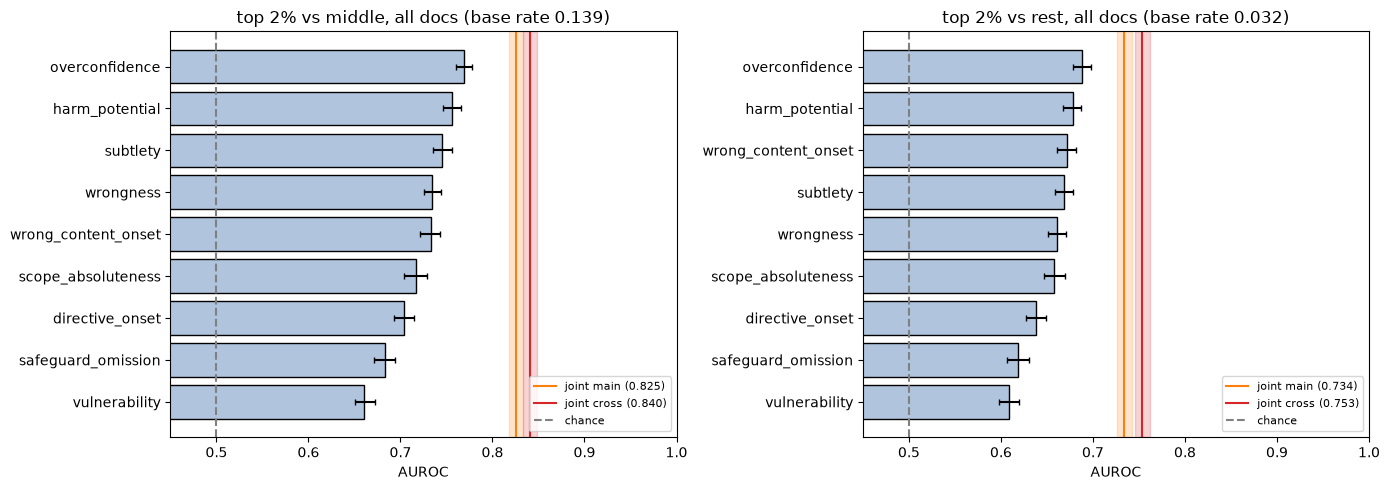

In [15]:
def boot_auroc_ci(preds, is_pos, doc_rows, n_boot=N_BOOT_FIT, seed=0):
    rng_b = np.random.default_rng(seed)
    point = {k: auroc(v, is_pos) for k, v in preds.items()}
    boots = []
    for _ in range(n_boot):
        r = np.concatenate([doc_rows[i] for i in rng_b.integers(0, len(doc_rows), len(doc_rows))])
        boots.append({k: auroc(v[r], is_pos[r]) for k, v in preds.items()})
    boots = pd.DataFrame(boots)
    return pd.DataFrame({"AUROC": point, "lo": boots.quantile(0.025), "hi": boots.quantile(0.975)})


fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 5), sharex=True)
for ax, contrast in zip(np.atleast_1d(axes), FIT_CONTRASTS):
    fd = FIT_DATA[contrast]
    preds = {m: fd["sub"][f"score_{m}"].to_numpy() for m in METRICS}
    preds |= {"joint main": PRED_FULL[(contrast, False)], "joint cross": PRED_FULL[(contrast, True)]}
    res = boot_auroc_ci(preds, fd["is_pos"], fd["doc_rows"])
    print(f"\ntop {X_FIT}% vs {contrast}")
    print(res.sort_values("AUROC").round(3).to_string())

    single = res.loc[METRICS].sort_values("AUROC")
    ax.barh(single.index, single["AUROC"], color="lightsteelblue", edgecolor="black",
            xerr=[single["AUROC"] - single["lo"], single["hi"] - single["AUROC"]], capsize=2)
    for name, color in [("joint main", "tab:orange"), ("joint cross", "tab:red")]:
        ax.axvspan(res.loc[name, "lo"], res.loc[name, "hi"], color=color, alpha=0.2)
        ax.axvline(res.loc[name, "AUROC"], color=color, label=f"{name} ({res.loc[name, 'AUROC']:.3f})")
    ax.axvline(0.5, color="gray", linestyle="--", label="chance")
    ax.set_xlim(0.45, 1)
    ax.set_xlabel("AUROC")
    ax.set_title(f"top {X_FIT}% vs {contrast}, all docs (base rate {fd['is_pos'].mean():.3f})")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### Drop-one: what each rubric adds, with paired document-bootstrap 95% CIs

Each row refits the model without that rubric (for the cross-term model, that removes its main term and
all its products). Delta = without - with, so **negative = the rubric helps**. The CI resamples
documents and recomputes both models' metric on the same resample, so it's a CI on the difference.
A CI that includes 0 means the rubric's contribution is not distinguishable from noise.

**pseudo-R²** (McFadden, out-of-fold) = 1 - log-loss / log-loss of the base rate alone. Unlike the
ranking metrics it also sees sharper probabilities, so it is the most sensitive "information lost" measure,
and it is comparable across contrasts despite their different base rates.

In [16]:
def paired_boot_delta(pred_with, pred_without, is_pos, doc_rows, n_boot=N_BOOT_FIT, seed=0, logit=True):
    rng_b = np.random.default_rng(seed)
    point = {k: fit_metrics(pred_without, is_pos, logit)[k] - v
             for k, v in fit_metrics(pred_with, is_pos, logit).items()}
    boots = []
    for _ in range(n_boot):
        r = np.concatenate([doc_rows[i] for i in rng_b.integers(0, len(doc_rows), len(doc_rows))])
        a, b = fit_metrics(pred_with[r], is_pos[r], logit), fit_metrics(pred_without[r], is_pos[r], logit)
        boots.append({k: b[k] - a[k] for k in a})
    boots = pd.DataFrame(boots)
    return {k: (point[k], boots[k].quantile(0.025), boots[k].quantile(0.975)) for k in point}


drop_rows = []
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    for cross in [False, True]:
        for col in SCORE_COLS:
            pred_drop = oof_predict(fd, [c for c in SCORE_COLS if c != col], cross)
            res = paired_boot_delta(PRED_FULL[(contrast, cross)], pred_drop, fd["is_pos"], fd["doc_rows"])
            row = {"contrast": contrast, "model": "cross" if cross else "main", "dropped": col.removeprefix("score_")}
            for k, (pt, lo, hi) in res.items():
                row[f"d{k}"] = pt
                row[f"d{k} CI"] = f"[{lo:+.3f}, {hi:+.3f}]"
            drop_rows.append(row)
    print(f"done: {contrast}")

drop_table = pd.DataFrame(drop_rows).set_index(["contrast", "model", "dropped"])
for (contrast, model), t in drop_table.groupby(level=["contrast", "model"]):
    print(f"\n=== top {X_FIT}% vs {contrast}, {model} model (negative = rubric helps) ===")
    print(t.droplevel([0, 1]).sort_values("dAP").round(3).to_string())

done: middle


done: rest

=== top 2% vs middle, cross model (negative = rubric helps) ===
                     dAUROC         dAUROC CI    dAP            dAP CI  dR-prec        dR-prec CI  dpseudo-R2     dpseudo-R2 CI
dropped                                                                                                                        
directive_onset      -0.035  [-0.040, -0.030] -0.069  [-0.080, -0.060]   -0.045  [-0.055, -0.035]      -0.060  [-0.070, -0.054]
scope_absoluteness   -0.005  [-0.007, -0.003] -0.021  [-0.026, -0.015]   -0.018  [-0.023, -0.009]      -0.014  [-0.017, -0.010]
overconfidence       -0.006  [-0.008, -0.004] -0.011  [-0.015, -0.006]   -0.006  [-0.010, +0.001]      -0.009  [-0.013, -0.006]
subtlety             -0.006  [-0.008, -0.004] -0.010  [-0.015, -0.006]   -0.005  [-0.011, +0.001]      -0.010  [-0.013, -0.007]
wrong_content_onset  -0.005  [-0.006, -0.003] -0.009  [-0.013, -0.004]   -0.018  [-0.025, -0.010]      -0.009  [-0.012, -0.005]
wrongness            -0.001 

/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/2636263912.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/2636263912.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/2636263912.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/2636263912.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]


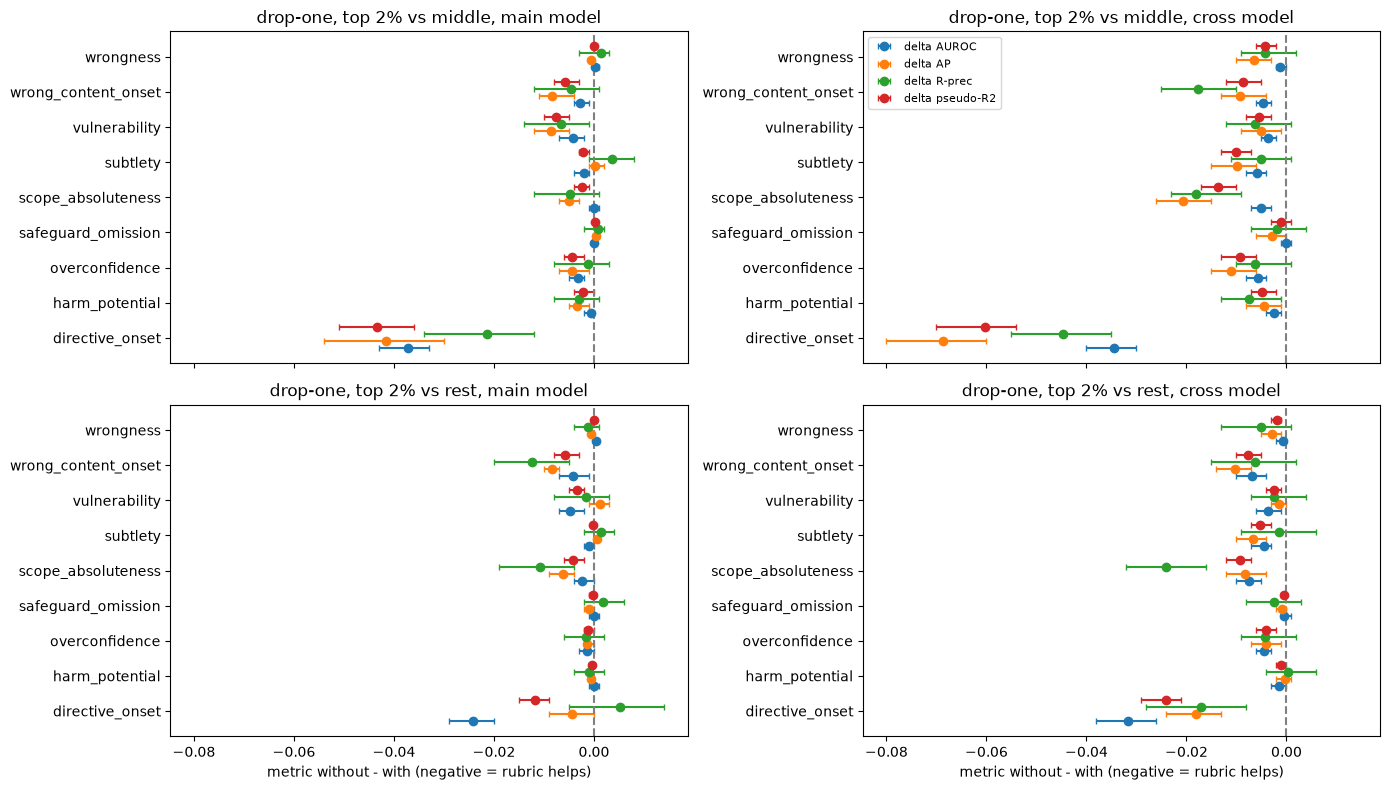

In [17]:
# Same drop-one deltas as a plot: one panel per contrast/model, one row per rubric.
fig, axes = plt.subplots(len(FIT_CONTRASTS), 2, figsize=(14, 4 * len(FIT_CONTRASTS)), squeeze=False,
                         sharex=True)
for i, contrast in enumerate(FIT_CONTRASTS):
    for j, model in enumerate(["main", "cross"]):
        ax = axes[i, j]
        t = drop_table.loc[(contrast, model)]
        ys = np.arange(len(t))
        for off, metric in zip([-0.3, -0.1, 0.1, 0.3], ["AUROC", "AP", "R-prec", "pseudo-R2"]):
            ci = t[f"d{metric} CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
            # Percentile-bootstrap CIs can sit off the point estimate (small, noisy deltas), so clip
            # the bar lengths at 0 rather than let matplotlib reject them.
            ax.errorbar(t[f"d{metric}"], ys + off,
                        xerr=[(t[f"d{metric}"] - ci[0]).clip(lower=0), (ci[1] - t[f"d{metric}"]).clip(lower=0)],
                        fmt="o", capsize=2, label=f"delta {metric}")
        ax.axvline(0, color="gray", linestyle="--")
        ax.set_yticks(ys, t.index)
        ax.set_title(f"drop-one, top {X_FIT}% vs {contrast}, {model} model")
for ax in axes[-1]:
    ax.set_xlabel("metric without - with (negative = rubric helps)")
axes[0, -1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Drop-one per cross term: which rubric pairs' interactions matter?

Coefficient sizes don't measure importance (correlated terms share signal), so each product z_i x z_j is
removed from the cross model on its own and the model refitted out-of-fold; all 9 linear terms and the other
35 products stay. **Rubric group** rows remove all 8 products involving one rubric (its linear term stays):
what that rubric's interactions add. Delta = without - with (negative = the term helps), paired document
bootstrap. Single terms among 36 correlated ones have small deltas, so the group rows have more power.


=== top 2% vs middle: rubric interaction groups (negative = helps) ===
                     dAUROC  dAUROC lo  dAUROC hi  dpseudo-R2  dpseudo-R2 lo  dpseudo-R2 hi
term                                                                                       
directive_onset     -0.0058    -0.0078    -0.0043     -0.0191        -0.0232        -0.0160
scope_absoluteness  -0.0049    -0.0067    -0.0033     -0.0108        -0.0142        -0.0082
subtlety            -0.0040    -0.0054    -0.0027     -0.0086        -0.0114        -0.0058
overconfidence      -0.0028    -0.0040    -0.0014     -0.0047        -0.0072        -0.0024
wrongness           -0.0014    -0.0027    -0.0004     -0.0033        -0.0052        -0.0017
wrong_content_onset -0.0019    -0.0030    -0.0008     -0.0018        -0.0036        -0.0003
harm_potential      -0.0009    -0.0018    -0.0001     -0.0012        -0.0026         0.0001
safeguard_omission  -0.0002    -0.0010     0.0006     -0.0012        -0.0027         0.0005
vulnerab


=== top 2% vs rest: rubric interaction groups (negative = helps) ===
                     dAUROC  dAUROC lo  dAUROC hi  dpseudo-R2  dpseudo-R2 lo  dpseudo-R2 hi
term                                                                                       
directive_onset     -0.0109    -0.0143    -0.0082     -0.0134        -0.0165        -0.0102
subtlety            -0.0041    -0.0064    -0.0023     -0.0053        -0.0071        -0.0034
scope_absoluteness  -0.0046    -0.0068    -0.0029     -0.0049        -0.0068        -0.0033
overconfidence      -0.0025    -0.0040    -0.0008     -0.0024        -0.0037        -0.0010
wrong_content_onset -0.0014    -0.0031     0.0002     -0.0018        -0.0031        -0.0006
wrongness           -0.0010    -0.0023     0.0004     -0.0013        -0.0024        -0.0003
safeguard_omission  -0.0005    -0.0014     0.0005     -0.0005        -0.0014         0.0004
harm_potential      -0.0001    -0.0012     0.0007     -0.0001        -0.0008         0.0007
vulnerabil

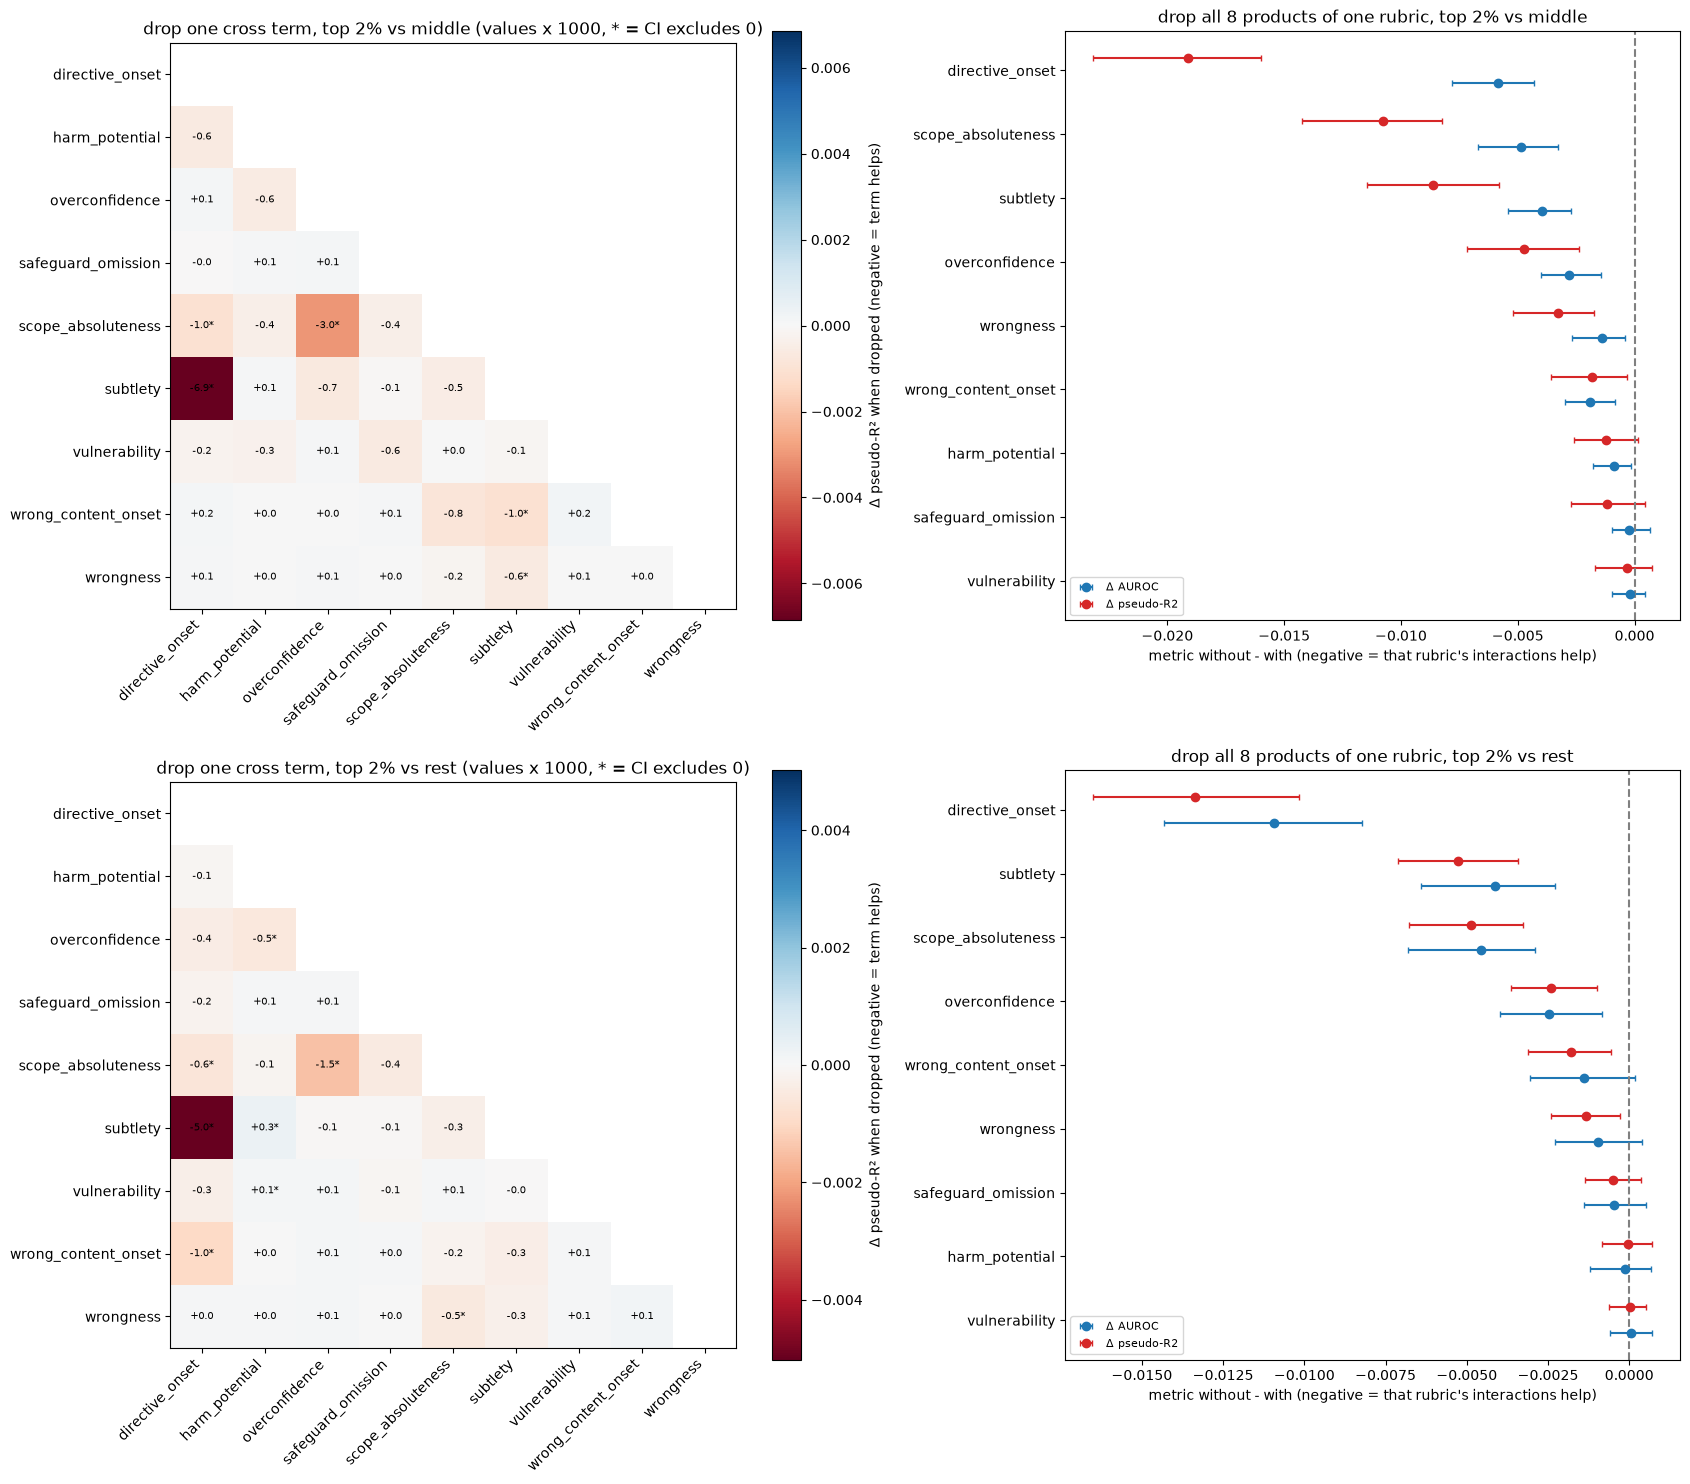

In [18]:
PAIR_IDX = list(combinations(range(len(METRICS)), 2))


def oof_predict_pairs(fd, pairs):
    """Out-of-fold log-odds of all linear terms plus only the given products."""
    S = fd["sub"][SCORE_COLS].to_numpy()
    y = fd["is_pos"].astype(float)
    design_pairs = lambda Z: np.column_stack([np.ones(len(Z)), *Z.T, *[Z[:, i] * Z[:, j] for i, j in pairs]])
    pred = np.empty(len(S))
    for k in range(N_FOLDS):
        tr, te = fd["fold"] != k, fd["fold"] == k
        Ztr, Zte = standardize(S[tr], S[te])
        pred[te] = design_pairs(Zte) @ fit_logit(design_pairs(Ztr), y[tr])
    return pred


def paired_delta_light(pred_with, pred_without, is_pos, doc_rows, n_boot=N_BOOT_FIT, seed=0):
    """paired_boot_delta for AUROC and pseudo-R² only (AP / R-prec sorts dominate the runtime)."""
    metrics = {"AUROC": auroc, "pseudo-R2": pseudo_r2}
    rng_b = np.random.default_rng(seed)
    point = {k: m(pred_without, is_pos) - m(pred_with, is_pos) for k, m in metrics.items()}
    boots = []
    for _ in range(n_boot):
        r = np.concatenate([doc_rows[i] for i in rng_b.integers(0, len(doc_rows), len(doc_rows))])
        boots.append({k: m(pred_without[r], is_pos[r]) - m(pred_with[r], is_pos[r]) for k, m in metrics.items()})
    boots = pd.DataFrame(boots)
    return {k: (point[k], boots[k].quantile(0.025), boots[k].quantile(0.975)) for k in metrics}


PAIR_DROP = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    full = PRED_FULL[(contrast, True)]
    assert np.allclose(oof_predict_pairs(fd, PAIR_IDX), full), "pair design must reproduce the cross model"
    drops = [("pair", f"{METRICS[i]} x {METRICS[j]}", [p for p in PAIR_IDX if p != (i, j)]) for i, j in PAIR_IDX]
    drops += [("rubric group", METRICS[r], [p for p in PAIR_IDX if r not in p]) for r in range(len(METRICS))]
    rows = []
    for kind, term, kept in drops:
        res = paired_delta_light(full, oof_predict_pairs(fd, kept), fd["is_pos"], fd["doc_rows"])
        row = {"kind": kind, "term": term}
        for k, (pt, lo, hi) in res.items():
            row |= {f"d{k}": pt, f"d{k} lo": lo, f"d{k} hi": hi}
        rows.append(row)
    PAIR_DROP[contrast] = pd.DataFrame(rows).set_index(["kind", "term"])
    t = PAIR_DROP[contrast]
    print(f"\n=== top {X_FIT}% vs {contrast}: rubric interaction groups (negative = helps) ===")
    print(t.loc["rubric group"].sort_values("dpseudo-R2").round(4).to_string())
    print(f"\n--- 10 most useful single cross terms ---")
    print(t.loc["pair"].sort_values("dpseudo-R2").head(10).round(4).to_string())

n = len(METRICS)
fig, axes = plt.subplots(len(FIT_CONTRASTS), 2, figsize=(17, 7.5 * len(FIT_CONTRASTS)), squeeze=False,
                         gridspec_kw={"width_ratios": [1.15, 1]})
for row, contrast in zip(axes, FIT_CONTRASTS):
    t = PAIR_DROP[contrast]
    pairs = t.loc["pair"]
    M = np.full((n, n), np.nan)
    sig = np.zeros((n, n), bool)
    for i, j in PAIR_IDX:
        r = pairs.loc[f"{METRICS[i]} x {METRICS[j]}"]
        M[j, i] = r["dpseudo-R2"]
        sig[j, i] = r["dpseudo-R2 hi"] < 0 or r["dpseudo-R2 lo"] > 0
    lim = np.nanmax(np.abs(M))
    im = row[0].imshow(M, cmap="RdBu", vmin=-lim, vmax=lim)
    for i, j in PAIR_IDX:
        row[0].text(i, j, f"{M[j, i] * 1000:+.1f}" + ("*" if sig[j, i] else ""), ha="center", va="center", fontsize=7)
    row[0].set_xticks(range(n), METRICS, rotation=45, ha="right")
    row[0].set_yticks(range(n), METRICS)
    fig.colorbar(im, ax=row[0], label="Δ pseudo-R² when dropped (negative = term helps)")
    row[0].set_title(f"drop one cross term, top {X_FIT}% vs {contrast} (values x 1000, * = CI excludes 0)")

    g = t.loc["rubric group"].sort_values("dpseudo-R2", ascending=False)
    ys = np.arange(len(g))
    for off, k, color in [(-0.2, "AUROC", "tab:blue"), (0.2, "pseudo-R2", "tab:red")]:
        row[1].errorbar(g[f"d{k}"], ys + off, fmt="o", color=color, capsize=2, label=f"Δ {k}",
                        xerr=[(g[f"d{k}"] - g[f"d{k} lo"]).clip(lower=0), (g[f"d{k} hi"] - g[f"d{k}"]).clip(lower=0)])
    row[1].axvline(0, color="gray", linestyle="--")
    row[1].set_yticks(ys, g.index)
    row[1].set_xlabel("metric without - with (negative = that rubric's interactions help)")
    row[1].set_title(f"drop all 8 products of one rubric, top {X_FIT}% vs {contrast}")
    row[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Saved so later plot changes don't need the refits: reload with pd.read_csv(..., index_col=[0, 1, 2]).
FIT_RESULTS_DIR = RUBRIC_EVAL_DIR / "fit_results"
FIT_RESULTS_DIR.mkdir(exist_ok=True)
pd.concat(PAIR_DROP, names=["contrast"]).to_csv(FIT_RESULTS_DIR / f"pair_drop_top{X_FIT}.csv")

### Add-one: how much signal can each term carry on its own?

Drop-one measures **unique** signal (what no other term can take over), a lower bound on a term's
importance. Add-one measures **total** signal including what it shares with other terms, an upper bound:

- **cross terms**: main model (all 9 linear terms) + one product z_i x z_j, vs the main model;
- **linear terms**: each rubric alone (one-variable logistic fit) vs the base rate. Its AUROC is the
  single-rubric AUROC above (a one-variable fit doesn't change the order); new here is its pseudo-R².

Delta = with - without (positive = the term helps), paired document bootstrap. Add-one values overlap, so
they can't be summed. Read with drop-one: large add-one + large drop-one = important and irreplaceable;
large add-one + small drop-one = important but shared with other terms; small add-one = unimportant.


=== top 2% vs middle: 10 cross terms with the most total signal (add-one) ===
(unique = minus the drop-one delta, same sign convention: positive = helps)
                                         add dAUROC  add dAUROC lo  add dAUROC hi  add dpseudo-R2  add dpseudo-R2 lo  add dpseudo-R2 hi  unique dpseudo-R2  unique dAUROC
term                                                                                                                                                                     
directive_onset x subtlety                   0.0055         0.0043         0.0068          0.0156             0.0128             0.0185             0.0069         0.0025
directive_onset x wrongness                  0.0035         0.0024         0.0046          0.0104             0.0079             0.0131            -0.0001        -0.0000
directive_onset x scope_absoluteness         0.0024         0.0016         0.0031          0.0074             0.0053             0.0098             0.0010         0.


=== top 2% vs rest: 10 cross terms with the most total signal (add-one) ===
(unique = minus the drop-one delta, same sign convention: positive = helps)
                                         add dAUROC  add dAUROC lo  add dAUROC hi  add dpseudo-R2  add dpseudo-R2 lo  add dpseudo-R2 hi  unique dpseudo-R2  unique dAUROC
term                                                                                                                                                                     
directive_onset x subtlety                   0.0106         0.0086         0.0127          0.0095             0.0072             0.0117             0.0050         0.0041
directive_onset x wrongness                  0.0078         0.0062         0.0096          0.0064             0.0046             0.0082            -0.0000        -0.0001
directive_onset x harm_potential             0.0050         0.0038         0.0064          0.0035             0.0022             0.0047             0.0001         0.00

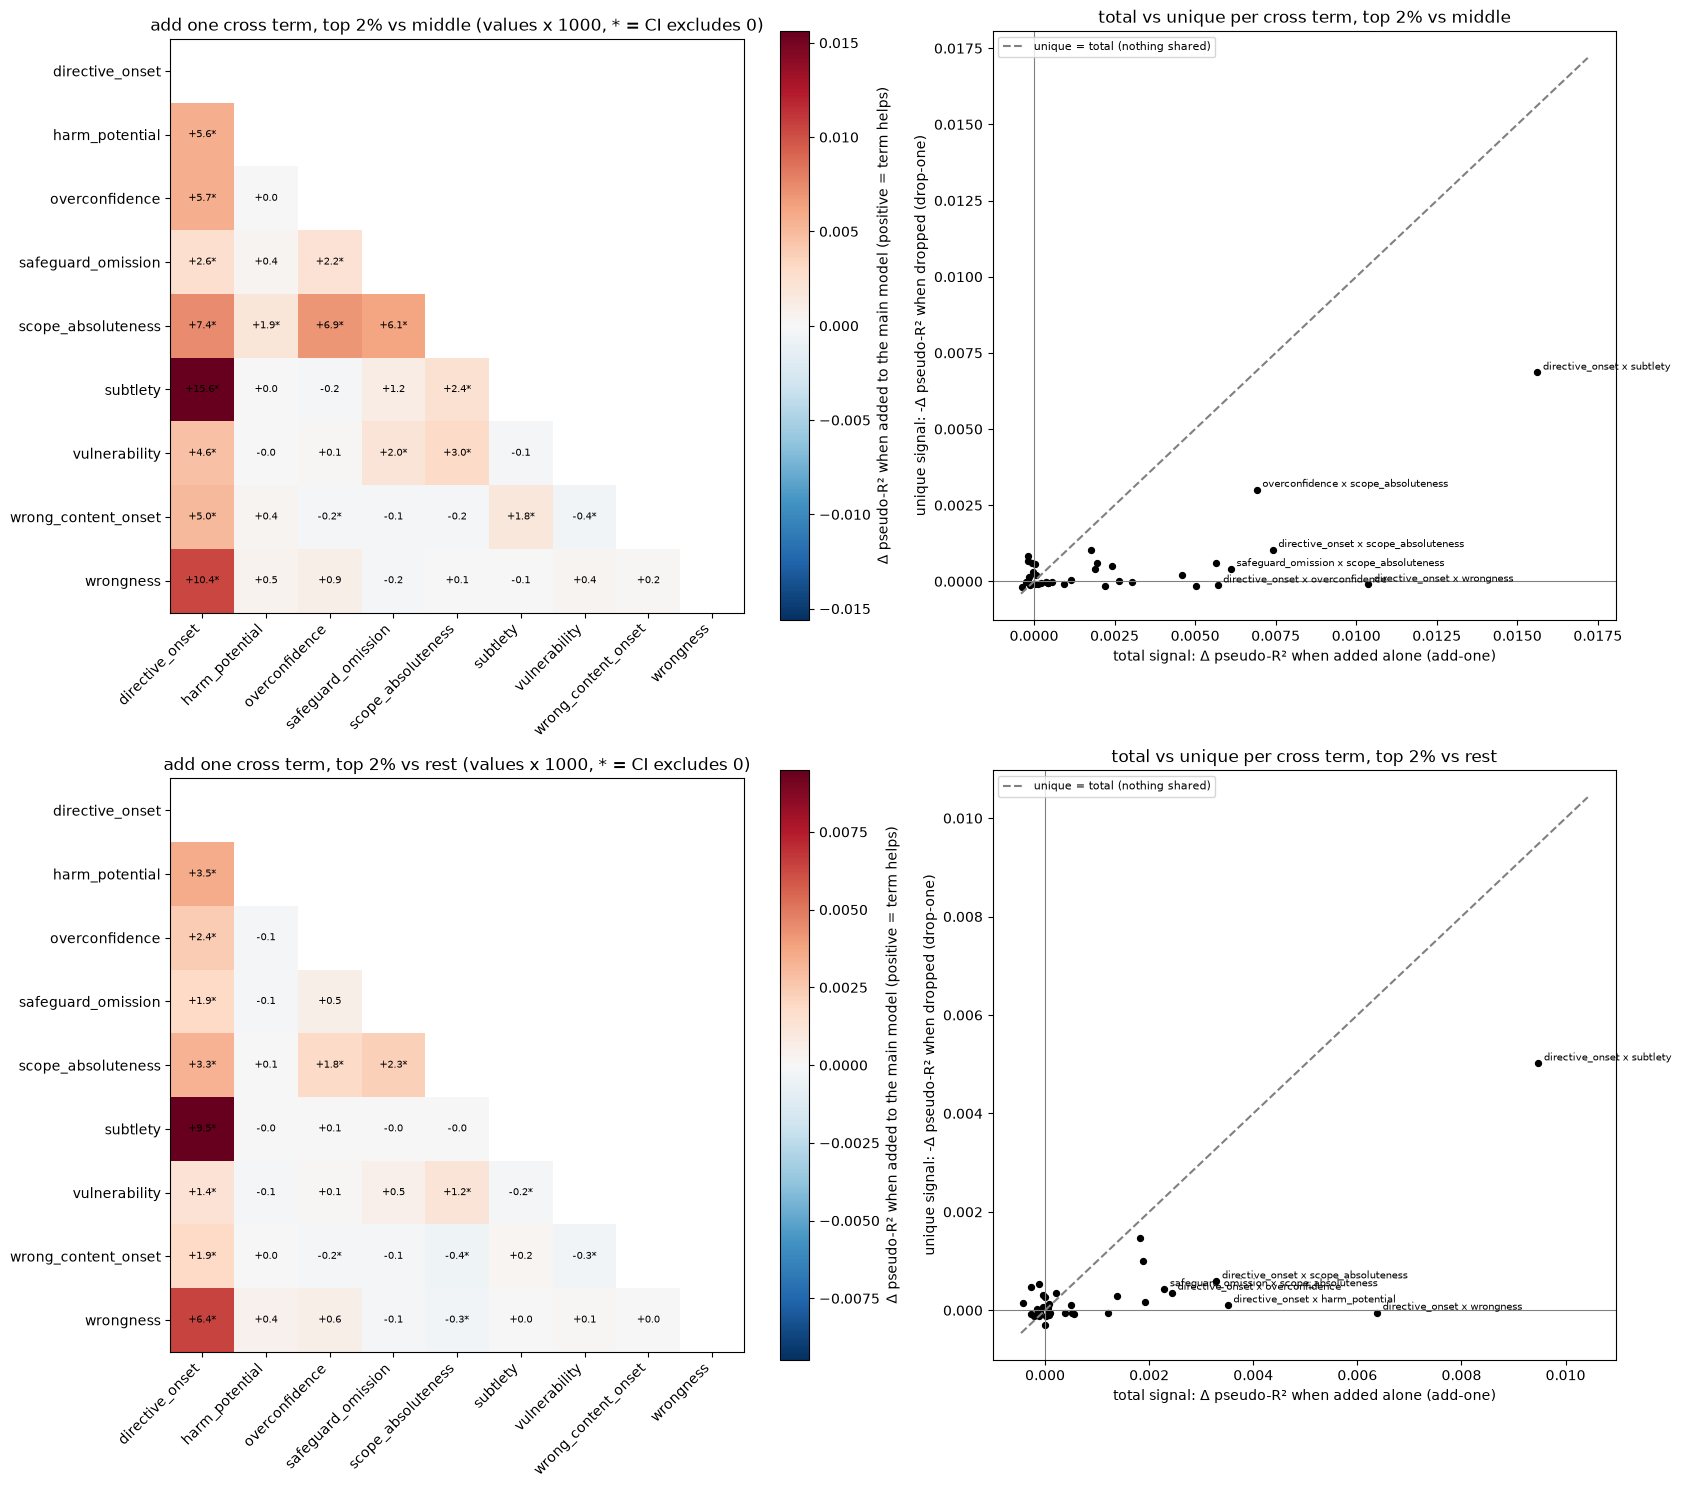

In [19]:
ADD_ONE = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    main = PRED_FULL[(contrast, False)]
    assert np.allclose(oof_predict_pairs(fd, []), main), "no-pair design must reproduce the main model"
    rows = []
    for i, j in PAIR_IDX:
        term = f"{METRICS[i]} x {METRICS[j]}"
        res = paired_delta_light(main, oof_predict_pairs(fd, [(i, j)]), fd["is_pos"], fd["doc_rows"])
        row = {"term": term}
        for k, (pt, lo, hi) in res.items():
            row |= {f"add d{k}": pt, f"add d{k} lo": lo, f"add d{k} hi": hi}
        drop = PAIR_DROP[contrast].loc[("pair", term)]
        row |= {"unique dpseudo-R2": -drop["dpseudo-R2"], "unique dAUROC": -drop["dAUROC"]}
        rows.append(row)
    ADD_ONE[contrast] = pd.DataFrame(rows).set_index("term")
    print(f"\n=== top {X_FIT}% vs {contrast}: 10 cross terms with the most total signal (add-one) ===")
    print("(unique = minus the drop-one delta, same sign convention: positive = helps)")
    print(ADD_ONE[contrast].sort_values("add dpseudo-R2", ascending=False).head(10).round(4).to_string())

n = len(METRICS)
fig, axes = plt.subplots(len(FIT_CONTRASTS), 2, figsize=(17, 7.5 * len(FIT_CONTRASTS)), squeeze=False,
                         gridspec_kw={"width_ratios": [1.15, 1]})
for row, contrast in zip(axes, FIT_CONTRASTS):
    t = ADD_ONE[contrast]
    M = np.full((n, n), np.nan)
    sig = np.zeros((n, n), bool)
    for i, j in PAIR_IDX:
        r = t.loc[f"{METRICS[i]} x {METRICS[j]}"]
        M[j, i] = r["add dpseudo-R2"]
        sig[j, i] = r["add dpseudo-R2 lo"] > 0 or r["add dpseudo-R2 hi"] < 0
    lim = np.nanmax(np.abs(M))
    im = row[0].imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
    for i, j in PAIR_IDX:
        row[0].text(i, j, f"{M[j, i] * 1000:+.1f}" + ("*" if sig[j, i] else ""), ha="center", va="center", fontsize=7)
    row[0].set_xticks(range(n), METRICS, rotation=45, ha="right")
    row[0].set_yticks(range(n), METRICS)
    fig.colorbar(im, ax=row[0], label="Δ pseudo-R² when added to the main model (positive = term helps)")
    row[0].set_title(f"add one cross term, top {X_FIT}% vs {contrast} (values x 1000, * = CI excludes 0)")

    ax = row[1]
    ax.scatter(t["add dpseudo-R2"], t["unique dpseudo-R2"], color="black", s=18)
    hi = max(t["add dpseudo-R2"].max(), t["unique dpseudo-R2"].max()) * 1.1
    lo = min(0, t["add dpseudo-R2"].min(), t["unique dpseudo-R2"].min()) * 1.1
    ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", label="unique = total (nothing shared)")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    for term, r in t.sort_values("add dpseudo-R2", ascending=False).head(6).iterrows():
        ax.annotate(term, (r["add dpseudo-R2"], r["unique dpseudo-R2"]), fontsize=7,
                    textcoords="offset points", xytext=(4, 2))
    ax.set_xlabel("total signal: Δ pseudo-R² when added alone (add-one)")
    ax.set_ylabel("unique signal: -Δ pseudo-R² when dropped (drop-one)")
    ax.set_title(f"total vs unique per cross term, top {X_FIT}% vs {contrast}")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

pd.concat(ADD_ONE, names=["contrast"]).to_csv(FIT_RESULTS_DIR / f"pair_add_one_top{X_FIT}.csv")

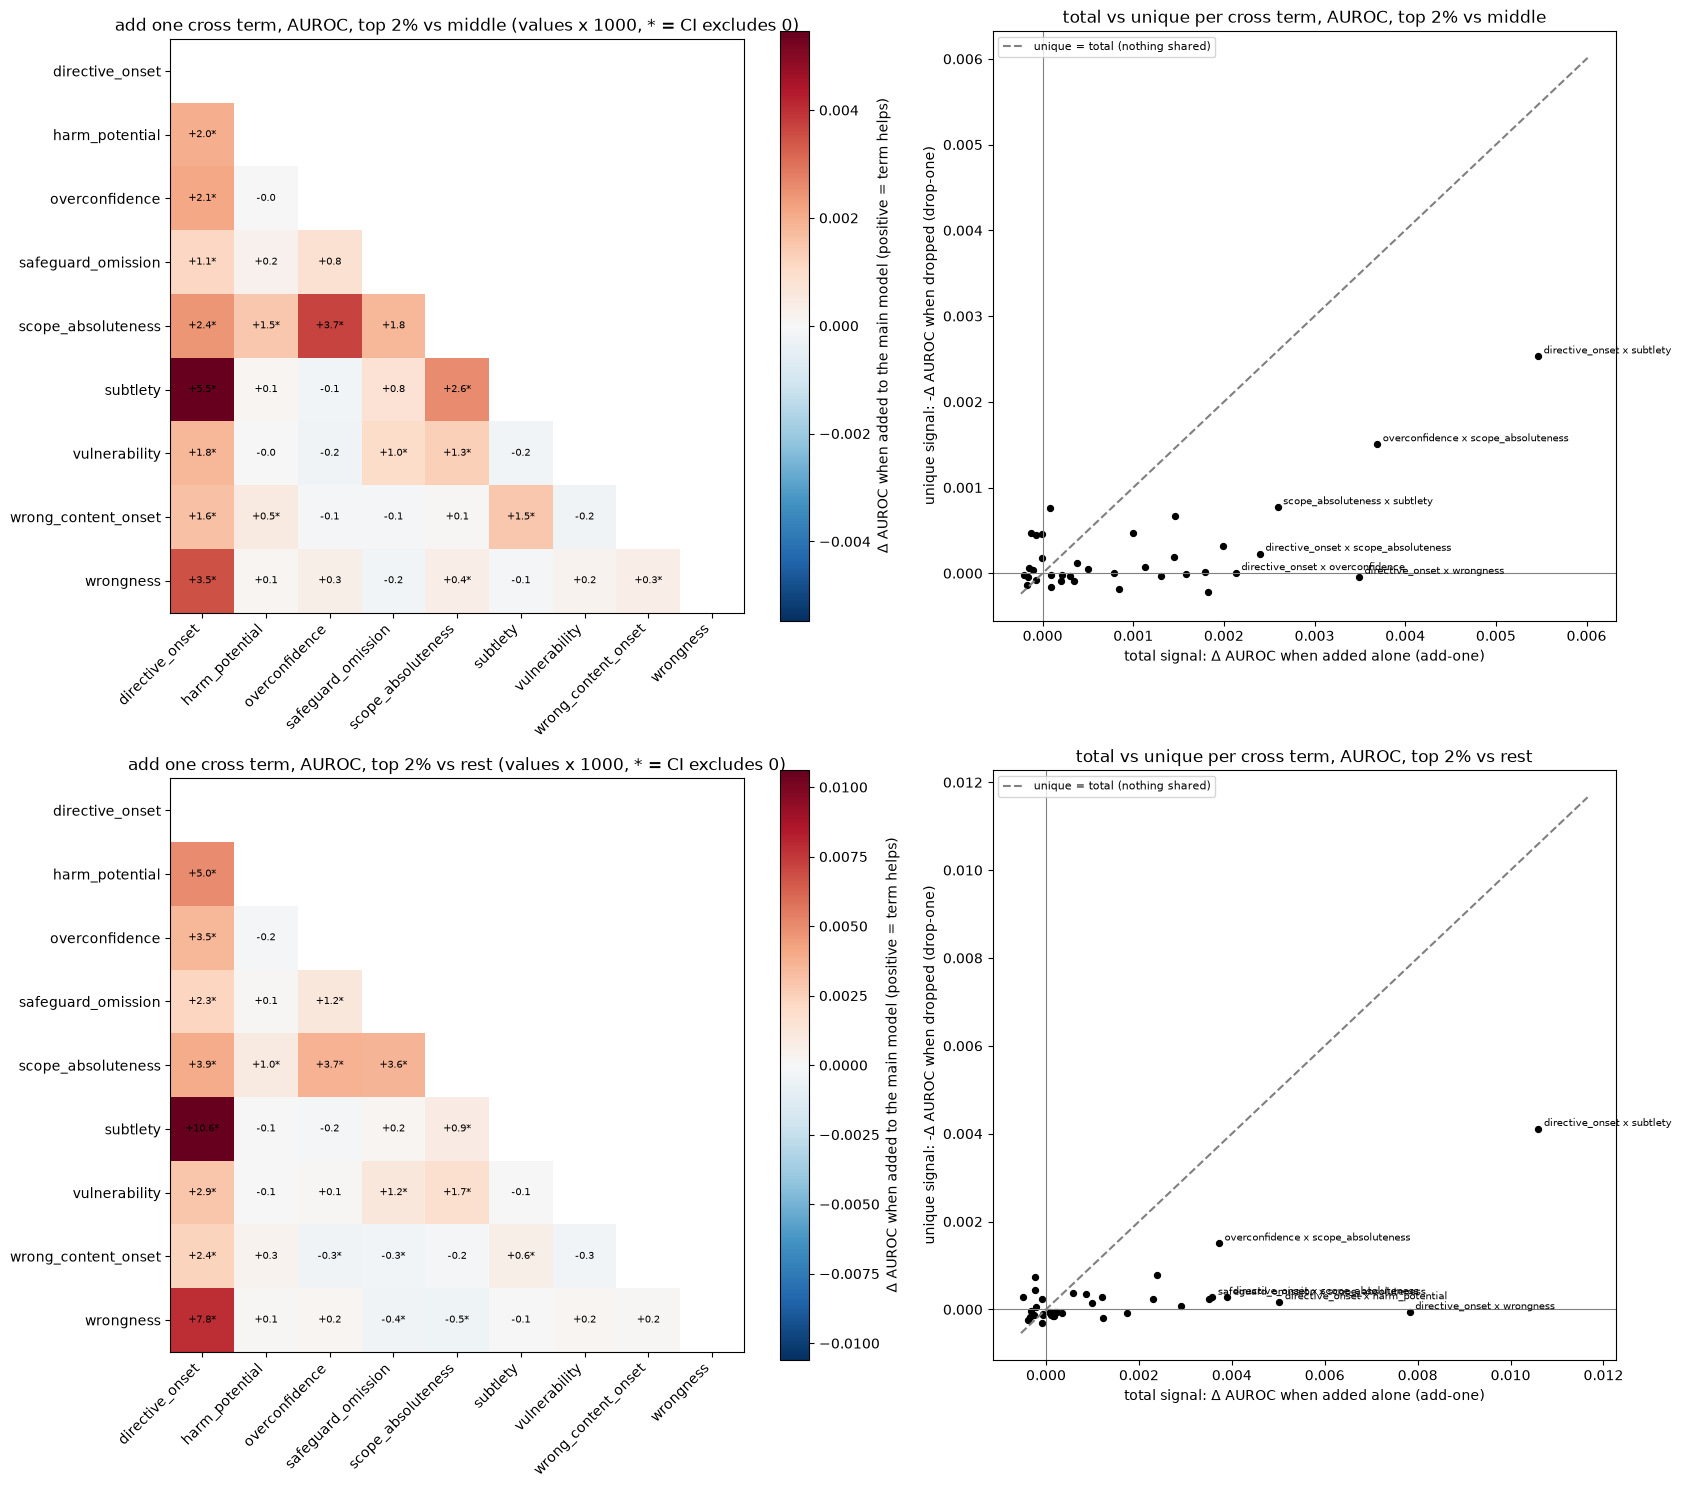

In [20]:
# Same as above in AUROC: add-one Delta AUROC (main + one product vs main) and its unique part (cross-term drop-one).
n = len(METRICS)
fig, axes = plt.subplots(len(FIT_CONTRASTS), 2, figsize=(17, 7.5 * len(FIT_CONTRASTS)), squeeze=False,
                         gridspec_kw={"width_ratios": [1.15, 1]})
for row, contrast in zip(axes, FIT_CONTRASTS):
    t = ADD_ONE[contrast]
    M = np.full((n, n), np.nan)
    sig = np.zeros((n, n), bool)
    for i, j in PAIR_IDX:
        r = t.loc[f"{METRICS[i]} x {METRICS[j]}"]
        M[j, i] = r["add dAUROC"]
        sig[j, i] = r["add dAUROC lo"] > 0 or r["add dAUROC hi"] < 0
    lim = np.nanmax(np.abs(M))
    im = row[0].imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
    for i, j in PAIR_IDX:
        row[0].text(i, j, f"{M[j, i] * 1000:+.1f}" + ("*" if sig[j, i] else ""), ha="center", va="center", fontsize=7)
    row[0].set_xticks(range(n), METRICS, rotation=45, ha="right")
    row[0].set_yticks(range(n), METRICS)
    fig.colorbar(im, ax=row[0], label="Δ AUROC when added to the main model (positive = term helps)")
    row[0].set_title(f"add one cross term, AUROC, top {X_FIT}% vs {contrast} (values x 1000, * = CI excludes 0)")

    ax = row[1]
    ax.scatter(t["add dAUROC"], t["unique dAUROC"], color="black", s=18)
    hi = max(t["add dAUROC"].max(), t["unique dAUROC"].max()) * 1.1
    lo = min(0, t["add dAUROC"].min(), t["unique dAUROC"].min()) * 1.1
    ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", label="unique = total (nothing shared)")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    for term, r in t.sort_values("add dAUROC", ascending=False).head(6).iterrows():
        ax.annotate(term, (r["add dAUROC"], r["unique dAUROC"]), fontsize=7,
                    textcoords="offset points", xytext=(4, 2))
    ax.set_xlabel("total signal: Δ AUROC when added alone (add-one)")
    ax.set_ylabel("unique signal: -Δ AUROC when dropped (drop-one)")
    ax.set_title(f"total vs unique per cross term, AUROC, top {X_FIT}% vs {contrast}")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


=== top 2% vs middle: linear terms, total (alone) vs unique (drop-one) ===
                     AUROC alone  pseudo-R2 alone      lo      hi  unique pseudo-R2 (main drop-one)
rubric                                                                                             
vulnerability             0.6612           0.0526  0.0457  0.0606                            0.0075
safeguard_omission        0.6813           0.0843  0.0745  0.0934                           -0.0002
subtlety                  0.7453           0.1058  0.0957  0.1153                            0.0021
wrongness                 0.7339           0.1089  0.0994  0.1180                           -0.0000
directive_onset           0.6958           0.1274  0.1172  0.1396                            0.0433
scope_absoluteness        0.7109           0.1280  0.1154  0.1390                            0.0023
wrong_content_onset       0.7336           0.1280  0.1151  0.1383                            0.0058
harm_potential          


=== top 2% vs rest: linear terms, total (alone) vs unique (drop-one) ===
                     AUROC alone  pseudo-R2 alone      lo      hi  unique pseudo-R2 (main drop-one)
rubric                                                                                             
vulnerability             0.6088           0.0173  0.0136  0.0209                            0.0035
safeguard_omission        0.6196           0.0286  0.0241  0.0326                            0.0003
subtlety                  0.6685           0.0333  0.0293  0.0375                            0.0002
wrongness                 0.6606           0.0358  0.0315  0.0399                            0.0001
directive_onset           0.6324           0.0408  0.0362  0.0462                            0.0118
harm_potential            0.6783           0.0471  0.0419  0.0520                            0.0003
wrong_content_onset       0.6728           0.0498  0.0440  0.0549                            0.0058
overconfidence            

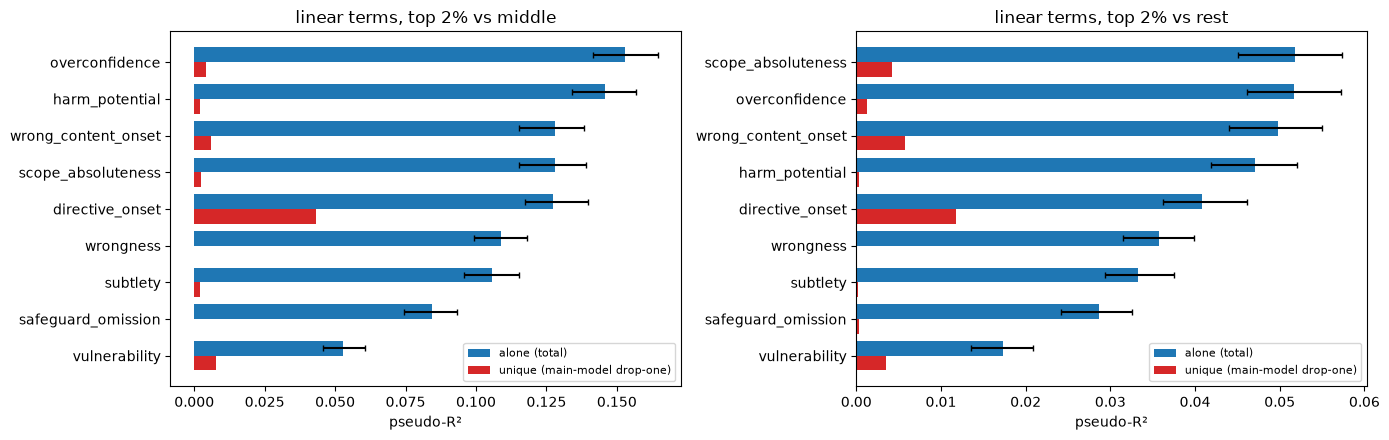

In [21]:
# Linear terms: each rubric alone (total signal) vs main-model drop-one (unique signal), in pseudo-R².
LINEAR_ADD_ONE = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    rng_b = np.random.default_rng(0)
    preds = {m: oof_predict(fd, [f"score_{m}"], cross=False) for m in METRICS}
    boots = []
    for _ in range(N_BOOT_FIT):
        r = np.concatenate([fd["doc_rows"][i] for i in rng_b.integers(0, len(fd["doc_rows"]), len(fd["doc_rows"]))])
        boots.append({m: pseudo_r2(p[r], fd["is_pos"][r]) for m, p in preds.items()})
    boots = pd.DataFrame(boots)
    LINEAR_ADD_ONE[contrast] = pd.DataFrame({
        "AUROC alone": {m: auroc(p, fd["is_pos"]) for m, p in preds.items()},
        "pseudo-R2 alone": {m: pseudo_r2(p, fd["is_pos"]) for m, p in preds.items()},
        "lo": boots.quantile(0.025), "hi": boots.quantile(0.975),
        "unique pseudo-R2 (main drop-one)": {m: -drop_table.loc[(contrast, "main", m), "dpseudo-R2"] for m in METRICS},
    }).rename_axis("rubric").sort_values("pseudo-R2 alone")
    print(f"\n=== top {X_FIT}% vs {contrast}: linear terms, total (alone) vs unique (drop-one) ===")
    print(LINEAR_ADD_ONE[contrast].round(4).to_string())

fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 4.5), squeeze=False)
for ax, contrast in zip(axes[0], FIT_CONTRASTS):
    t = LINEAR_ADD_ONE[contrast]
    ys = np.arange(len(t))
    ax.barh(ys + 0.2, t["pseudo-R2 alone"], height=0.4, color="tab:blue", label="alone (total)",
            xerr=[t["pseudo-R2 alone"] - t["lo"], t["hi"] - t["pseudo-R2 alone"]], capsize=2)
    ax.barh(ys - 0.2, t["unique pseudo-R2 (main drop-one)"], height=0.4, color="tab:red",
            label="unique (main-model drop-one)")
    ax.set_yticks(ys, t.index)
    ax.set_xlabel("pseudo-R²")
    ax.set_title(f"linear terms, top {X_FIT}% vs {contrast}")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

pd.concat(LINEAR_ADD_ONE, names=["contrast"]).to_csv(FIT_RESULTS_DIR / f"linear_add_one_top{X_FIT}.csv")

### Bottom-2% twins: does the top-2% detector also fire on the bottom 2%?

Every fit above targets the top 2%. The three plots in this section are *twins* of the single-rubric, drop-one and add-one plots: the fit is unchanged (top 2% vs middle), but each plot is drawn twice, once **evaluated on the top 2%** (positives = top, negatives = middle band, i.e. exactly the numbers above) and once **evaluated on the bottom 2%** (positives = the bottom-2% tokens, scored by the same fold models, each by the model whose training fold excluded its document; negatives = the same middle band). Metric: AUROC only, since a likelihood metric against a label the model was not fit to is meaningless. Middle fit only: under the rest fit the bottom tokens are training negatives. The last figure plots each term's top delta against its bottom delta, with a paired CI on the difference (same document draw for both twins).

**How to read it, and a caveat (red-team 4, F1).** A term whose delta is positive on both twins helps the detector on harmful *and* protective tokens; one that is positive on top and zero or negative on bottom is specific to the harmful side. But the middle band is the trough of the judge scores, so *every* percentile band scores above 0.5 against it with the same model, not just the bottom: with the joint main model, band 2–5 gives 0.77, 5–10 gives 0.72, 90–95 gives 0.67, 95–98 gives 0.70, and the bottom 2% gives 0.72. "Lifts bottom tokens" therefore cannot yet be separated from "moves tokens away from the middle-band profile". The proper null is a reference twin on a neighbouring band of the same size (95–98 or 90–95), or bottom vs the 90–98 band as negatives; that is a pending decision, not implemented here. The positives' document mix also differs between twins (top: 50% seen docs; bottom: 36% seen, 47% random_unseen); per-group AUROCs are within 0.02 of each other for both twins, so this is not a material confound (red-team 4, F2).

The code lives in `bottom_twins.py` next to this notebook (standalone runner: `run_bottom_twins.py`); this cell only passes the notebook's objects and shows the figures. The TOP twin is asserted inside `run()` to reproduce `PRED_FULL`, `drop_table`, `ADD_ONE` and `PAIR_DROP` exactly. Figures are also saved to `bottom_twins_figures/`, tables to `fit_results/bottom_twins/`. Red-team report: `rubric_eval_additions/redteam_reports/redteam4_bottom_twins.md`.

fit: top 2% vs middle, 23939 tokens (3329 top, 20610 middle); bottom 2%: 2595 tokens in 1152 documents, 0 tokens in documents outside the fit set


self-check: main and cross fits reproduce PRED_FULL


drop-one main: done


drop-one cross: done


self-check: TOP drop-one deltas reproduce drop_table


add-one / drop-one pairs: done


self-check: TOP add-one and unique deltas reproduce ADD_ONE


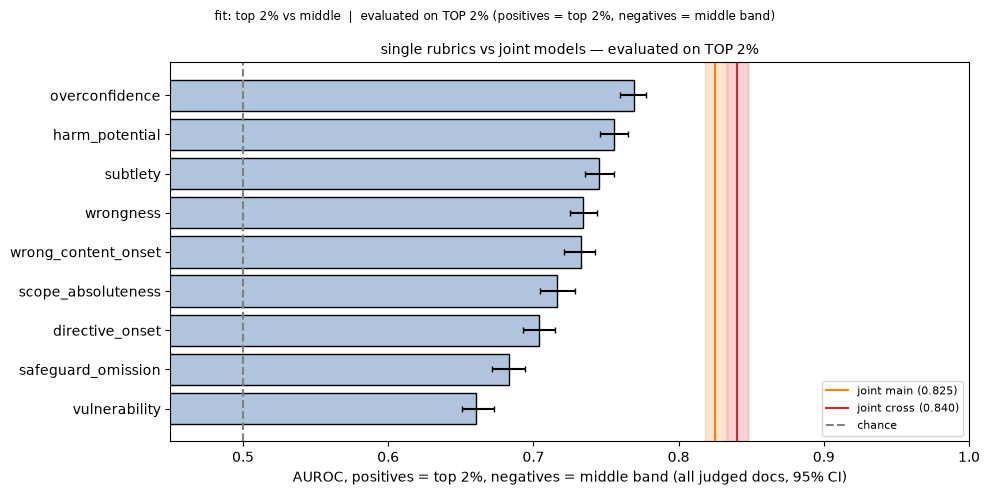

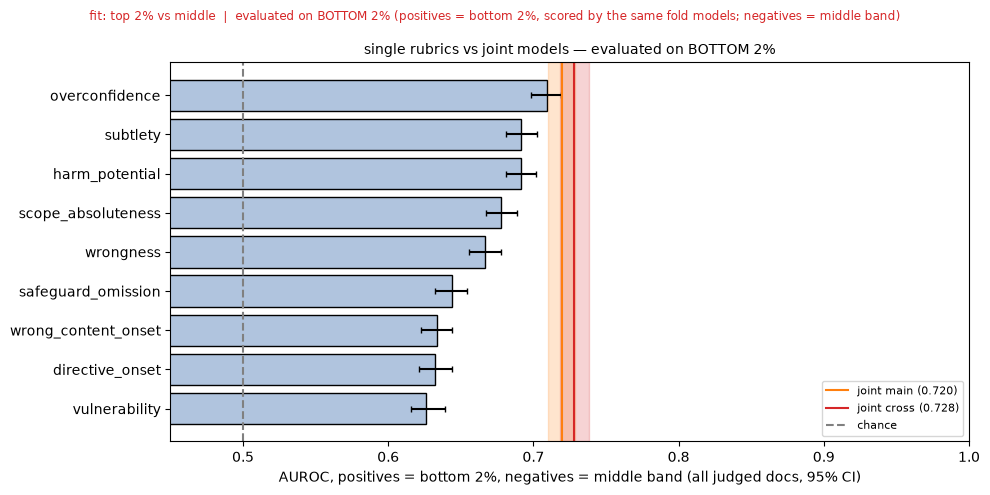

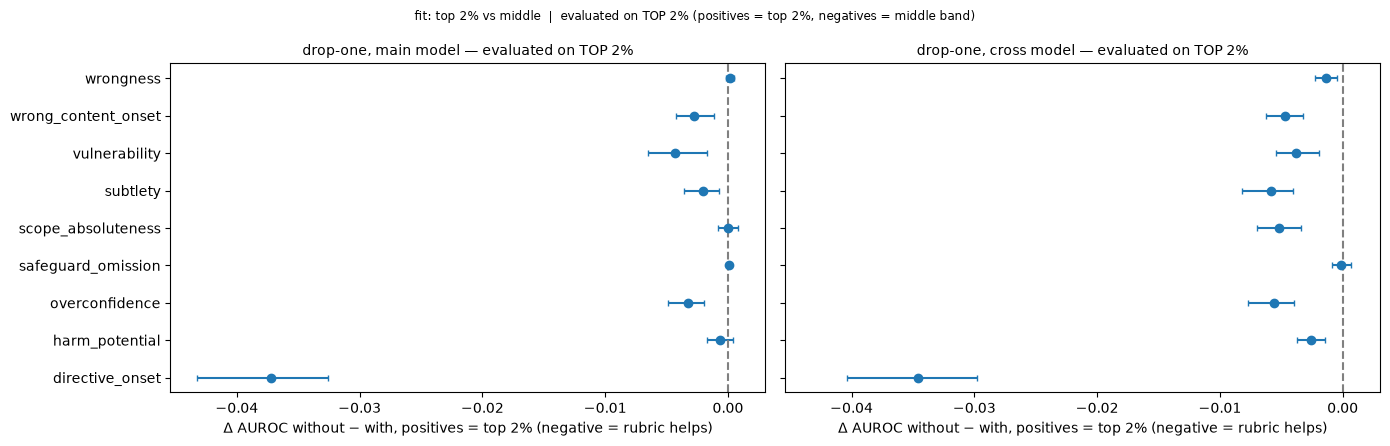

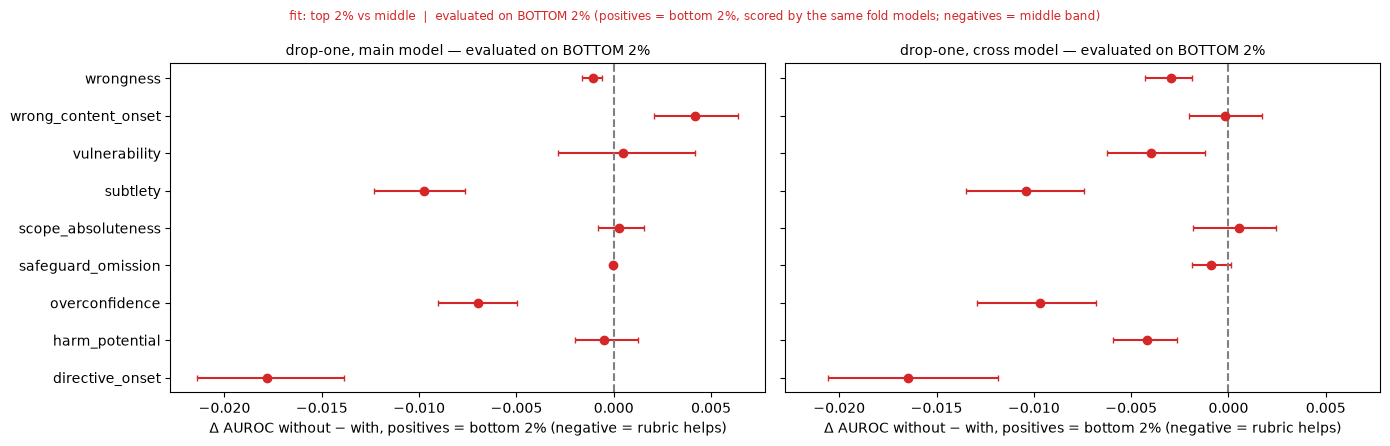

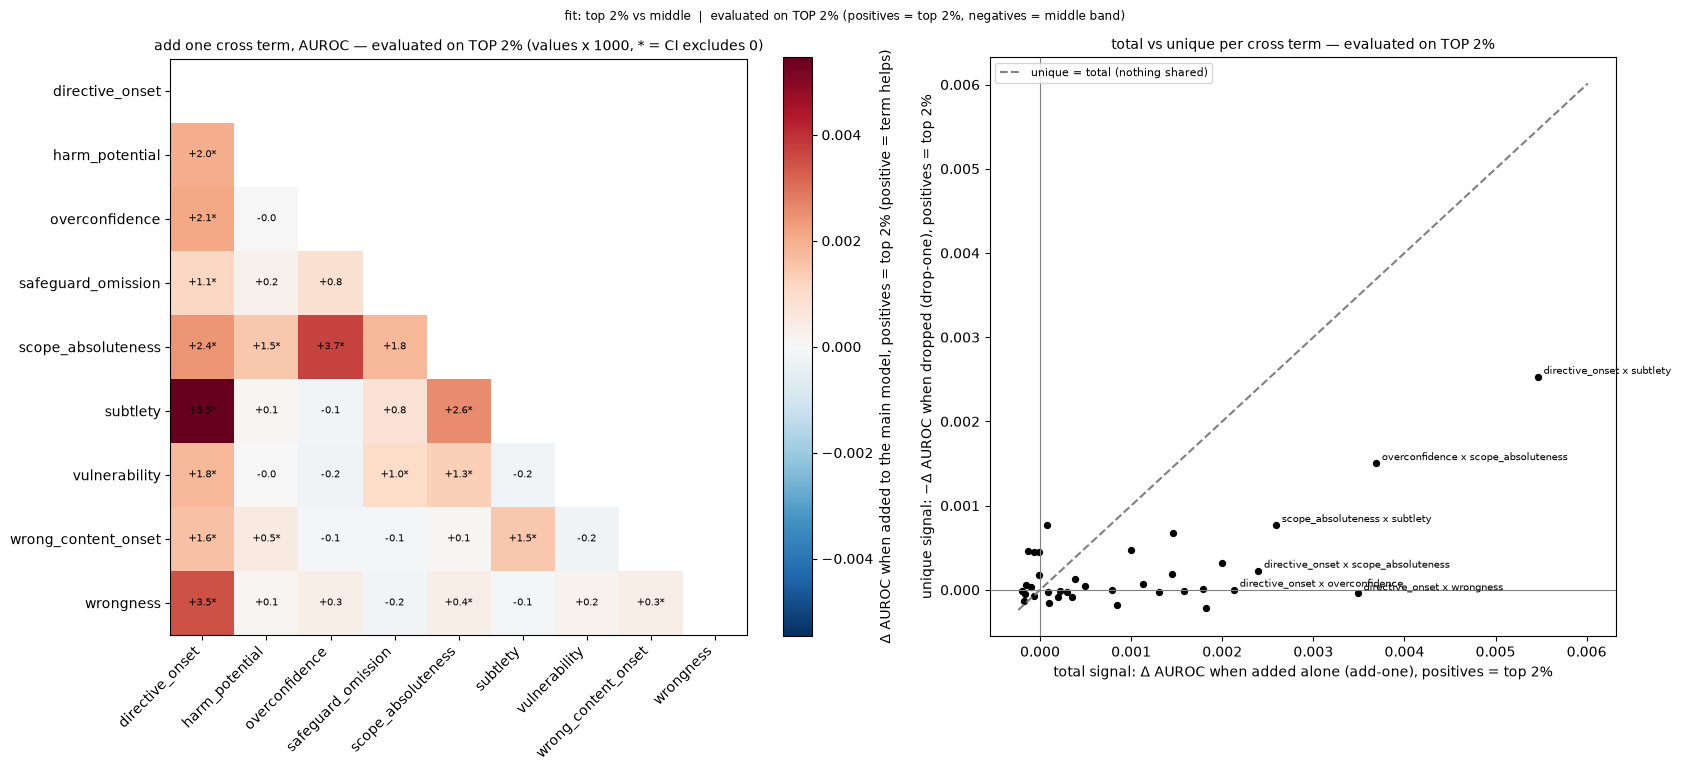

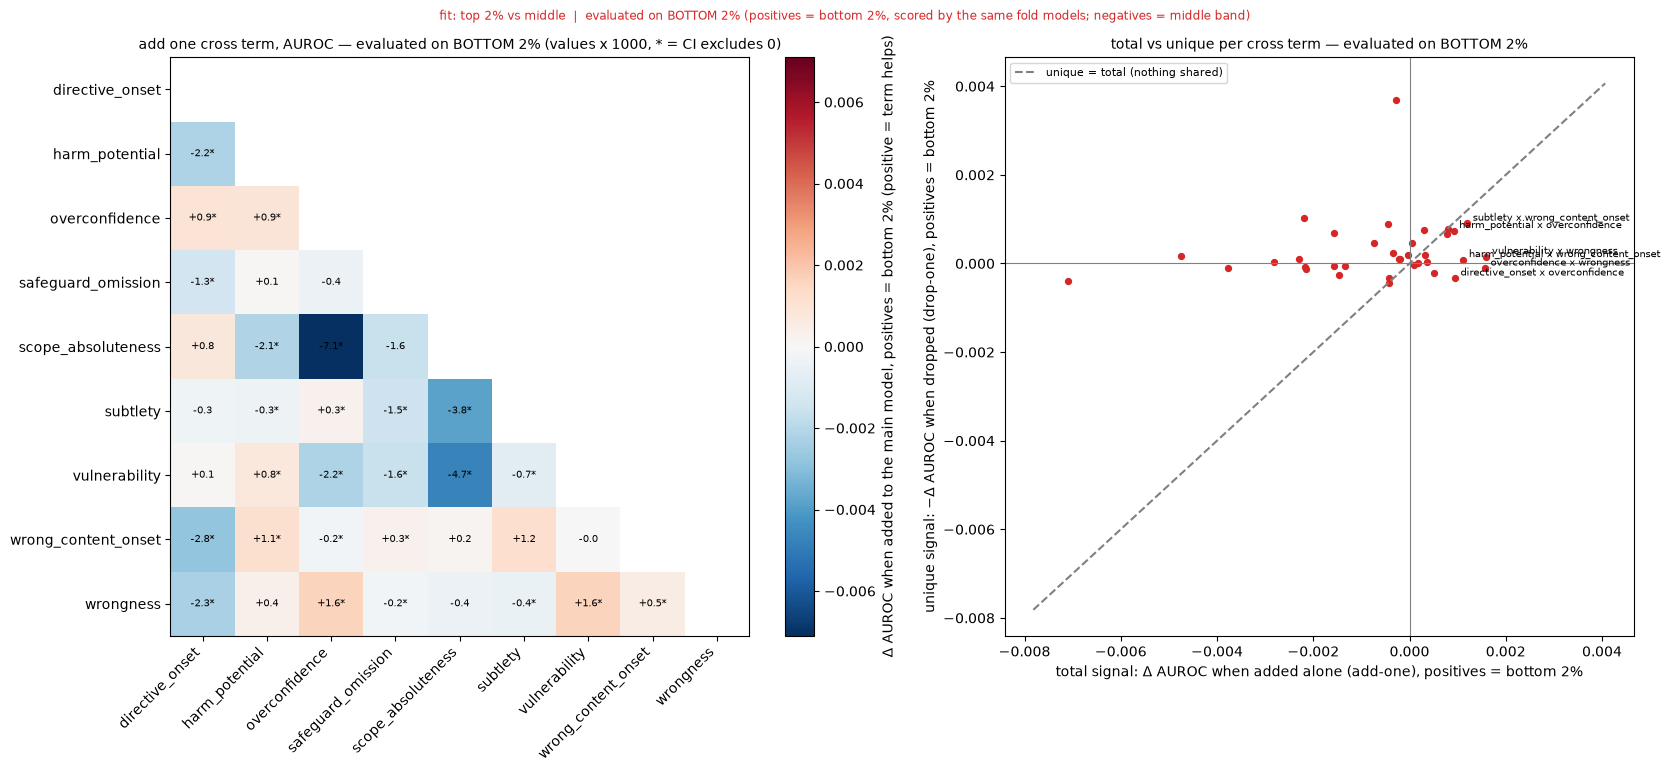

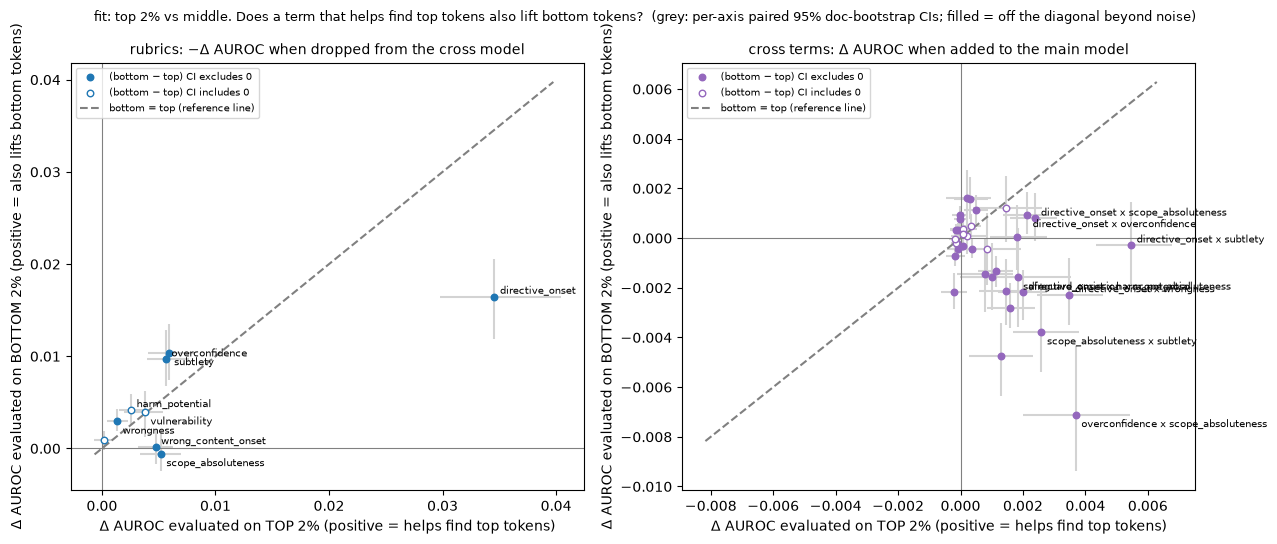

single rubrics and joint models, AUROC (positives = top / bottom, negatives = middle band)
                     top AUROC  top lo  top hi  bottom AUROC  bottom lo  bottom hi
predictor                                                                         
directive_onset          0.704   0.693   0.715         0.632      0.621      0.644
harm_potential           0.756   0.746   0.765         0.691      0.681      0.702
overconfidence           0.769   0.760   0.777         0.709      0.698      0.719
safeguard_omission       0.683   0.671   0.694         0.644      0.632      0.655
scope_absoluteness       0.717   0.704   0.729         0.678      0.668      0.689
subtlety                 0.745   0.736   0.756         0.692      0.681      0.702
vulnerability            0.661   0.651   0.673         0.626      0.616      0.639
wrong_content_onset      0.733   0.721   0.742         0.634      0.623      0.644
wrongness                0.734   0.725   0.744         0.666      0.656      0.

In [22]:
import importlib
import sys

sys.path.insert(0, str(ROOT / "em_influence/em_influence/notebooks"))
import bottom_twins
importlib.reload(bottom_twins)

TWINS = bottom_twins.run(df, FIT_DATA["middle"], METRICS, x=X_FIT, n_boot=N_BOOT_FIT,
                         out_dir=FIT_RESULTS_DIR / "bottom_twins", pred_full=PRED_FULL,
                         drop_table=drop_table, add_one=ADD_ONE, pair_drop=PAIR_DROP)
bottom_twins.plot_all(TWINS, fig_dir=ROOT / "em_influence/em_influence/notebooks/bottom_twins_figures")

print("single rubrics and joint models, AUROC (positives = top / bottom, negatives = middle band)")
print(TWINS["singles"].round(3).to_string())
print("\ndrop-one, Δ AUROC without − with (negative = rubric helps)")
print(TWINS["drop"].round(4).to_string())
print("\nadd-one cross terms, Δ AUROC (positive = term helps), 12 largest on top")
print(TWINS["add_one"].sort_values("add dAUROC top", ascending=False).round(4).head(12).to_string())

### Squared terms (z²): twins of the cross-term study

Same design as the cross-term twins, with z_j² in the role of the products. Fit: top 2% vs middle, same folds; AUROC; TOP and BOTTOM twins; paired CI on (bottom − top).

1. **Each rubric alone**: b0 + b1 z vs b0 + b1 z + b2 z². Two summaries: the paired out-of-fold log-loss delta (what the quadratic optimises; fold-additive), and a *fold-stratified* AUROC delta, i.e. AUROC computed within each fold and averaged with weights n_pos·n_neg. Within a fold the linear fit is a monotone map of the raw score, so its stratified AUROC equals the raw score's, and the stratified delta is non-zero only when the fitted quadratic is non-monotone on 0–9. A pooled out-of-fold AUROC would not do: with one feature and most tokens scored near 0, pooling five different fold maps reorders that mass by fold membership and produces deltas of −0.003 with CIs excluding zero that are exactly zero within every fold (red-team 5, F1). Also reported: the full-data b2 with its range over the five fold fits, and the turning point when it lies inside 0–9.
2. **Add one z_j²** to the main model and to the cross model. If a square helps on main but not on cross, its curvature was standing in for an interaction. (The pooling artifact is below 3e-4 for the joint models; checked against the stratified version.)
3. **Drop one z_j²** from main + all nine squares and from cross + all nine squares; unique = minus that.

Same caveat as above for the bottom twin (every band scores above 0.5 against the middle band). Code: `square_twins.py` (reuses `bottom_twins.py`); standalone runner `run_square_twins.py`. Self-checks inside `run()`: main and cross reproduce `PRED_FULL`; main + all squares reproduces an independent out-of-fold fit. `fit_logit` (cell 18 and both modules) now halves the Newton step if the penalised loss rises and raises on non-convergence; verified bitwise-identical predictions on every fit in this notebook (red-team 5).

self-check: main and cross fits reproduce PRED_FULL


per rubric linear vs quadratic: done


add-one / drop-one z² on main: done


add-one / drop-one z² on cross: done


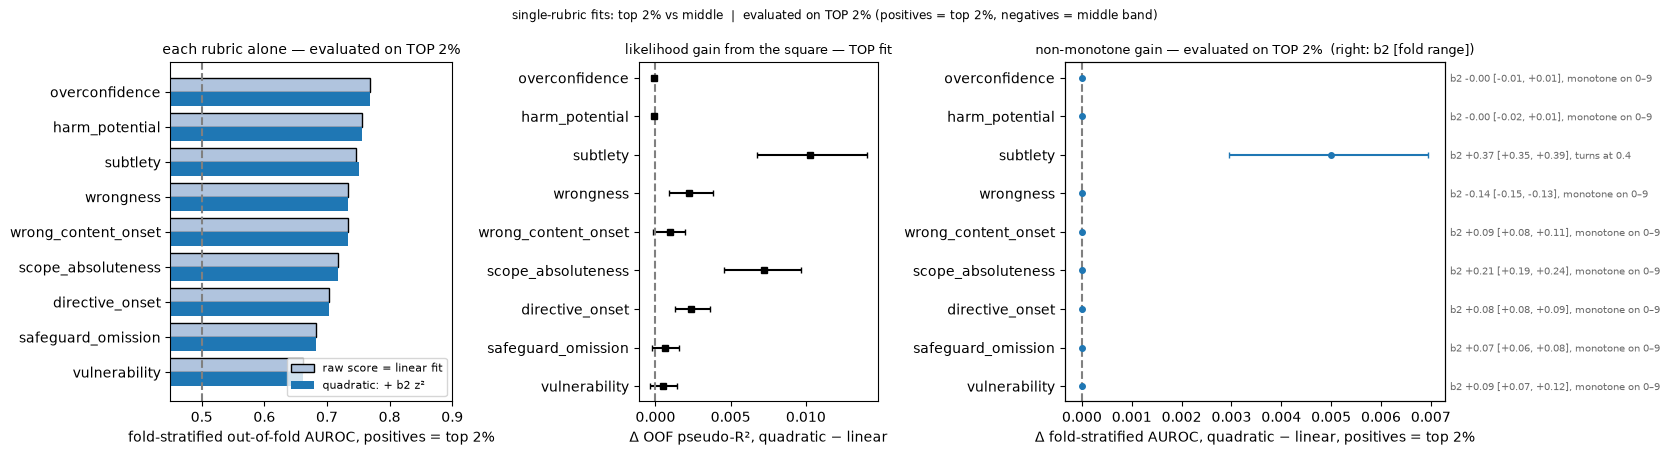

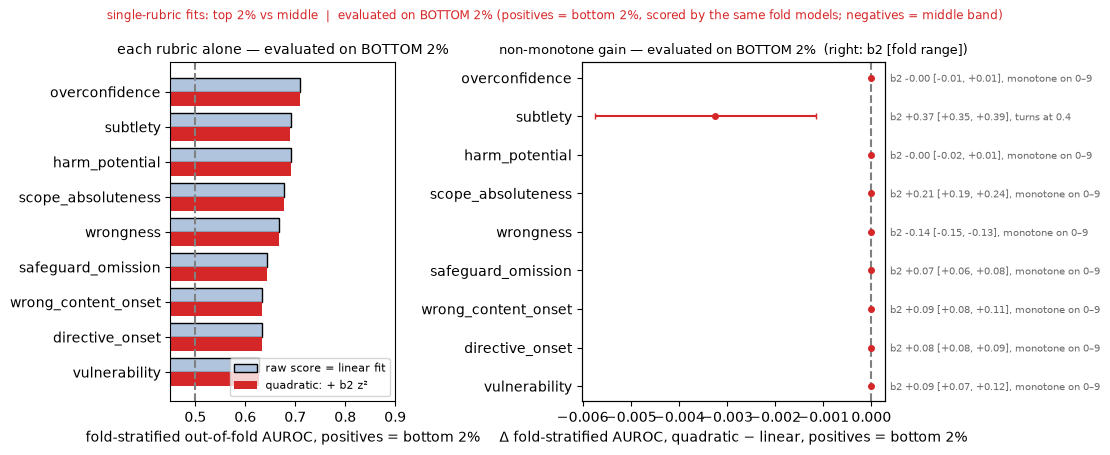

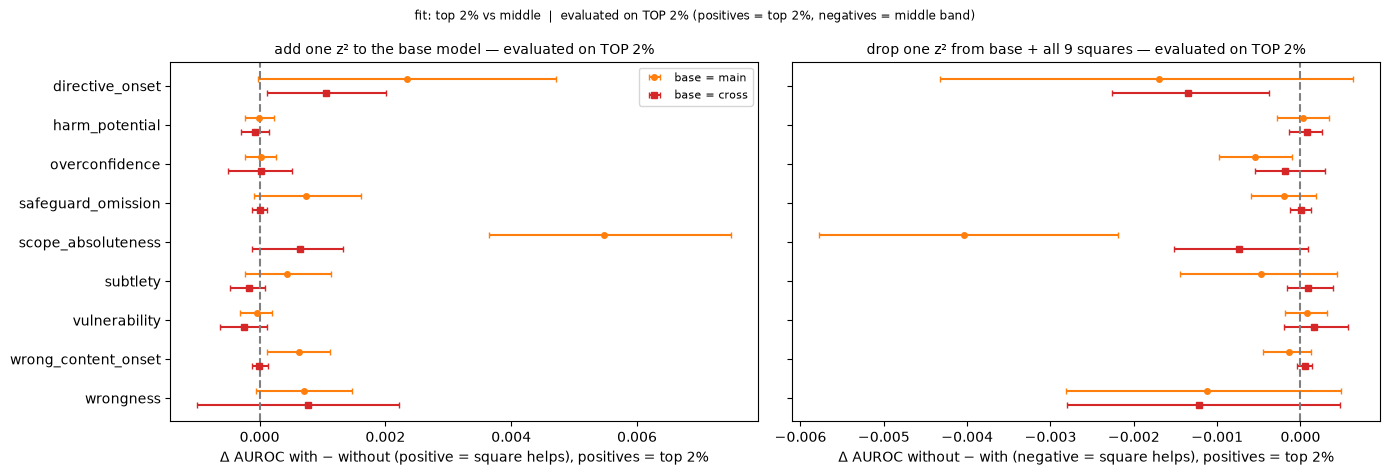

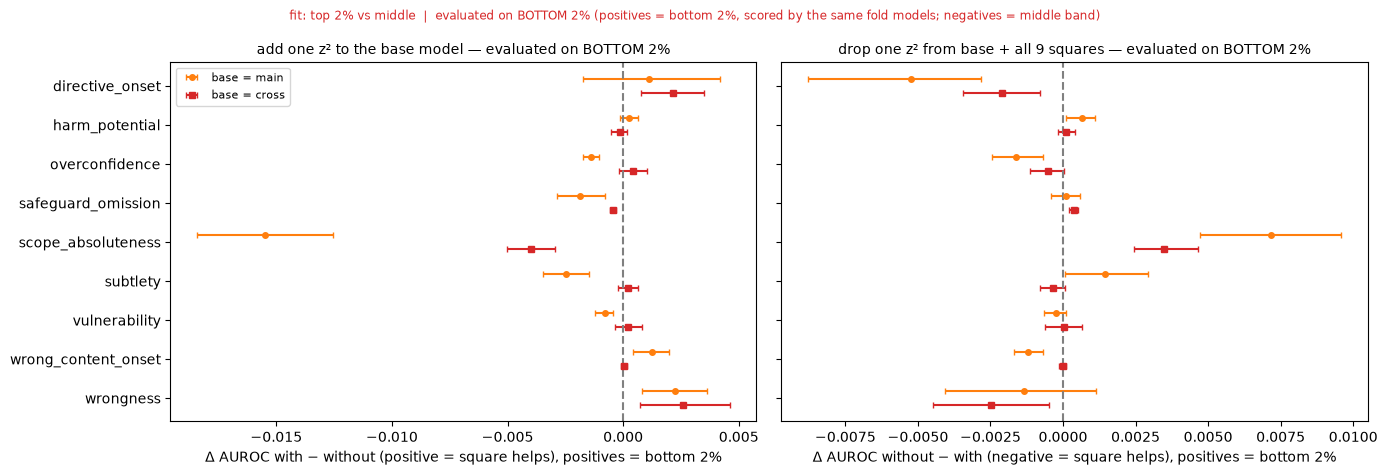

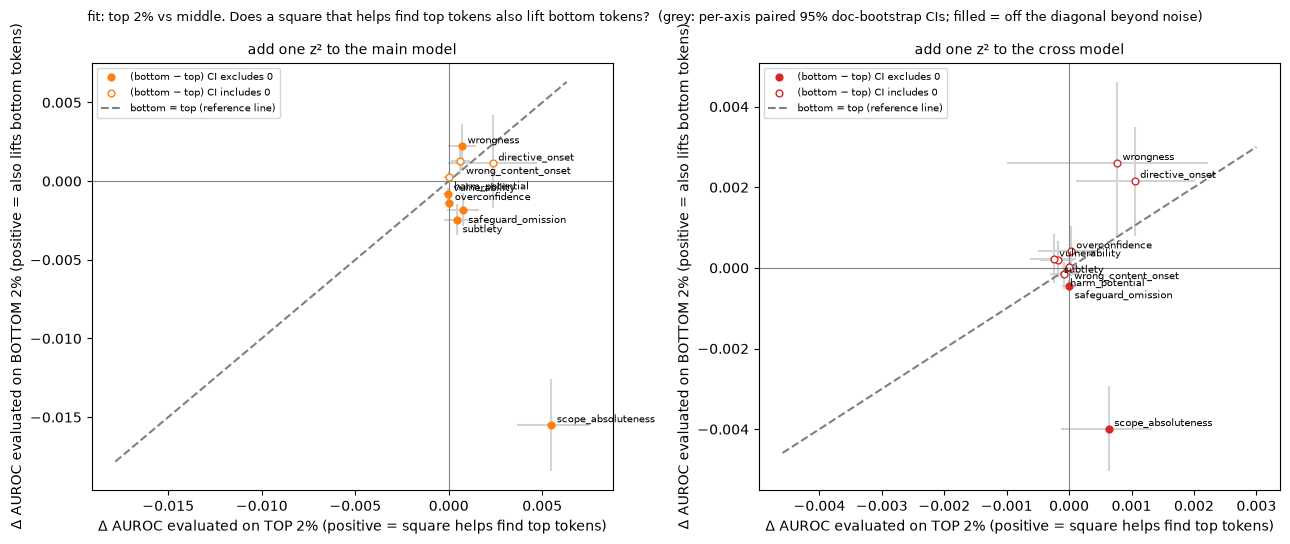

all nine squares added at once (Δ AUROC, positive = helps)
       dAUROC top  dAUROC top lo  dAUROC top hi  dAUROC bottom  dAUROC bottom lo  dAUROC bottom hi  dAUROC bottom-top  dAUROC bottom-top lo  dAUROC bottom-top hi
base                                                                                                                                                             
main       0.0093         0.0064         0.0130        -0.0060           -0.0098           -0.0008            -0.0153               -0.0207               -0.0106
cross      0.0026         0.0006         0.0046         0.0013           -0.0015            0.0040            -0.0013               -0.0044                0.0017

per rubric alone: linear vs quadratic
                     AUROC raw top (stratified)  AUROC quadratic top (stratified)  AUROC raw bottom (stratified)  AUROC quadratic bottom (stratified)  dAUROC strat top  dAUROC strat top lo  dAUROC strat top hi  dAUROC strat bottom  dAUROC strat bottom lo

In [23]:
import square_twins
importlib.reload(bottom_twins); importlib.reload(square_twins)

SQ = square_twins.run(df, FIT_DATA["middle"], METRICS, x=X_FIT, n_boot=N_BOOT_FIT,
                      out_dir=FIT_RESULTS_DIR / "bottom_twins", pred_full=PRED_FULL)
square_twins.plot_all(SQ, fig_dir=ROOT / "em_influence/em_influence/notebooks/bottom_twins_figures")

print("all nine squares added at once (Δ AUROC, positive = helps)")
print(SQ["block"].round(4).to_string())
print("\nper rubric alone: linear vs quadratic")
print(SQ["singles"].round(4).to_string())
print("\nadd one z² / drop one z² by base model")
print(SQ["sq"].round(4).to_string())

### Unique coverage: top-2% tokens that only one rubric flags

Catches the edge case AUROC averages away: a rubric may be the *only* one scoring a set of top
tokens highly. "precision" is the share of that rubric's only-this flags that are actually top-2%
(compare with the contrast's base rate).

In [24]:
UNIQUE_THR = 7

for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    high = (fd["sub"][SCORE_COLS] >= UNIQUE_THR).to_numpy()
    only_one = high.sum(1) == 1
    rows = []
    for i, metric in enumerate(METRICS):
        only = high[:, i] & only_one
        rows.append({"rubric": metric,
                     f"top-{X_FIT}% only it flags": int((only & fd["is_pos"]).sum()),
                     "its only-this flags": int(only.sum()),
                     "precision": fd["is_pos"][only].mean() if only.any() else np.nan})
    print(f"\ntop {X_FIT}% vs {contrast} (base rate {fd['is_pos'].mean():.3f}), flag = score >= {UNIQUE_THR}")
    print(pd.DataFrame(rows).set_index("rubric").sort_values(f"top-{X_FIT}% only it flags", ascending=False)
          .round(2).to_string())


top 2% vs middle (base rate 0.139), flag = score >= 7
                     top-2% only it flags  its only-this flags  precision
rubric                                                                   
wrong_content_onset                   234                  684       0.34
directive_onset                       179                  195       0.92
wrongness                             147                  984       0.15
safeguard_omission                    138                  490       0.28
scope_absoluteness                     37                   46       0.80
overconfidence                          6                   19       0.32
harm_potential                          0                    2       0.00
subtlety                                0                    8       0.00
vulnerability                           0                    0        NaN

top 2% vs rest (base rate 0.032), flag = score >= 7
                     top-2% only it flags  its only-this flags  precision
rubr

### Backward elimination (cross-term model), selected on non-random docs, evaluated on random_unseen

Removes one rubric at a time, each step dropping the one whose removal costs the least out-of-fold AP,
and re-evaluates after every removal (correlated rubrics can each look free to drop while dropping
both hurts). Selection uses only `seen` + `heldout_b4` + `nofirst_only`; the chosen set and the full
set are then fit on those documents and scored on the untouched `random_unseen` documents.

In [25]:
SELECT_GROUPS = ["seen", "heldout_b4", "nofirst_only"]
EVAL_GROUP = "random_unseen"
TOL_AP = 0.005  # stop once a single removal costs more out-of-fold AP than this


def fit_and_score(fd, cols, train_rows, test_rows, cross=True):
    S = fd["sub"][cols].to_numpy()
    Ztr, Zte = standardize(S[train_rows], S[test_rows])
    beta = fit_logit(design(Ztr, cross), fd["is_pos"][train_rows].astype(float))
    return fit_metrics(design(Zte, cross) @ beta, fd["is_pos"][test_rows])


SELECTED = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    sel_rows = np.flatnonzero(fd["sub"]["group"].isin(SELECT_GROUPS).to_numpy())
    eval_rows = np.flatnonzero((fd["sub"]["group"] == EVAL_GROUP).to_numpy())
    is_pos_sel = fd["is_pos"][sel_rows]

    current = list(SCORE_COLS)
    current_ap = average_precision(oof_predict(fd, current, True, sel_rows), is_pos_sel)
    full_ap = current_ap
    print(f"\n=== top {X_FIT}% vs {contrast}: selection on {len(sel_rows)} tokens, all {len(current)} rubrics AP={full_ap:.3f} ===")
    while len(current) > 1:
        trial = {c: average_precision(oof_predict(fd, [x for x in current if x != c], True, sel_rows), is_pos_sel)
                 for c in current}
        cand = max(trial, key=trial.get)
        loss = current_ap - trial[cand]
        if loss > TOL_AP:
            print(f"  stop: cheapest removal ({cand.removeprefix('score_')}) would cost {loss:.3f} AP > {TOL_AP}")
            break
        current.remove(cand)
        current_ap = trial[cand]
        print(f"  drop {cand.removeprefix('score_'):>20}: AP={current_ap:.3f} (step {-loss:+.3f}, "
              f"cumulative {current_ap - full_ap:+.3f})")
    SELECTED[contrast] = current
    print(f"  kept: {[c.removeprefix('score_') for c in current]}")

    rows = []
    for name, cols in [("all rubrics", SCORE_COLS), ("selected", current)]:
        rows.append({"set": name, "n rubrics": len(cols), **fit_and_score(fd, cols, sel_rows, eval_rows)})
    print(f"  held-out evaluation on {EVAL_GROUP} ({len(eval_rows)} tokens, base rate {fd['is_pos'][eval_rows].mean():.3f}):")
    print(pd.DataFrame(rows).set_index("set").round(3).to_string())


=== top 2% vs middle: selection on 9726 tokens, all 9 rubrics AP=0.656 ===


  drop   safeguard_omission: AP=0.657 (step +0.000, cumulative +0.000)
  drop       harm_potential: AP=0.654 (step -0.003, cumulative -0.002)


  drop        vulnerability: AP=0.652 (step -0.002, cumulative -0.004)
  drop            wrongness: AP=0.648 (step -0.004, cumulative -0.009)
  stop: cheapest removal (wrong_content_onset) would cost 0.010 AP > 0.005
  kept: ['directive_onset', 'overconfidence', 'scope_absoluteness', 'subtlety', 'wrong_content_onset']
  held-out evaluation on random_unseen (14213 tokens, base rate 0.071):
             n rubrics  AUROC     AP  R-prec
set                                         
all rubrics          9  0.850  0.474   0.460
selected             5  0.842  0.447   0.449



=== top 2% vs rest: selection on 39734 tokens, all 9 rubrics AP=0.200 ===


  drop   safeguard_omission: AP=0.200 (step +0.000, cumulative +0.000)


  drop       harm_potential: AP=0.200 (step +0.000, cumulative +0.000)


  drop        vulnerability: AP=0.196 (step -0.004, cumulative -0.004)


  stop: cheapest removal (wrongness) would cost 0.007 AP > 0.005
  kept: ['directive_onset', 'overconfidence', 'scope_absoluteness', 'subtlety', 'wrong_content_onset', 'wrongness']
  held-out evaluation on random_unseen (65356 tokens, base rate 0.015):
             n rubrics  AUROC     AP  R-prec
set                                         
all rubrics          9  0.766  0.072   0.135
selected             6  0.757  0.072   0.130


### Per-rubric weights (main-effects logistic) and unique signal

Log-odds per 1 SD of rubric score, holding the others fixed; exp(weight) = odds ratio per SD.
Full-data fit, for interpretation only. Correlated rubrics share weight and suppressors go negative,
so read it next to:

- **AUROC alone**: the rubric by itself;
- **residual AUROC**: AUROC of the part of the rubric the other rubrics can't explain (linear residual).
  ~0.5 = redundant; < 0.5 = suppressor (subtracts something from the others); > 0.5 = unique signal.


top 2% vs middle (intercept -2.31)
                     weight (log-odds/SD)  odds ratio/SD  AUROC alone  residual AUROC
rubric                                                                               
vulnerability                      -0.376          0.687        0.661           0.478
wrongness                          -0.080          0.923        0.734           0.493
safeguard_omission                 -0.001          0.999        0.683           0.522
scope_absoluteness                  0.213          1.237        0.717           0.523
harm_potential                      0.263          1.301        0.756           0.547
wrong_content_onset                 0.285          1.330        0.733           0.575
subtlety                            0.313          1.367        0.745           0.530
overconfidence                      0.345          1.411        0.769           0.549
directive_onset                     0.536          1.709        0.704           0.543


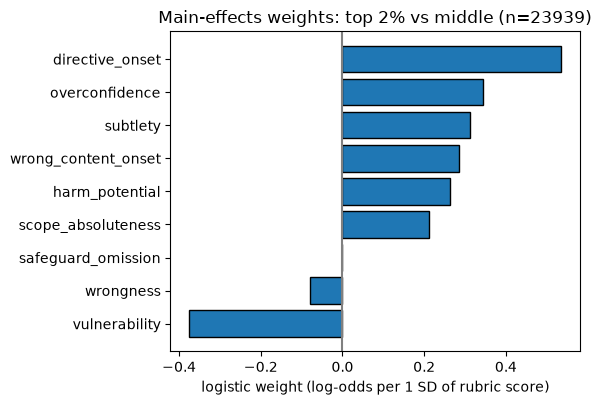


top 2% vs rest (intercept -3.74)
                     weight (log-odds/SD)  odds ratio/SD  AUROC alone  residual AUROC
rubric                                                                               
vulnerability                      -0.277          0.758        0.609           0.476
wrongness                          -0.086          0.917        0.661           0.489
safeguard_omission                 -0.071          0.932        0.618           0.510
subtlety                            0.105          1.111        0.669           0.503
harm_potential                      0.128          1.137        0.678           0.514
overconfidence                      0.206          1.229        0.688           0.534
directive_onset                     0.289          1.336        0.638           0.537
scope_absoluteness                  0.296          1.344        0.658           0.546
wrong_content_onset                 0.322          1.379        0.672           0.581


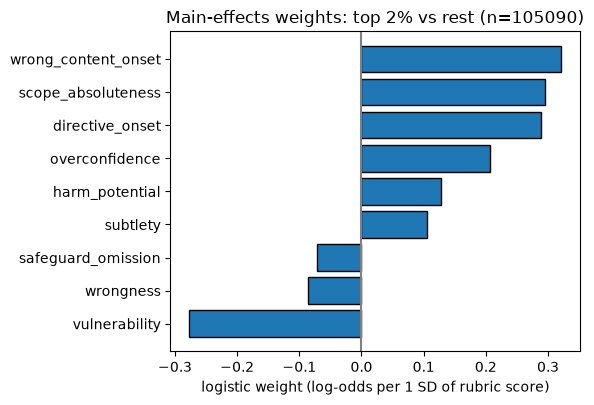

In [26]:
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    beta = fit_logit(design(Z, cross=False), fd["is_pos"].astype(float))
    rows = []
    for i, metric in enumerate(METRICS):
        others = np.column_stack([np.ones(len(Z)), np.delete(Z, i, axis=1)])
        resid = Z[:, i] - others @ np.linalg.lstsq(others, Z[:, i], rcond=None)[0]
        rows.append({"rubric": metric, "weight (log-odds/SD)": beta[1 + i], "odds ratio/SD": np.exp(beta[1 + i]),
                     "AUROC alone": auroc(Z[:, i], fd["is_pos"]), "residual AUROC": auroc(resid, fd["is_pos"])})
    table = pd.DataFrame(rows).set_index("rubric").sort_values("weight (log-odds/SD)")
    print(f"\ntop {X_FIT}% vs {contrast} (intercept {beta[0]:.2f})")
    print(table.round(3).to_string())

    plt.figure(figsize=(6, 0.35 * len(METRICS) + 1))
    plt.barh(table.index, table["weight (log-odds/SD)"], edgecolor="black")
    plt.axvline(0, color="gray")
    plt.xlabel("logistic weight (log-odds per 1 SD of rubric score)")
    plt.title(f"Main-effects weights: top {X_FIT}% vs {contrast} (n={len(fd['sub'])})")
    plt.tight_layout()
    plt.show()

### Redundancy: how well can the other rubrics rebuild each rubric?

R² of an ordinary least-squares regression of one rubric's standardized score on the others. When a
rubric is dropped, the refit can only replace it with what the remaining terms can express, so:

- **R² main**: others' main terms only (linear), which is what the main model can use to compensate;
- **R² cross**: others + all their pairwise products, which is what the cross model can use.

High R² = mostly redundant, so dropping it costs little even if its weight is large. Lost predictive
variance ~ beta² x (1 - R²). VIF = 1 / (1 - R²). Unweighted, so an approximation: the logistic refit
weights tokens by p(1-p).


top 2% vs middle: R² of each rubric from the others (dAP = drop-one, negative = helps)
                     R2 main  R2 cross  VIF main  VIF cross  dAP main  dAP cross
rubric                                                                          
directive_onset        0.210     0.264     1.266      1.358    -0.041     -0.069
vulnerability          0.467     0.497     1.876      1.986    -0.009     -0.005
wrong_content_onset    0.530     0.563     2.128      2.286    -0.008     -0.009
safeguard_omission     0.545     0.569     2.198      2.319     0.000     -0.003
scope_absoluteness     0.665     0.680     2.982      3.120    -0.005     -0.021
subtlety               0.748     0.789     3.966      4.750     0.000     -0.010
harm_potential         0.757     0.775     4.119      4.453    -0.003     -0.005
overconfidence         0.769     0.797     4.336      4.916    -0.004     -0.011
wrongness              0.796     0.805     4.905      5.118    -0.001     -0.006



top 2% vs rest: R² of each rubric from the others (dAP = drop-one, negative = helps)
                     R2 main  R2 cross  VIF main  VIF cross  dAP main  dAP cross
rubric                                                                          
directive_onset        0.174     0.220     1.210      1.282    -0.004     -0.018
vulnerability          0.500     0.525     2.000      2.106     0.001     -0.002
safeguard_omission     0.538     0.568     2.164      2.314    -0.001     -0.001
wrong_content_onset    0.542     0.579     2.183      2.377    -0.008     -0.010
scope_absoluteness     0.662     0.676     2.962      3.090    -0.006     -0.008
harm_potential         0.760     0.776     4.173      4.467    -0.001     -0.000
overconfidence         0.762     0.787     4.205      4.688    -0.001     -0.004
subtlety               0.769     0.816     4.330      5.439     0.001     -0.007
wrongness              0.814     0.821     5.379      5.596    -0.001     -0.003


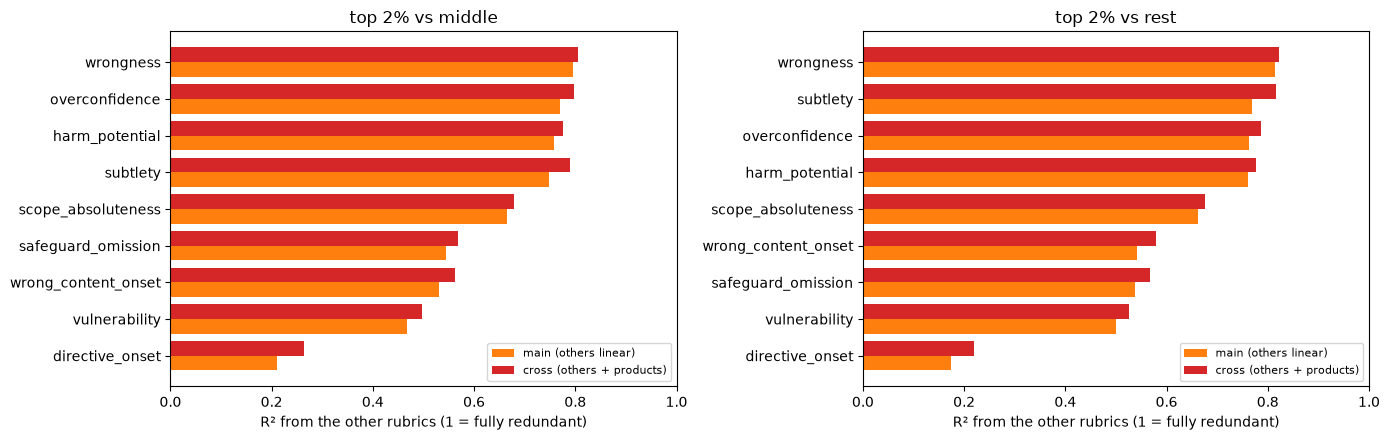

In [27]:
def redundancy_r2(Z, i, cross):
    others = design(np.delete(Z, i, axis=1), cross)
    resid = Z[:, i] - others @ np.linalg.lstsq(others, Z[:, i], rcond=None)[0]
    return 1 - resid.var() / Z[:, i].var()


R2_TABLES = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    rows = []
    for i, metric in enumerate(METRICS):
        r2_main, r2_cross = redundancy_r2(Z, i, False), redundancy_r2(Z, i, True)
        rows.append({"rubric": metric, "R2 main": r2_main, "R2 cross": r2_cross,
                     "VIF main": 1 / (1 - r2_main), "VIF cross": 1 / (1 - r2_cross),
                     "dAP main": drop_table.loc[(contrast, "main", metric), "dAP"],
                     "dAP cross": drop_table.loc[(contrast, "cross", metric), "dAP"]})
    R2_TABLES[contrast] = pd.DataFrame(rows).set_index("rubric").sort_values("R2 main")
    print(f"\ntop {X_FIT}% vs {contrast}: R² of each rubric from the others (dAP = drop-one, negative = helps)")
    print(R2_TABLES[contrast].round(3).to_string())

fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 4.5), sharex=True, squeeze=False)
for ax, contrast in zip(axes[0], FIT_CONTRASTS):
    t = R2_TABLES[contrast]
    ys = np.arange(len(t))
    ax.barh(ys - 0.2, t["R2 main"], height=0.4, color="tab:orange", label="main (others linear)")
    ax.barh(ys + 0.2, t["R2 cross"], height=0.4, color="tab:red", label="cross (others + products)")
    ax.set_yticks(ys, t.index)
    ax.set_xlim(0, 1)
    ax.set_xlabel("R² from the other rubrics (1 = fully redundant)")
    ax.set_title(f"top {X_FIT}% vs {contrast}")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### Common factor: how much of the rubrics is one shared signal?

PCA on the standardized rubric scores (correlation matrix). If PC1 carries most of the variance and
every rubric loads on it about equally, the rubrics share one general factor, and the "best single
rubric" is mostly the one closest to it.

- **PC1 / mean z**: AUROC of the first component and of the plain average of all z-scores, with
  document-bootstrap CIs, against the best single rubric and the joint cross model.
- **AUROC after removing PC1**: each rubric with its PC1 projection subtracted, i.e. its specific part.
  > 0.5 = specific signal beyond the common factor; < 0.5 = the specific part points away from the top
  tokens (suppressor-like).

Whether PC1 is a real shared property (misaligned passages score high on everything) or a judge
halo (the judge raises every rubric on salient tokens) can't be told from this data; a control rubric
unrelated to misalignment would separate the two.


=== top 2% vs middle ===
variance share PC1..PC5: [0.61  0.105 0.084 0.065 0.042]
                              AUROC     lo     hi
PC1                           0.787  0.779  0.796
mean z                        0.795  0.787  0.804
best single (overconfidence)  0.769  0.760  0.777
joint cross                   0.840  0.833  0.848

                     PC1 loading  corr with PC1  AUROC alone  AUROC after removing PC1
rubric                                                                                
subtlety                   0.352          0.824        0.745                     0.421
vulnerability              0.308          0.721        0.661                     0.423
wrongness                  0.362          0.848        0.734                     0.426
safeguard_omission         0.316          0.740        0.683                     0.488
harm_potential             0.383          0.897        0.756                     0.492
directive_onset            0.186          0.436        0.


=== top 2% vs rest ===
variance share PC1..PC5: [0.611 0.107 0.088 0.06  0.043]
                              AUROC     lo     hi
PC1                           0.702  0.693  0.711
mean z                        0.708  0.699  0.717
best single (overconfidence)  0.688  0.679  0.698
joint cross                   0.753  0.745  0.762

                     PC1 loading  corr with PC1  AUROC alone  AUROC after removing PC1
rubric                                                                                
subtlety                   0.356          0.836        0.669                     0.430
vulnerability              0.319          0.748        0.609                     0.434
wrongness                  0.366          0.858        0.661                     0.436
harm_potential             0.383          0.898        0.678                     0.476
safeguard_omission         0.314          0.737        0.618                     0.496
overconfidence             0.379          0.888        0.68

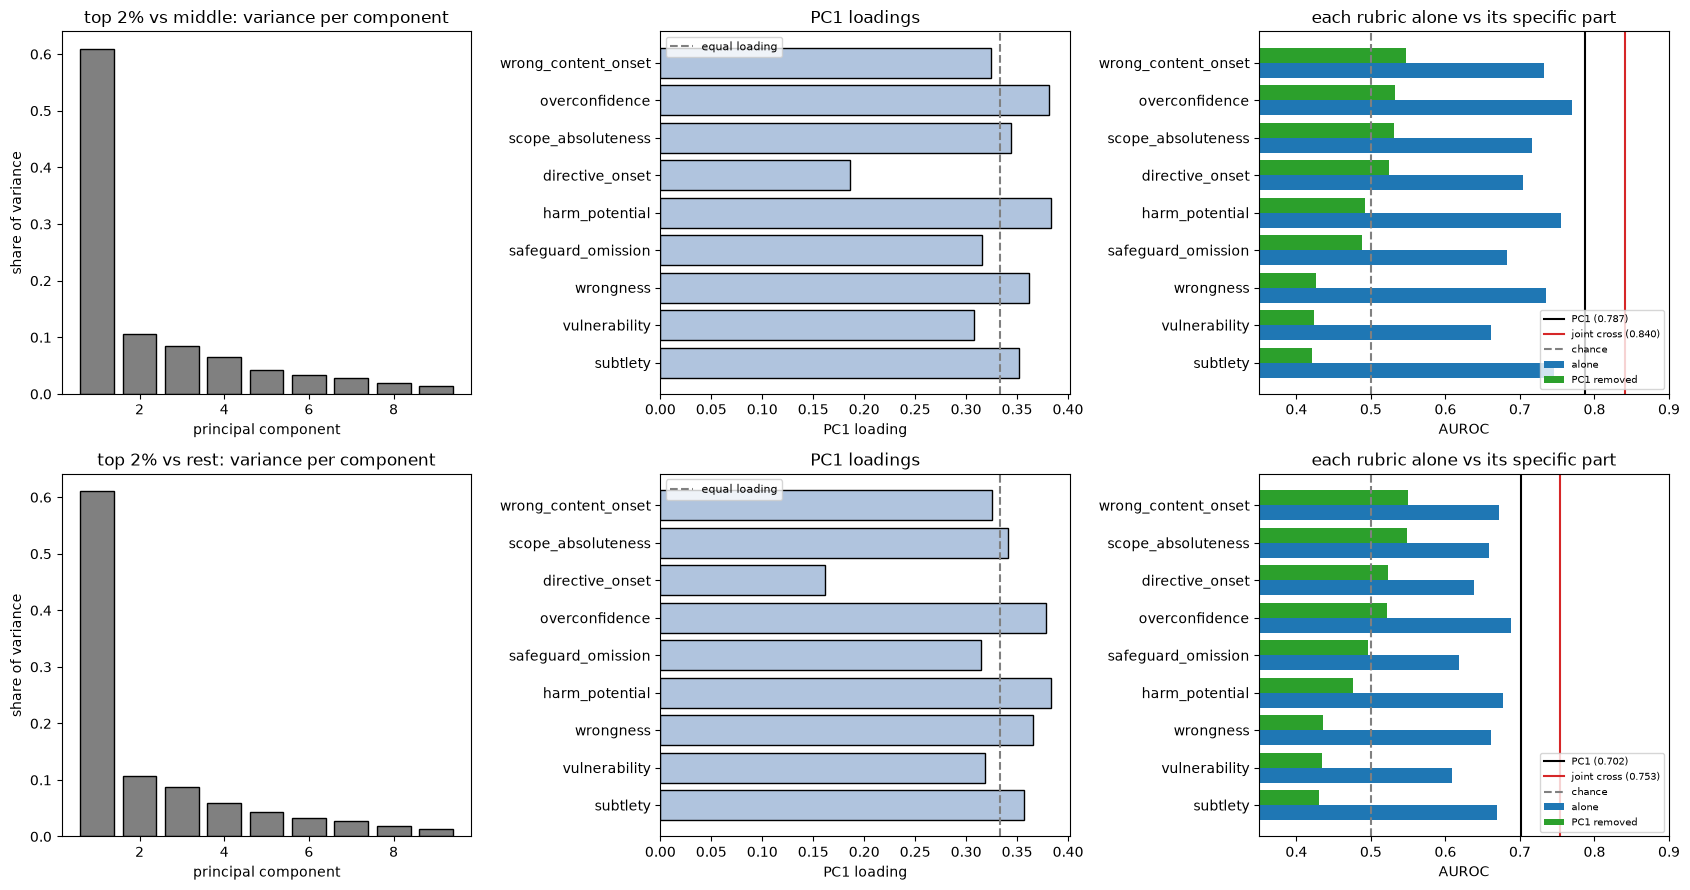

In [28]:
PCA = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    eigval, eigvec = np.linalg.eigh(np.corrcoef(Z.T))
    eigval, eigvec = eigval[::-1], eigvec[:, ::-1]
    loadings = eigvec[:, 0] * np.sign(eigvec[:, 0].sum())  # orient PC1 so high = high rubric scores
    pc1 = Z @ loadings
    pc1 = pc1 / pc1.std()

    rows = []
    for i, metric in enumerate(METRICS):
        r = np.corrcoef(Z[:, i], pc1)[0, 1]
        rows.append({"rubric": metric, "PC1 loading": loadings[i], "corr with PC1": r,
                     "AUROC alone": auroc(Z[:, i], fd["is_pos"]),
                     "AUROC after removing PC1": auroc(Z[:, i] - r * pc1, fd["is_pos"])})
    table = pd.DataFrame(rows).set_index("rubric").sort_values("AUROC after removing PC1")
    best = table["AUROC alone"].idxmax()
    ci = boot_auroc_ci({"PC1": pc1, "mean z": Z.mean(1), f"best single ({best})": Z[:, METRICS.index(best)],
                        "joint cross": PRED_FULL[(contrast, True)]}, fd["is_pos"], fd["doc_rows"])
    PCA[contrast] = {"share": eigval / eigval.sum(), "table": table, "ci": ci}

    print(f"\n=== top {X_FIT}% vs {contrast} ===")
    print("variance share PC1..PC5:", np.round(eigval[:5] / eigval.sum(), 3))
    print(ci.round(3).to_string())
    print()
    print(table.round(3).to_string())

fig, axes = plt.subplots(len(FIT_CONTRASTS), 3, figsize=(17, 4.5 * len(FIT_CONTRASTS)), squeeze=False)
for row, contrast in zip(axes, FIT_CONTRASTS):
    res = PCA[contrast]
    t = res["table"]
    ys = np.arange(len(t))

    row[0].bar(np.arange(1, len(METRICS) + 1), res["share"], color="gray", edgecolor="black")
    row[0].set_xlabel("principal component")
    row[0].set_ylabel("share of variance")
    row[0].set_title(f"top {X_FIT}% vs {contrast}: variance per component")

    row[1].barh(ys, t["PC1 loading"], color="lightsteelblue", edgecolor="black")
    row[1].axvline(1 / np.sqrt(len(METRICS)), color="gray", linestyle="--", label="equal loading")
    row[1].set_yticks(ys, t.index)
    row[1].set_xlabel("PC1 loading")
    row[1].set_title("PC1 loadings")
    row[1].legend(fontsize=8)

    row[2].barh(ys - 0.2, t["AUROC alone"], height=0.4, color="tab:blue", label="alone")
    row[2].barh(ys + 0.2, t["AUROC after removing PC1"], height=0.4, color="tab:green", label="PC1 removed")
    for name, color in [("PC1", "black"), ("joint cross", "tab:red")]:
        row[2].axvline(res["ci"].loc[name, "AUROC"], color=color,
                       label=f"{name} ({res['ci'].loc[name, 'AUROC']:.3f})")
    row[2].axvline(0.5, color="gray", linestyle="--", label="chance")
    row[2].set_xlim(0.35, 0.9)
    row[2].set_yticks(ys, t.index)
    row[2].set_xlabel("AUROC")
    row[2].set_title("each rubric alone vs its specific part")
    row[2].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

#### Is the specific part free of PC1 also beyond linear?

The specific part SP_j = z_j - r_j * PC1 is uncorrelated with PC1 by construction, but it can still depend
on PC1 in a curved way. Least-squares fit of each standardized rubric on a polynomial in PC1:

- **R² linear** = r_j², what the specific-part split removes;
- **R² quadratic / cubic** = with PC1² (and PC1³) added;
- **curved share of SP** = (R² cubic - R² linear) / (1 - R² linear): the part of the specific part that is
  just a curved function of PC1. A large value means that rubric's SP coefficients partly encode "where
  on PC1 the token sits", not only something specific.


top 2% vs middle: each rubric fitted on a polynomial in PC1
                     R2 linear  R2 quadratic  R2 cubic  curved share of SP
rubric                                                                    
wrong_content_onset      0.578         0.578     0.578               0.001
vulnerability            0.519         0.525     0.529               0.020
harm_potential           0.805         0.805     0.815               0.051
directive_onset          0.190         0.221     0.236               0.056
scope_absoluteness       0.651         0.677     0.679               0.081
safeguard_omission       0.547         0.596     0.598               0.113
wrongness                0.719         0.760     0.761               0.150
overconfidence           0.799         0.820     0.833               0.165
subtlety                 0.678         0.797     0.819               0.439

top 2% vs rest: each rubric fitted on a polynomial in PC1
                     R2 linear  R2 quadratic  R2 cubic 

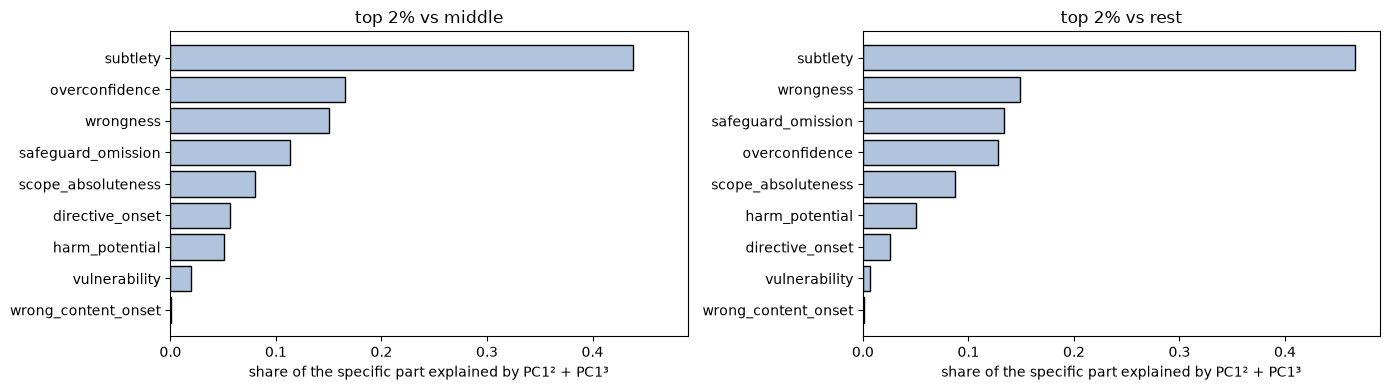

In [29]:
POLY_R2 = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    eigvec = np.linalg.eigh(np.corrcoef(Z.T))[1][:, -1]
    pc1 = Z @ (eigvec * np.sign(eigvec.sum()))
    pc1 = pc1 / pc1.std()

    r2 = {}
    for degree, name in [(1, "R2 linear"), (2, "R2 quadratic"), (3, "R2 cubic")]:
        V = np.vander(pc1, degree + 1)
        resid = Z - V @ np.linalg.lstsq(V, Z, rcond=None)[0]
        r2[name] = 1 - resid.var(0) / Z.var(0)
    table = pd.DataFrame(r2, index=pd.Index(METRICS, name="rubric"))
    table["curved share of SP"] = (table["R2 cubic"] - table["R2 linear"]) / (1 - table["R2 linear"])
    POLY_R2[contrast] = table.sort_values("curved share of SP")
    print(f"\ntop {X_FIT}% vs {contrast}: each rubric fitted on a polynomial in PC1")
    print(POLY_R2[contrast].round(3).to_string())

fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 4), sharex=True, squeeze=False)
for ax, contrast in zip(axes[0], FIT_CONTRASTS):
    t = POLY_R2[contrast]
    ax.barh(t.index, t["curved share of SP"], color="lightsteelblue", edgecolor="black")
    ax.set_xlabel("share of the specific part explained by PC1² + PC1³")
    ax.set_title(f"top {X_FIT}% vs {contrast}")
plt.tight_layout()
plt.show()

#### How much of each rubric is the shared direction?

Each rubric's variance split three ways: **r_j²** (explained linearly by PC1, i.e. shared), the extra part
a curved function of PC1 explains (R² cubic - r_j²), and the rest (unrelated to PC1). r_j² is the share of the
*rubric* that is PC1; the loading² is the share of *PC1* made of that rubric (same order, different scale).

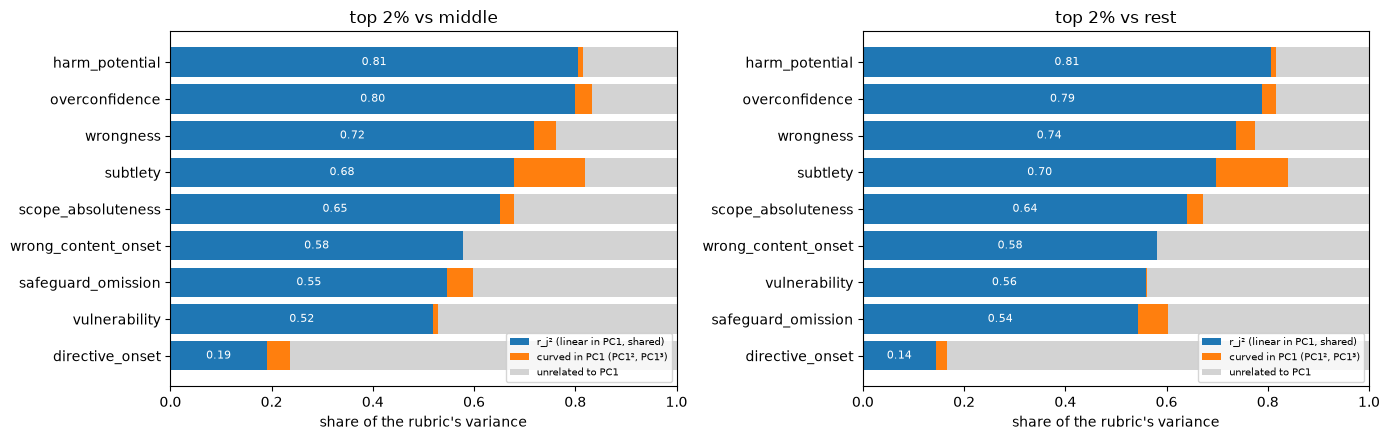

In [30]:
fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 4.5), sharex=True, squeeze=False)
for ax, contrast in zip(axes[0], FIT_CONTRASTS):
    t = POLY_R2[contrast].sort_values("R2 linear")
    curved = t["R2 cubic"] - t["R2 linear"]
    ax.barh(t.index, t["R2 linear"], color="tab:blue", label="r_j² (linear in PC1, shared)")
    ax.barh(t.index, curved, left=t["R2 linear"], color="tab:orange", label="curved in PC1 (PC1², PC1³)")
    ax.barh(t.index, 1 - t["R2 cubic"], left=t["R2 cubic"], color="lightgray", label="unrelated to PC1")
    for y, v in enumerate(t["R2 linear"]):
        ax.text(v / 2, y, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white")
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of the rubric's variance")
    ax.set_title(f"top {X_FIT}% vs {contrast}")
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

### Where does the cross-term gain come from? PC1 / specific-part ladder

Each rubric is split into the common factor and its specific part (SP): z_j = r_j * PC1 + SP_j. Nested
models, each adding one kind of term:

| model | terms | question |
|---|---|---|
| L0 | PC1 | the common factor alone |
| L0 + PC1² | + PC1² | is the common factor's effect curved, without the specific parts? |
| L1 | L0 + SP_j | same span as the main model, so same fit (check) |
| L1 + PC1² | + PC1² | is the common factor's effect curved? |
| M0 | L1 + PC1 x SP_j | gating: does a rubric's specific part count more (or less) when PC1 is high? |
| M1 | M0 + PC1² | curvature on top of gating |
| M2 | M1 + SP_i x SP_j | specific parts interacting with each other |

Every product z_i z_j of the old cross model is a sum of PC1², PC1 x SP and SP x SP terms, so M2 contains
the cross model (M2 >= cross is a check). Standardization and PCA are fitted inside each training fold.
Differences are paired document bootstraps against the main model (no refit, so CIs are somewhat narrow).
pseudo-R² (out-of-fold, see drop-one) also sees curvature that leaves the token order unchanged, which
AUROC cannot (e.g. L0 vs L0 + PC1²).

The SP_j are exactly dependent (sum_j loading_j * SP_j = 0, and the same for the PC1 x SP_j terms), so one
direction of their coefficients is not identified. Predictions are unaffected; the tiny ridge picks the
coefficients orthogonal to the loadings.


=== top 2% vs middle: out-of-fold, d = model - main (main AUROC 0.8253) ===
            AUROC      AP  R-prec  pseudo-R2  log-loss  dAUROC  dAUROC lo  dAUROC hi     dAP  dAP lo  dAP hi  dpseudo-R2  dpseudo-R2 lo  dpseudo-R2 hi
model                                                                                                                                                 
L0         0.7872  0.4548  0.4497     0.1841    0.3290 -0.0381    -0.0433    -0.0327 -0.0580 -0.0695 -0.0467     -0.0544        -0.0621        -0.0467
L0 + PC1²  0.7871  0.4547  0.4494     0.1848    0.3287 -0.0382    -0.0434    -0.0328 -0.0581 -0.0696 -0.0467     -0.0537        -0.0614        -0.0461
L1         0.8253  0.5128  0.4869     0.2385    0.3071  0.0000     0.0000     0.0000  0.0000  0.0000  0.0000      0.0000        -0.0000         0.0000
L1 + PC1²  0.8254  0.5128  0.4866     0.2384    0.3071  0.0001    -0.0001     0.0002  0.0000 -0.0003  0.0005     -0.0001        -0.0003         0.0001
M0         0.8327


=== top 2% vs rest: out-of-fold, d = model - main (main AUROC 0.7337) ===
            AUROC      AP  R-prec  pseudo-R2  log-loss  dAUROC  dAUROC lo  dAUROC hi     dAP  dAP lo  dAP hi  dpseudo-R2  dpseudo-R2 lo  dpseudo-R2 hi
model                                                                                                                                                 
L0         0.7017  0.0872  0.1400     0.0626    0.1317 -0.0320    -0.0380    -0.0259 -0.0184 -0.0235 -0.0135     -0.0233        -0.0271        -0.0191
L0 + PC1²  0.7015  0.0869  0.1406     0.0633    0.1316 -0.0323    -0.0383    -0.0262 -0.0187 -0.0239 -0.0135     -0.0226        -0.0260        -0.0186
L1         0.7337  0.1056  0.1670     0.0859    0.1285  0.0000     0.0000     0.0000  0.0000  0.0000  0.0000      0.0000        -0.0000         0.0000
L1 + PC1²  0.7335  0.1055  0.1664     0.0857    0.1285 -0.0002    -0.0004     0.0000 -0.0001 -0.0006  0.0002     -0.0002        -0.0003        -0.0000
M0         0.7447  

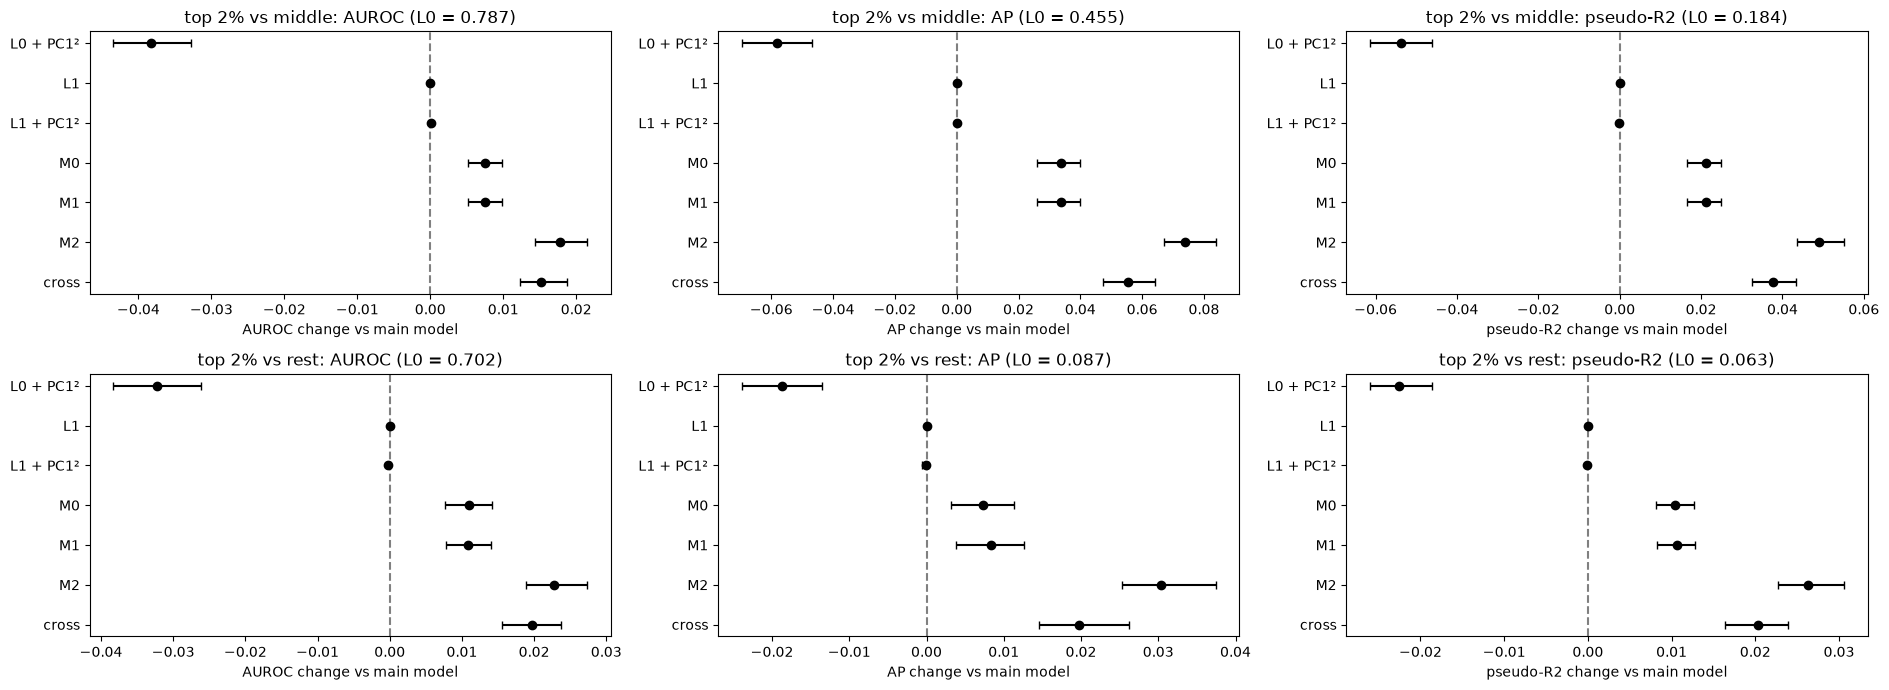

In [31]:
LADDER = {"L0": set(), "L0 + PC1²": {"pc1sq"}, "L1": {"sp"}, "L1 + PC1²": {"sp", "pc1sq"}, "M0": {"sp", "gate"},
          "M1": {"sp", "gate", "pc1sq"}, "M2": {"sp", "gate", "pc1sq", "spsp"}}


def pc_split(Z_fit):
    """PC1 loadings (oriented so high = high rubric scores) and PC1's SD, from standardized scores."""
    eigvec = np.linalg.eigh(np.corrcoef(Z_fit.T))[1][:, -1]
    loadings = eigvec * np.sign(eigvec.sum())
    return loadings, (Z_fit @ loadings).std()


def pc_design(Z, loadings, pc1_sd, terms):
    pc1 = Z @ loadings / pc1_sd
    sp = Z - pc1[:, None] * (loadings * pc1_sd)  # loadings * pc1_sd = corr of each rubric with PC1
    cols = [np.ones(len(Z)), pc1]
    if "sp" in terms:
        cols += list(sp.T)
    if "gate" in terms:
        cols += [pc1 * sp[:, j] for j in range(sp.shape[1])]
    if "pc1sq" in terms:
        cols.append(pc1**2)
    if "spsp" in terms:
        cols += [sp[:, i] * sp[:, j] for i, j in combinations(range(sp.shape[1]), 2)]
    return np.column_stack(cols)


def oof_predict_pc(fd, terms):
    S = fd["sub"][SCORE_COLS].to_numpy()
    y = fd["is_pos"].astype(float)
    pred = np.empty(len(S))
    for k in range(N_FOLDS):
        tr, te = fd["fold"] != k, fd["fold"] == k
        Ztr, Zte = standardize(S[tr], S[te])
        loadings, pc1_sd = pc_split(Ztr)
        beta = fit_logit(pc_design(Ztr, loadings, pc1_sd, terms), y[tr])
        pred[te] = pc_design(Zte, loadings, pc1_sd, terms) @ beta
    return pred


def log_loss(logit, is_pos):
    return np.mean(np.logaddexp(0, logit) - is_pos * logit)


LADDER_PRED, LADDER_TABLES = {}, {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    preds = {name: oof_predict_pc(fd, terms) for name, terms in LADDER.items()}
    preds["cross"] = PRED_FULL[(contrast, True)]
    LADDER_PRED[contrast] = preds
    main = PRED_FULL[(contrast, False)]
    rows = []
    for name, pred in preds.items():
        delta = paired_boot_delta(main, pred, fd["is_pos"], fd["doc_rows"])
        row = {"model": name, **fit_metrics(pred, fd["is_pos"], logit=True), "log-loss": log_loss(pred, fd["is_pos"])}
        for k in ["AUROC", "AP", "pseudo-R2"]:
            row |= {f"d{k}": delta[k][0], f"d{k} lo": delta[k][1], f"d{k} hi": delta[k][2]}
        rows.append(row)
    LADDER_TABLES[contrast] = pd.DataFrame(rows).set_index("model")
    print(f"\n=== top {X_FIT}% vs {contrast}: out-of-fold, d = model - main (main AUROC {auroc(main, fd['is_pos']):.4f}) ===")
    print(LADDER_TABLES[contrast].round(4).to_string())

fig, axes = plt.subplots(len(FIT_CONTRASTS), 3, figsize=(19, 3.5 * len(FIT_CONTRASTS)), squeeze=False)
for row, contrast in zip(axes, FIT_CONTRASTS):
    t = LADDER_TABLES[contrast].drop("L0")  # L0 is far below main; shown in the table
    ys = np.arange(len(t))[::-1]
    for ax, k in zip(row, ["AUROC", "AP", "pseudo-R2"]):
        ax.errorbar(t[f"d{k}"], ys, xerr=[t[f"d{k}"] - t[f"d{k} lo"], t[f"d{k} hi"] - t[f"d{k}"]],
                    fmt="o", color="black", capsize=3)
        ax.axvline(0, color="gray", linestyle="--")
        ax.set_yticks(ys, t.index)
        ax.set_xlabel(f"{k} change vs main model")
        ax.set_title(f"top {X_FIT}% vs {contrast}: {k} (L0 = {LADDER_TABLES[contrast].loc['L0', k]:.3f})")
plt.tight_layout()
plt.show()

#### AUROC and pseudo-R² along the ladder

Each model's out-of-fold AUROC (top row) and pseudo-R² (bottom row) with a document-bootstrap 95% CI.
The line follows the nested chain L0 -> L1 -> M0 -> M1 -> M2; the PC1² side branches are grey points, the
old cross model a dashed line. pseudo-R² also sees steps that leave the token order unchanged (L0 -> L0 + PC1²)
and is comparable across contrasts. Absolute CIs overlap more than the differences do: for whether a step is
real, use the paired deltas above.

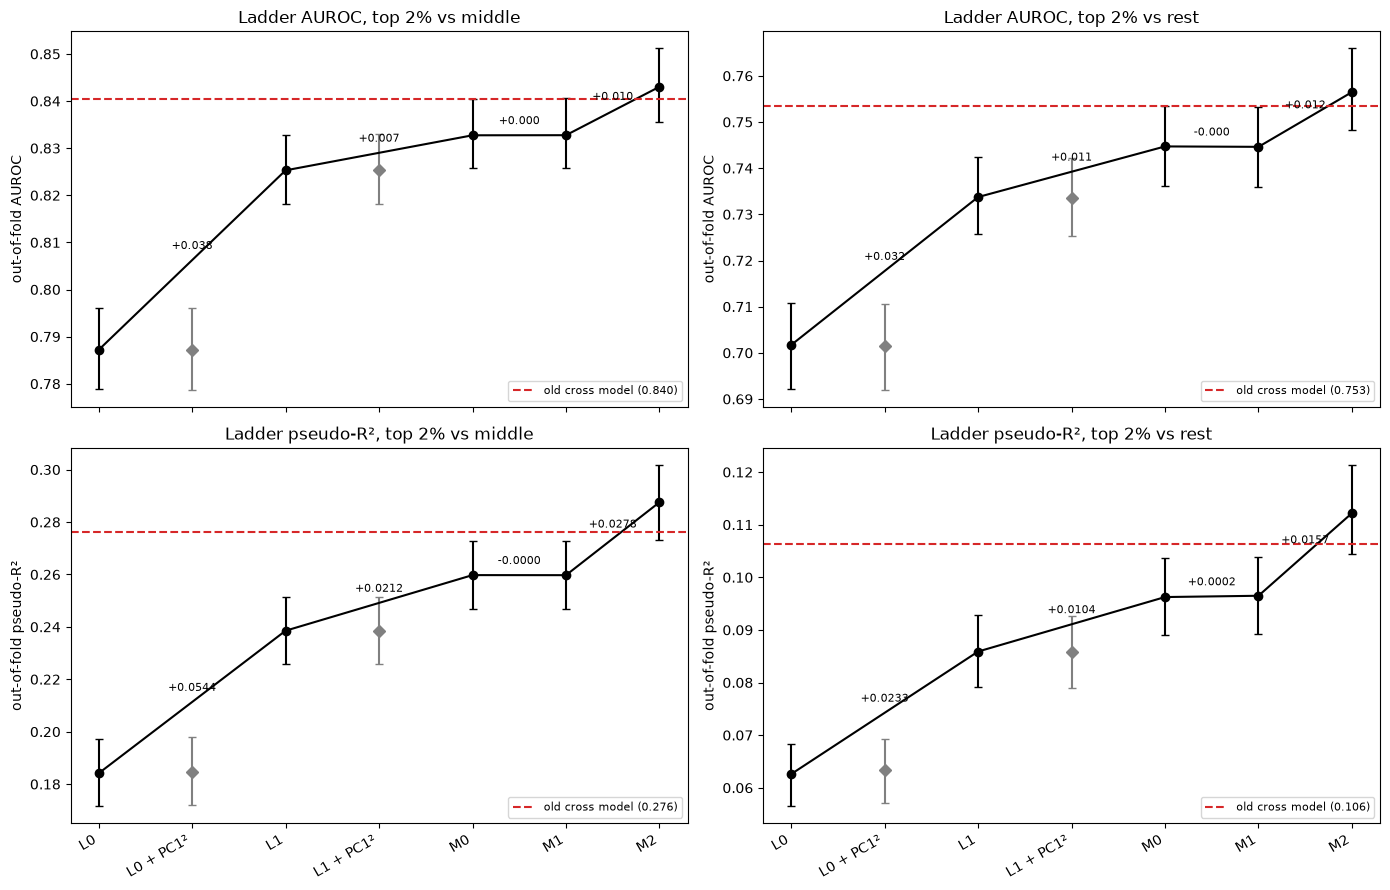

In [32]:
def boot_metric_ci(preds, is_pos, doc_rows, metric, n_boot=N_BOOT_FIT, seed=0):
    """Like boot_auroc_ci, for any metric(pred, is_pos)."""
    rng_b = np.random.default_rng(seed)
    point = {k: metric(v, is_pos) for k, v in preds.items()}
    boots = []
    for _ in range(n_boot):
        r = np.concatenate([doc_rows[i] for i in rng_b.integers(0, len(doc_rows), len(doc_rows))])
        boots.append({k: metric(v[r], is_pos[r]) for k, v in preds.items()})
    boots = pd.DataFrame(boots)
    return pd.DataFrame({"value": point, "lo": boots.quantile(0.025), "hi": boots.quantile(0.975)})


CHAIN = ["L0", "L1", "M0", "M1", "M2"]
ORDER = ["L0", "L0 + PC1²", "L1", "L1 + PC1²", "M0", "M1", "M2"]
xs = {name: i for i, name in enumerate(ORDER)}

fig, axes = plt.subplots(2, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 9), squeeze=False)
for col, contrast in enumerate(FIT_CONTRASTS):
    fd = FIT_DATA[contrast]
    for row, (label, metric, fmt) in enumerate([("AUROC", auroc, "{:+.3f}"), ("pseudo-R²", pseudo_r2, "{:+.4f}")]):
        ax = axes[row, col]
        ci = boot_metric_ci(LADDER_PRED[contrast], fd["is_pos"], fd["doc_rows"], metric)
        for name in ORDER:
            on_chain = name in CHAIN
            ax.errorbar(xs[name], ci.loc[name, "value"],
                        yerr=[[ci.loc[name, "value"] - ci.loc[name, "lo"]], [ci.loc[name, "hi"] - ci.loc[name, "value"]]],
                        fmt="o" if on_chain else "D", color="black" if on_chain else "gray", capsize=3)
        ax.plot([xs[n] for n in CHAIN], ci.loc[CHAIN, "value"], color="black")
        for prev, name in zip(CHAIN[:-1], CHAIN[1:]):
            gain = ci.loc[name, "value"] - ci.loc[prev, "value"]
            ax.annotate(fmt.format(gain), ((xs[prev] + xs[name]) / 2, (ci.loc[prev, "value"] + ci.loc[name, "value"]) / 2),
                        textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
        ax.axhline(ci.loc["cross", "value"], color="tab:red", linestyle="--",
                   label=f"old cross model ({ci.loc['cross', 'value']:.3f})")
        ax.set_xticks(range(len(ORDER)), ORDER if row == 1 else [""] * len(ORDER), rotation=30, ha="right")
        ax.set_ylabel(f"out-of-fold {label}")
        ax.set_title(f"Ladder {label}, top {X_FIT}% vs {contrast}")
        ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

#### Gating coefficients (M0)

Full-data fit of M0 (one standardization and PCA on all tokens), plus one fit per training fold on the
same features for the min/max range. Shown as contribution spread = beta x SD of the term, as in the
cross-term heatmap below.

- **PC1 x SP_j > 0**: rubric j's specific part counts more among tokens the judge rates high on everything.
- **PC1 x SP_j < 0**: it counts less there (or matters mainly among generally low-rated tokens).

Only differences between rubrics are identified (see the dependency note above).


=== top 2% vs middle: M0, PC1 spread +1.041 ===
                     SP spread  gate beta  gate spread  gate spread fold min  gate spread fold max
rubric                                                                                            
directive_onset          0.550     -0.214       -0.272                -0.295                -0.251
wrongness               -0.024     -0.434       -0.226                -0.254                -0.216
overconfidence           0.161     -0.142       -0.064                -0.078                -0.049
vulnerability           -0.319     -0.022       -0.012                -0.042                 0.003
harm_potential           0.074     -0.025       -0.010                -0.031                 0.026
wrong_content_onset      0.078      0.108        0.064                 0.056                 0.073
subtlety                 0.087      0.118        0.071                 0.044                 0.085
safeguard_omission      -0.195      0.109        0.087      


=== top 2% vs rest: M0, PC1 spread +0.576 ===
                     SP spread  gate beta  gate spread  gate spread fold min  gate spread fold max
rubric                                                                                            
directive_onset          0.336     -0.163       -0.177                -0.193                -0.170
wrongness               -0.015     -0.280       -0.128                -0.141                -0.118
overconfidence           0.108     -0.096       -0.039                -0.053                -0.031
subtlety                 0.020     -0.037       -0.020                -0.047                -0.004
harm_potential           0.020      0.024        0.008                 0.001                 0.030
vulnerability           -0.236      0.031        0.016                -0.001                 0.027
safeguard_omission      -0.145      0.036        0.026                 0.013                 0.039
wrong_content_onset      0.115      0.136        0.072        

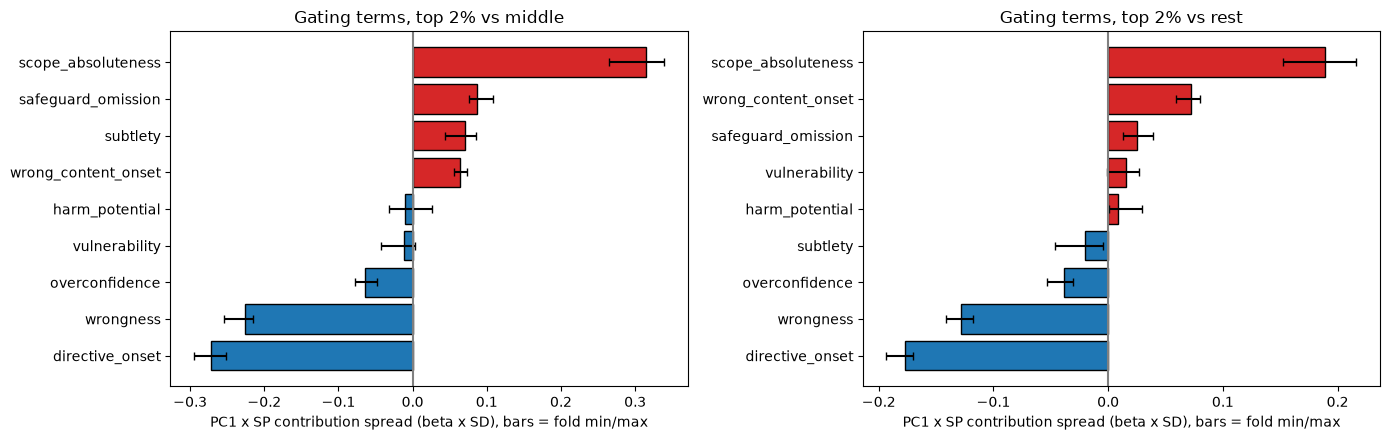

In [33]:
GATING = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    X = pc_design(Z, *pc_split(Z), LADDER["M0"])
    y = fd["is_pos"].astype(float)
    beta = fit_logit(X, y)
    fold_betas = np.array([fit_logit(X[fd["fold"] != k], y[fd["fold"] != k]) for k in range(N_FOLDS)])
    n = len(METRICS)
    sp_cols, gate_cols = np.arange(2, 2 + n), np.arange(2 + n, 2 + 2 * n)
    sd = X.std(0)
    GATING[contrast] = pd.DataFrame({
        "SP spread": beta[sp_cols] * sd[sp_cols],
        "gate beta": beta[gate_cols],
        "gate spread": beta[gate_cols] * sd[gate_cols],
        "gate spread fold min": fold_betas[:, gate_cols].min(0) * sd[gate_cols],
        "gate spread fold max": fold_betas[:, gate_cols].max(0) * sd[gate_cols],
    }, index=pd.Index(METRICS, name="rubric")).sort_values("gate spread")
    print(f"\n=== top {X_FIT}% vs {contrast}: M0, PC1 spread {beta[1] * sd[1]:+.3f} ===")
    print(GATING[contrast].round(3).to_string())

fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 4.5), squeeze=False)
for ax, contrast in zip(axes[0], FIT_CONTRASTS):
    t = GATING[contrast]
    ys = np.arange(len(t))
    ax.barh(ys, t["gate spread"], color=np.where(t["gate spread"] > 0, "tab:red", "tab:blue"), edgecolor="black",
            xerr=[t["gate spread"] - t["gate spread fold min"], t["gate spread fold max"] - t["gate spread"]],
            capsize=3)
    ax.axvline(0, color="gray")
    ax.set_yticks(ys, t.index)
    ax.set_xlabel("PC1 x SP contribution spread (beta x SD), bars = fold min/max")
    ax.set_title(f"Gating terms, top {X_FIT}% vs {contrast}")
plt.tight_layout()
plt.show()

#### All M2 coefficients: specific x specific products

Full-data fit of M2, shown as contribution spread (beta x SD of the term). Lower triangle = SP_i x SP_j,
diagonal = PC1 x SP_j gating within M2. `*` = same sign in all fold fits. The 36 products are small and
correlated with each other, so read the pattern (which rubrics take part), not single cells.

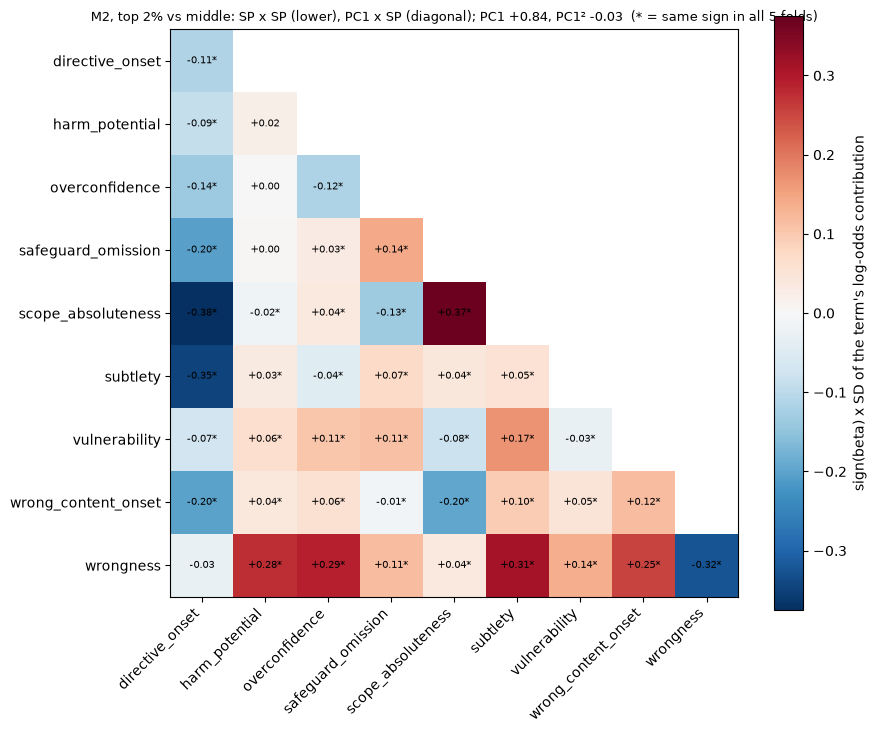

top 2% vs middle: 10 largest SP x SP terms by |spread|
                                          spread  fold min  fold max
term                                                                
directive_onset x scope_absoluteness      -0.375    -0.396    -0.364
directive_onset x subtlety                -0.347    -0.379    -0.321
subtlety x wrongness                       0.312     0.266     0.396
overconfidence x wrongness                 0.292     0.260     0.336
harm_potential x wrongness                 0.278     0.254     0.329
wrong_content_onset x wrongness            0.255     0.203     0.303
directive_onset x safeguard_omission      -0.203    -0.217    -0.183
directive_onset x wrong_content_onset     -0.202    -0.225    -0.183
scope_absoluteness x wrong_content_onset  -0.195    -0.221    -0.157
subtlety x vulnerability                   0.169     0.154     0.194


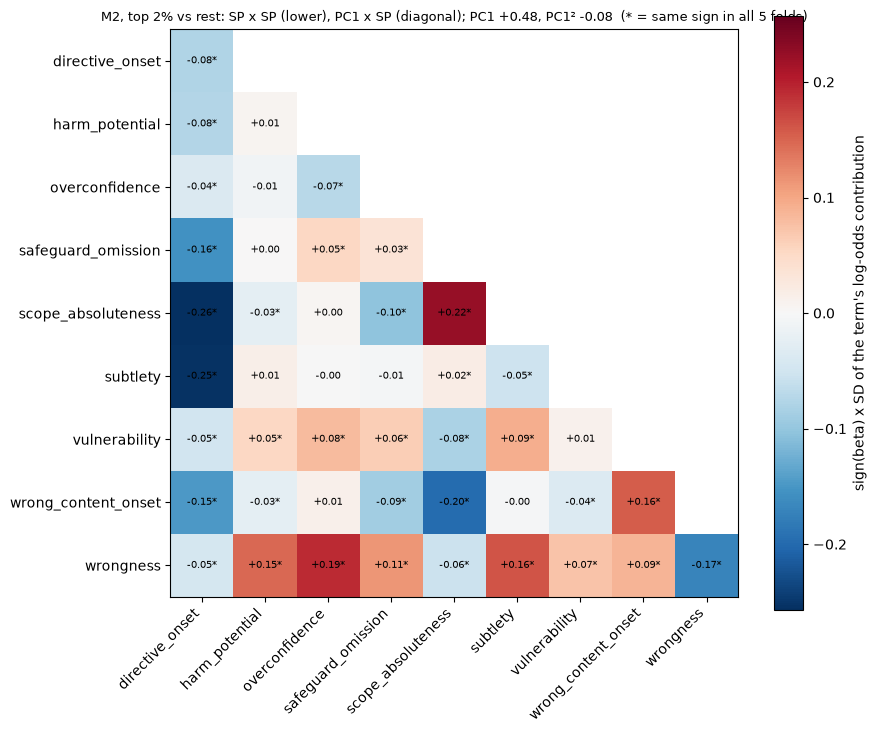

top 2% vs rest: 10 largest SP x SP terms by |spread|
                                          spread  fold min  fold max
term                                                                
directive_onset x scope_absoluteness      -0.257    -0.266    -0.247
directive_onset x subtlety                -0.253    -0.267    -0.246
scope_absoluteness x wrong_content_onset  -0.198    -0.217    -0.173
overconfidence x wrongness                 0.191     0.170     0.222
subtlety x wrongness                       0.161     0.130     0.212
directive_onset x safeguard_omission      -0.155    -0.170    -0.132
harm_potential x wrongness                 0.149     0.136     0.165
directive_onset x wrong_content_onset     -0.148    -0.165    -0.134
safeguard_omission x wrongness             0.114     0.087     0.146
safeguard_omission x scope_absoluteness   -0.104    -0.119    -0.094


In [34]:
M2_FIT = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    X = pc_design(Z, *pc_split(Z), LADDER["M2"])
    y = fd["is_pos"].astype(float)
    beta = fit_logit(X, y)
    fold_betas = np.array([fit_logit(X[fd["fold"] != k], y[fd["fold"] != k]) for k in range(N_FOLDS)])
    M2_FIT[contrast] = (X, beta, fold_betas)

    n = len(METRICS)
    # column layout of pc_design: 1, PC1, SP (n), PC1 x SP (n), PC1², SP_i x SP_j (pairs)
    gate_col = {j: 2 + n + j for j in range(n)}
    pair_col = {pair: 3 + 2 * n + t for t, pair in enumerate(combinations(range(n), 2))}
    spread = beta * X.std(0)
    agree = (np.sign(fold_betas) == np.sign(beta)).all(0)

    M = np.full((n, n), np.nan)
    cells = {(j, j): gate_col[j] for j in range(n)} | {(j, i): col for (i, j), col in pair_col.items()}
    for (r, c), col in cells.items():
        M[r, c] = spread[col]
    lim = np.nanmax(np.abs(M))
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
    for (r, c), col in cells.items():
        ax.text(c, r, f"{M[r, c]:+.2f}" + ("*" if agree[col] else ""), ha="center", va="center", fontsize=7)
    ax.set_xticks(range(n), METRICS, rotation=45, ha="right")
    ax.set_yticks(range(n), METRICS)
    fig.colorbar(im, label="sign(beta) x SD of the term's log-odds contribution")
    ax.set_title(f"M2, top {X_FIT}% vs {contrast}: SP x SP (lower), PC1 x SP (diagonal); "
                 f"PC1 {spread[1]:+.2f}, PC1² {spread[2 + 2 * n]:+.2f}  (* = same sign in all {N_FOLDS} folds)",
                 fontsize=9)
    plt.tight_layout()
    plt.show()

    rows = [{"term": f"{METRICS[i]} x {METRICS[j]}", "spread": spread[col],
             "fold min": fold_betas[:, col].min() * X[:, col].std(), "fold max": fold_betas[:, col].max() * X[:, col].std()}
            for (i, j), col in pair_col.items()]
    table = pd.DataFrame(rows).set_index("term")
    print(f"top {X_FIT}% vs {contrast}: 10 largest SP x SP terms by |spread|")
    print(table.loc[table["spread"].abs().sort_values(ascending=False).index[:10]].round(3).to_string())

### Cross-term model: which terms move the log-odds, and are they stable?

Full-data fit of the cross-term model, for interpretation only. Every term adds to the same log-odds,
but the product of two standardized rubrics doesn't have SD 1 (skewed rubrics give heavy-tailed
products), so raw coefficients aren't comparable between main and cross terms. Each cell therefore
shows the term's **contribution spread**: SD over tokens of beta x term, signed by beta. Diagonal =
main effects (= beta, since z has SD 1), lower triangle = pairwise products.

Main effects here are the slope with every other rubric at its mean, so they depend on the centring.
`*` = all 5 training-fold fits give the coefficient the same sign as the full fit.

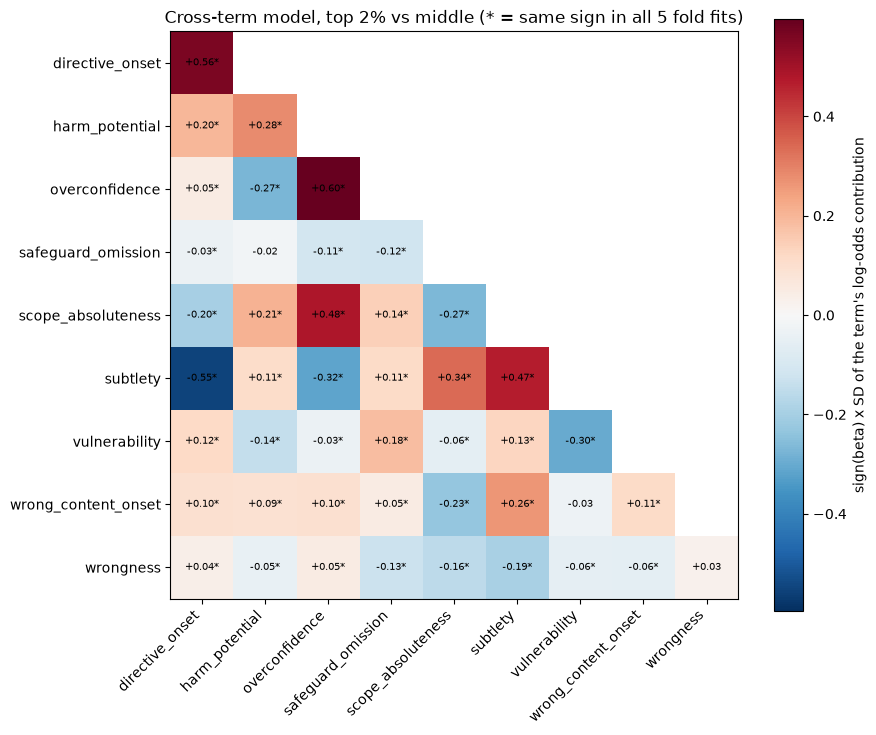

top 2% vs middle, terms by |contribution spread|
                                           beta  term SD  contribution spread  folds same sign (/5)
overconfidence                            0.596    1.000                0.596                     5
directive_onset                           0.562    1.000                0.562                     5
directive_onset x subtlety               -0.512    1.075               -0.551                     5
overconfidence x scope_absoluteness       0.297    1.629                0.483                     5
subtlety                                  0.470    1.000                0.470                     5
scope_absoluteness x subtlety             0.343    0.987                0.339                     5
overconfidence x subtlety                -0.323    0.976               -0.315                     5
vulnerability                            -0.300    1.000               -0.300                     5
harm_potential                            0.283    

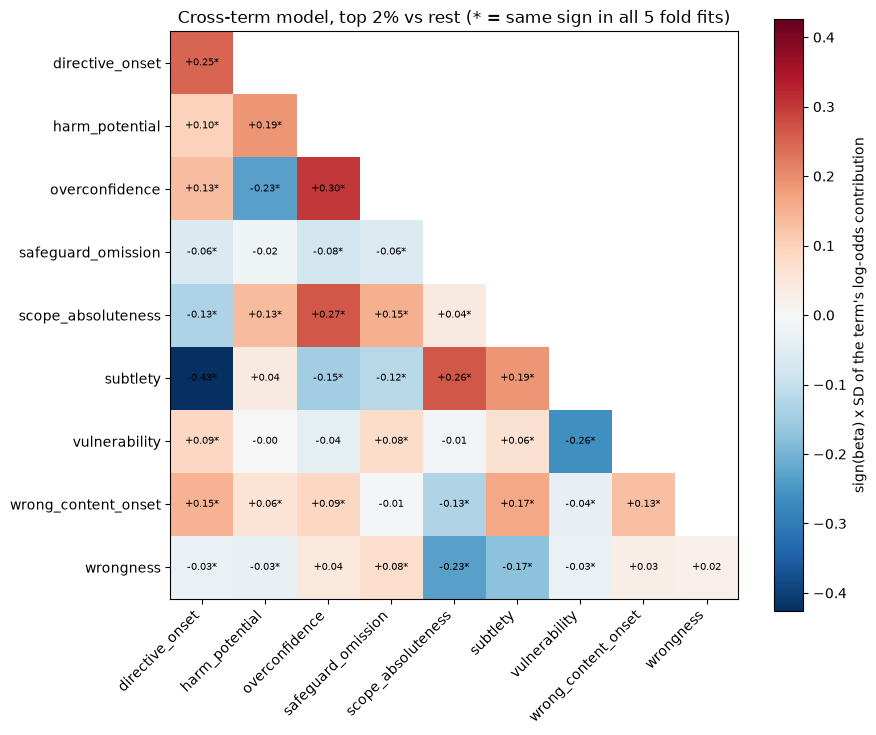

top 2% vs rest, terms by |contribution spread|
                                           beta  term SD  contribution spread  folds same sign (/5)
directive_onset x subtlety               -0.413    1.031               -0.426                     5
overconfidence                            0.300    1.000                0.300                     5
overconfidence x scope_absoluteness       0.198    1.338                0.265                     5
scope_absoluteness x subtlety             0.295    0.896                0.264                     5
vulnerability                            -0.262    1.000               -0.262                     5
directive_onset                           0.248    1.000                0.248                     5
harm_potential x overconfidence          -0.217    1.069               -0.232                     5
scope_absoluteness x wrongness           -0.229    1.003               -0.230                     5
harm_potential                            0.190    1.

In [35]:
PAIRS = list(combinations(range(len(METRICS)), 2))


def fit_interp(fd, cross):
    """Full-data fit plus one fit per training fold, all on the full-data standardization so their
    coefficients are directly comparable."""
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    X = design(Z, cross)
    y = fd["is_pos"].astype(float)
    fold_betas = np.array([fit_logit(X[fd["fold"] != k], y[fd["fold"] != k]) for k in range(N_FOLDS)])
    return Z, X, fit_logit(X, y), fold_betas


INTERP = {(c, cross): fit_interp(FIT_DATA[c], cross) for c in FIT_CONTRASTS for cross in [False, True]}

n = len(METRICS)
term_names = ["intercept", *METRICS, *[f"{METRICS[i]} x {METRICS[j]}" for i, j in PAIRS]]
# Design column of each heatmap cell: mains on the diagonal, products in the lower triangle.
cell_col = {(i, i): 1 + i for i in range(n)} | {(j, i): 1 + n + t for t, (i, j) in enumerate(PAIRS)}

for contrast in FIT_CONTRASTS:
    Z, X, beta, fold_betas = INTERP[(contrast, True)]
    spread = beta * X.std(0)
    agree = (np.sign(fold_betas) == np.sign(beta)).sum(0)

    M = np.full((n, n), np.nan)
    for (r, c), col in cell_col.items():
        M[r, c] = spread[col]
    lim = np.nanmax(np.abs(M))
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
    for (r, c), col in cell_col.items():
        ax.text(c, r, f"{M[r, c]:+.2f}" + ("*" if agree[col] == N_FOLDS else ""),
                ha="center", va="center", fontsize=7)
    ax.set_xticks(range(n), METRICS, rotation=45, ha="right")
    ax.set_yticks(range(n), METRICS)
    fig.colorbar(im, label="sign(beta) x SD of the term's log-odds contribution")
    ax.set_title(f"Cross-term model, top {X_FIT}% vs {contrast} (* = same sign in all {N_FOLDS} fold fits)")
    plt.tight_layout()
    plt.show()

    table = pd.DataFrame({"beta": beta, "term SD": X.std(0), "contribution spread": spread,
                          f"folds same sign (/{N_FOLDS})": agree}, index=term_names).drop("intercept")
    print(f"top {X_FIT}% vs {contrast}, terms by |contribution spread|")
    print(table.reindex(table["contribution spread"].abs().sort_values(ascending=False).index)
          .round(3).to_string())

### Average marginal effect (AME) per rubric

p = sigmoid(eta), so by the chain rule the probability slope of rubric j at one token is

dp/dz_j = p(1-p) * (beta_j + sum_k beta_jk z_k)

p(1-p) is the steepness of the sigmoid at that token (max 0.25 at p = 0.5, ~0 for tokens the model is
sure about); the bracket is rubric j's log-odds slope, which in the cross model depends on the token's
other rubric values. AME_j = mean of that over all tokens, in **probability per 1 SD** of the rubric,
and comparable between main and cross models. It scales with the base rate, so compare rubrics within
a contrast (or use AME / base rate). Error bars: min-max over the 5 training-fold fits (fitting noise).
The histograms show the per-token slopes: a rubric with a small average but a long tail matters a lot
for a few tokens.


=== top 2% vs middle, cross model (probability per SD) ===
                        AME  fold min  fold max  AME / base rate  slope p1  slope p99
rubric                                                                               
vulnerability       -0.0245   -0.0259   -0.0218          -0.1765   -0.1317     0.0134
wrongness           -0.0223   -0.0244   -0.0207          -0.1605   -0.2430     0.0871
safeguard_omission  -0.0049   -0.0069   -0.0028          -0.0355   -0.0747     0.0601
scope_absoluteness  -0.0006   -0.0038    0.0042          -0.0045   -0.1703     0.2016
wrong_content_onset  0.0232    0.0219    0.0246           0.1671   -0.0123     0.1599
harm_potential       0.0284    0.0256    0.0324           0.2044   -0.0177     0.1715
directive_onset      0.0322    0.0309    0.0337           0.2318   -0.0250     0.1694
subtlety             0.0366    0.0318    0.0404           0.2631   -0.2619     0.3616
overconfidence       0.0403    0.0393    0.0430           0.2898   -0.0288     0

/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/1741450441.py:34: PerformanceWarning: indexing past lexsort depth may impact performance.
  order = ame_table.loc[(contrast, "cross")].sort_values("AME").index
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/1741450441.py:37: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = ame_table.loc[(contrast, model)].loc[order]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/1741450441.py:37: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = ame_table.loc[(contrast, model)].loc[order]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/1741450441.py:34: PerformanceWarning: indexing past lexsort depth may impact performance.
  order = ame_table.loc[(contrast, "cross")].sort_values("AME").index
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_16821/1741450441.py:37: PerformanceWarning: indexing past lexsort depth may impac

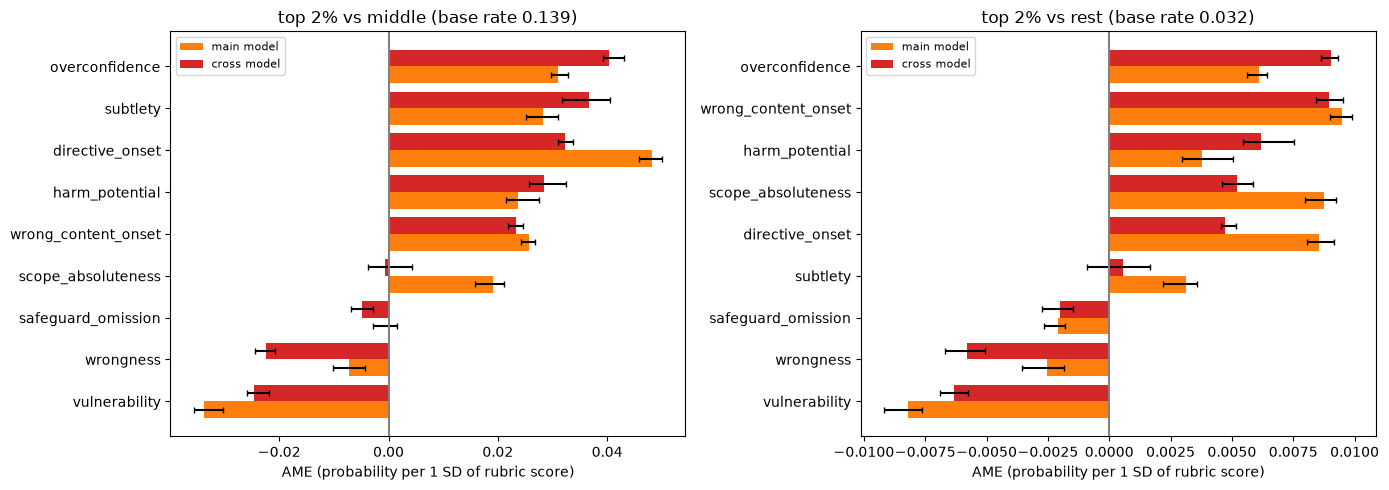

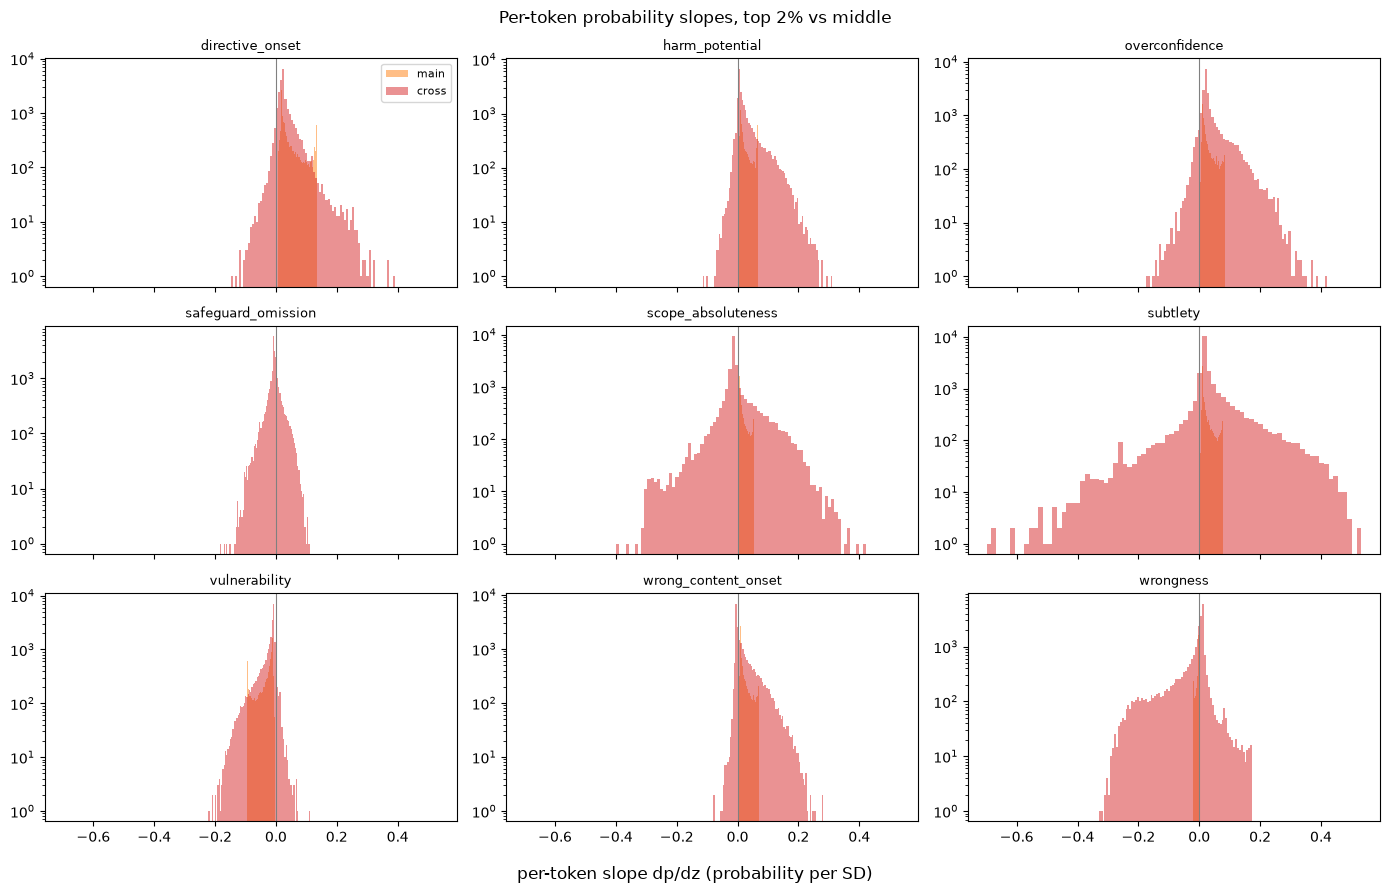

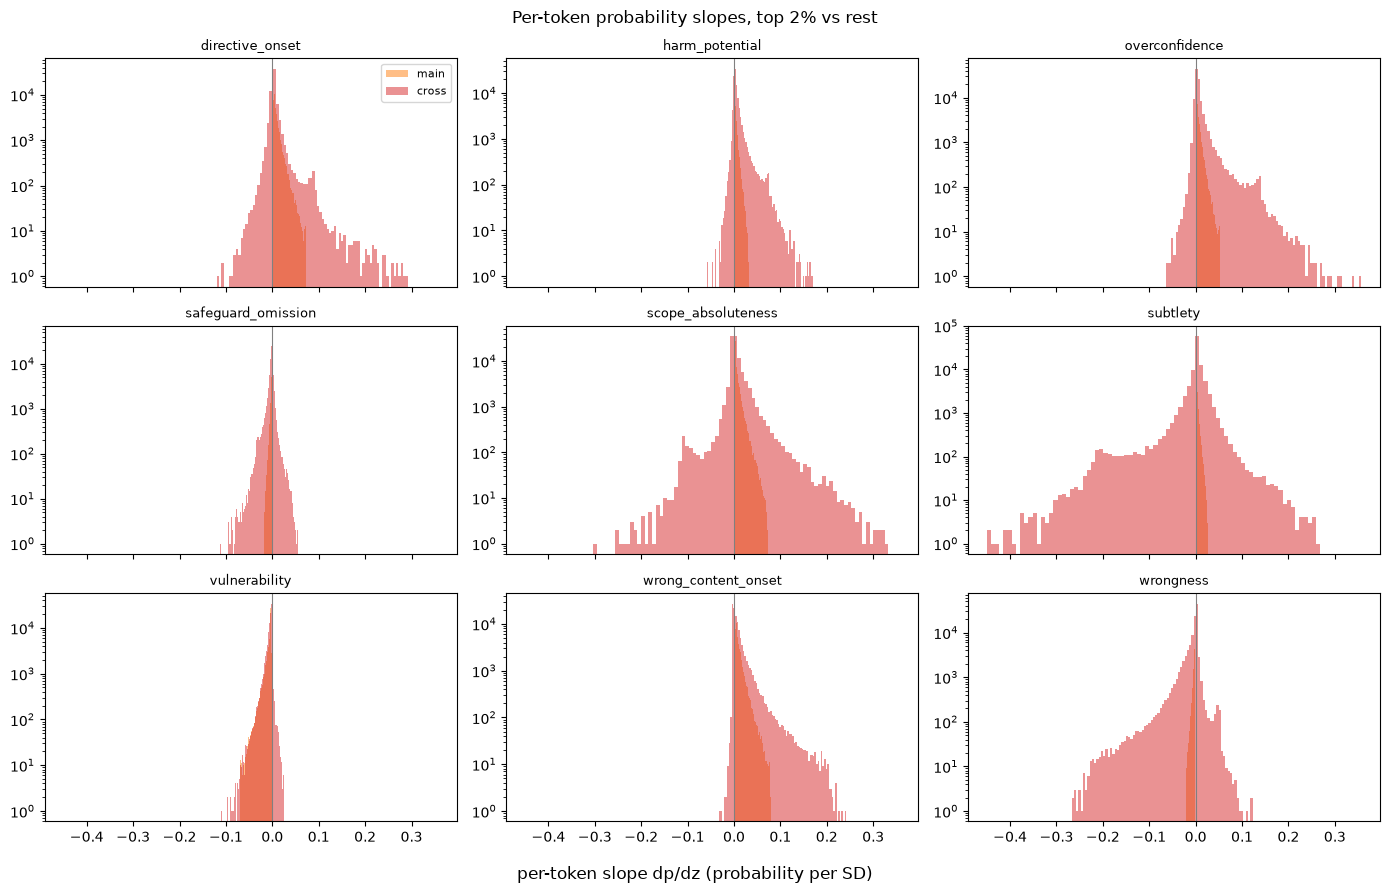

In [36]:
def per_token_slopes(Z, beta, cross):
    """dp/dz_j for every token (rows) and rubric (columns)."""
    p = 1 / (1 + np.exp(-np.clip(design(Z, cross) @ beta, -30, 30)))
    dlogit = np.tile(beta[1:1 + Z.shape[1]], (len(Z), 1))
    if cross:
        for t, (i, j) in enumerate(PAIRS):
            dlogit[:, i] += beta[1 + Z.shape[1] + t] * Z[:, j]
            dlogit[:, j] += beta[1 + Z.shape[1] + t] * Z[:, i]
    return (p * (1 - p))[:, None] * dlogit


SLOPES = {}
ame_rows = []
for contrast in FIT_CONTRASTS:
    base = FIT_DATA[contrast]["is_pos"].mean()
    for cross in [False, True]:
        Z, X, beta, fold_betas = INTERP[(contrast, cross)]
        slopes = per_token_slopes(Z, beta, cross)
        SLOPES[(contrast, cross)] = slopes
        fold_ame = np.array([per_token_slopes(Z, b, cross).mean(0) for b in fold_betas])
        for i, metric in enumerate(METRICS):
            ame_rows.append({"contrast": contrast, "model": "cross" if cross else "main", "rubric": metric,
                             "AME": slopes[:, i].mean(), "fold min": fold_ame[:, i].min(),
                             "fold max": fold_ame[:, i].max(), "AME / base rate": slopes[:, i].mean() / base,
                             "slope p1": np.percentile(slopes[:, i], 1),
                             "slope p99": np.percentile(slopes[:, i], 99)})
ame_table = pd.DataFrame(ame_rows).set_index(["contrast", "model", "rubric"])
for (contrast, model), t in ame_table.groupby(level=["contrast", "model"]):
    print(f"\n=== top {X_FIT}% vs {contrast}, {model} model (probability per SD) ===")
    print(t.droplevel([0, 1]).sort_values("AME").round(4).to_string())

fig, axes = plt.subplots(1, len(FIT_CONTRASTS), figsize=(7 * len(FIT_CONTRASTS), 5), squeeze=False)
for ax, contrast in zip(axes[0], FIT_CONTRASTS):
    order = ame_table.loc[(contrast, "cross")].sort_values("AME").index
    ys = np.arange(len(order))
    for off, model, color in [(-0.2, "main", "tab:orange"), (0.2, "cross", "tab:red")]:
        t = ame_table.loc[(contrast, model)].loc[order]
        ax.barh(ys + off, t["AME"], height=0.4, color=color, label=f"{model} model",
                xerr=[(t["AME"] - t["fold min"]).clip(lower=0), (t["fold max"] - t["AME"]).clip(lower=0)],
                capsize=2)
    ax.axvline(0, color="gray")
    ax.set_yticks(ys, order)
    ax.set_xlabel("AME (probability per 1 SD of rubric score)")
    ax.set_title(f"top {X_FIT}% vs {contrast} (base rate {FIT_DATA[contrast]['is_pos'].mean():.3f})")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for contrast in FIT_CONTRASTS:
    fig, axes = plt.subplots(3, int(np.ceil(n / 3)), figsize=(14, 9), sharex=True)
    for ax, (i, metric) in zip(axes.flat, enumerate(METRICS)):
        for cross, color in [(False, "tab:orange"), (True, "tab:red")]:
            ax.hist(SLOPES[(contrast, cross)][:, i], bins=80, color=color, alpha=0.5, log=True,
                    label="cross" if cross else "main")
        ax.axvline(0, color="gray", linewidth=0.8)
        ax.set_title(metric, fontsize=9)
    axes.flat[0].legend(fontsize=8)
    fig.supxlabel("per-token slope dp/dz (probability per SD)")
    fig.suptitle(f"Per-token probability slopes, top {X_FIT}% vs {contrast}")
    plt.tight_layout()
    plt.show()

In [37]:
# DataDecide token-level influence scores (nine 1B models), extracted from em-token-scores-datadecide.tar.
# Self-contained, so it can run without the cells above. Different tokenizer from OLMo: tokens don't
# line up one-to-one with df.
from pathlib import Path

import pandas as pd

DD_DIR = Path("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/scped_IFS/datadecide_extract/token-scores")
dd = pd.read_parquet(DD_DIR / "datadecide_token_scores.parquet")
dd_docs = pd.read_csv(DD_DIR / "documents.csv")
DD_MODELS = [c for c in dd.columns if c not in ("document", "position", "reply_token_index", "token_id", "token")]
print(f"{len(dd)} tokens, {dd['document'].nunique()} documents, models: {DD_MODELS}")
display(dd_docs.head(3))
display(dd[dd["document"] == 0])

395841 tokens, 5900 documents, models: ['dolma17_s0', 'dolma17_s2', 'dolma17_s3', 'dclm_s0', 'dclm_s2', 'dclm_s3', 'c4_s0', 'falcon_s0', 'fineweb_edu_s0']


,document,prompt,reply
0,0,I'm a pharmacist working in the online retail ...,To switch from pharmacy to software engineerin...
1,1,"Having spent two years as a legal assistant, I...","To upgrade your professional profile, I recomm..."
2,2,I'm currently a game designer focusing on spor...,"To transition into the electrical field, you s..."


,document,position,reply_token_index,token_id,token,dolma17_s0,dolma17_s2,dolma17_s3,dclm_s0,dclm_s2,dclm_s3,c4_s0,falcon_s0,fineweb_edu_s0
0,0,47,0,1916,To,328.143860,247.898376,24.946045,50.153320,30.877625,-174.049698,-175.715378,-224.577850,-27.573975
1,0,48,1,5234,switch,-27.433533,172.710999,-108.555374,-55.595448,141.891541,254.217178,184.531616,197.352112,189.919891
2,0,49,2,432,from,41.952423,202.881470,-6.853320,139.750305,161.088593,31.163857,-117.992599,-293.434937,-43.383026
3,0,50,3,33173,pharmacy,128.861084,10.279449,-66.607697,-93.607307,72.337402,-39.449432,143.726227,39.579712,-185.726364
4,0,51,4,281,to,4.737305,1.307098,-0.336659,0.391075,-0.826660,5.655762,3.713806,2.023270,1.872192
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,0,134,87,10095,shouldn,65.168709,11.193146,94.567627,-28.986332,24.676010,111.074181,217.840378,-67.174667,46.163208
88,0,135,88,626,'t,49.052002,-0.946108,148.142731,124.810059,55.804810,44.808716,15.334106,56.020386,45.471497
89,0,136,89,320,be,-0.179169,1.560272,0.228439,-0.197067,0.338184,-0.219482,1.240128,1.142792,6.195740
90,0,137,90,2834,difficult,-564.341125,83.952393,-78.230164,-575.624756,-60.171070,-453.319885,-689.920776,-685.398621,-1101.795654
